In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
from scipy import signal
from netCDF4 import Dataset
from osgeo import gdal
from osgeo import osr
#Visualisation specific
import seaborn as sns 
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
%matplotlib inline
import pymannkendall as mk
import statsmodels.api as sm

import cdsapi
import xarray as xr
from urllib.request import urlopen# start the client
import requests
import certifi
import urllib3
import cdsapi
from shapely.geometry import mapping, Point
import geopandas as gpd

from standard_precip.spi import SPI
from standard_precip.utils import plot_index
from scipy import stats as st
import warnings
warnings.filterwarnings("ignore")

c:\Users\Oubaha.ANAS\Anaconda3\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [36]:
p = pd.read_csv('precip_chirps.csv', low_memory=False)
t = pd.read_csv('t2m_pixels.csv', low_memory=False)
#p = p.replace([-99],[np.nan])
t = t[:-8]
p

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.835147,0.892011,0.913272,0.980090,0.993104,0.962703,0.943237,0.910904,0.874138,0.802857
1,01-02-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.938125,0.889869,0.842389,0.648331,0.510979,0.395234,0.354732,0.319544,0.300783,0.208001
2,01-03-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.723936,0.563924,0.468948,0.424501,0.490576,0.518140,0.527819,0.558027,0.554078,0.631587
3,01-04-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.323204,0.414349,0.512259,0.576357,0.536608,0.386123,0.258037,0.207812,0.225406,0.214168
4,01-05-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.537330,1.879496,1.731603,1.360364,1.222028,1.179074,1.366379,1.521830,1.641080,1.644075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,29.597576,26.494379,22.541325,21.605145,22.691751,26.692093,29.359907,27.457743,20.756685,19.034260
464,01-09-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.471135,9.113500,8.790627,7.191433,7.105859,7.724066,5.275350,3.953682,5.029363,5.486821
465,01-10-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.138719,1.072318,1.052535,1.067817,1.083172,1.142860,0.967633,0.801126,0.734750,0.576976
466,01-11-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.561361,0.527577,0.496508,0.460757,0.425705,0.384882,0.334508,0.292680,0.253602,0.268945


In [4]:
#(P - P*)/sd

#reset index
p = p.reset_index(drop=True)
p.set_index('Dates', inplace = True)
#p.index = pd.to_datetime(p.index, format='%Y/%m/%d')

**Percent of Normal Index**

In [10]:
#Old calculation
pixels = list(p.columns)[1:]
PNI=pd.DataFrame()
PNI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    PNI[pixel] =  (ma/np.nanmean(ma))*100.0

In [11]:
pixels = list(p.columns)[1:]
PNI=pd.DataFrame()
PNI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    pa = np.array([[np.nanmean(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    PNI[pixel] =  (ma/pa)*100.0

In [12]:
PNI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,23.226158,21.652888,20.500001,18.983482,18.229517,16.960840,21.853893,20.082047,17.638767,12.272166
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.464653,17.243842,16.804627,15.250137,14.057528,11.748217,13.652342,12.187320,11.020581,7.873549
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,24.037771,26.378568,24.998827,21.834347,20.555926,18.834584,25.761330,25.687310,24.693906,18.603738
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,267.013349,265.519117,258.264089,267.347469,278.309560,292.927789,316.874176,327.304785,317.639599,329.302830
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,345.352991,339.233694,332.393792,336.813444,343.476219,349.175120,354.241276,355.788967,351.633643,352.360229
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,316.622507,309.635576,300.446588,299.515081,294.188540,292.224439,285.856226,265.581837,221.678183,176.165865
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,93.519063,90.437035,95.926133,87.454429,82.069052,76.031468,52.810785,41.614872,50.299996,44.450176


In [13]:
pixels = list(p.columns)[1:]
PNI_classes = pd.DataFrame()
PNI_classes["Dates"]=p["Dates"]
Int = []
for pixel in pixels:
    for i in PNI[pixel]:
        if i <= 40: Int.append(-3) #Extremly dry
        elif 40 < i <= 55 : Int.append(-2) #Severely dry
        elif 55 < i <= 80 : Int.append(-1) #Moderately dry
        elif 80 < i <= 110 : Int.append(0) #Normal
        else : Int.append(1) #Wet
    PNI_classes[pixel] = Int
    Int = []

In [14]:
PNI_classes

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
1,01-02-83,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2,01-03-83,1,1,1,1,1,1,1,1,1,...,-3,-3,-3,-3,-3,-3,-3,-3,-3,-3
3,01-04-83,1,1,1,1,1,1,1,1,1,...,-3,-3,-3,-3,-3,-3,-3,-3,-3,-3
4,01-05-83,1,1,1,1,1,1,1,1,1,...,-3,-3,-3,-3,-3,-3,-3,-3,-3,-3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
464,01-09-21,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
465,01-10-21,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
466,01-11-21,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,-1,-2,-2,-2,-2


In [15]:
PNI_classes.to_csv("outputchirps/PNI.csv")

**Deciles Index**

In [16]:
pixels = list(p.columns)[1:]
DI=pd.DataFrame()
DI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    DI[pixel] =  pd.qcut(ma, 10, labels=False, duplicates='drop')

In [17]:
DI = DI.replace([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], [-3, -2, -1, 0, 0, 0, 0, 1, 2, 3])
DI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,-2.0,-1.0,-2.0,-1.0,0.0,0.0,0.0,0.0,0.0
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-2.0
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
[698, 699, 
       766, 767, 768, 769, 770, 771, 772,
       837, 838, 839, 840, 841, 842, 843, 844, 845, 
       910, 911, 912, 913, 914, 915, 
       983, 984, 985]

In [249]:
ono = DI['845'].to_list()
c = 0
for i in ono:
    if i == -3: c+=1
c

46

In [18]:
DI.to_csv("outputchirps/DI.csv")

In [72]:
dfmean = pd.DataFrame()
dfmean["Dates"]=DI["Dates"]
dfmean["Average"]=DI.mean(axis=1, skipna=True)
dfmean

,Dates,Average
0,1983-01-01,NaN
1,1983-02-01,NaN
2,1983-03-01,0.145522
3,1983-04-01,0.311982
4,1983-05-01,-0.186774
...,...,...
471,2022-04-01,-0.131841
472,2022-05-01,-0.242537
473,2022-06-01,-0.629768
474,2022-07-01,-1.393449


In [74]:
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())

<Axes: xlabel='Year', ylabel='DI'>

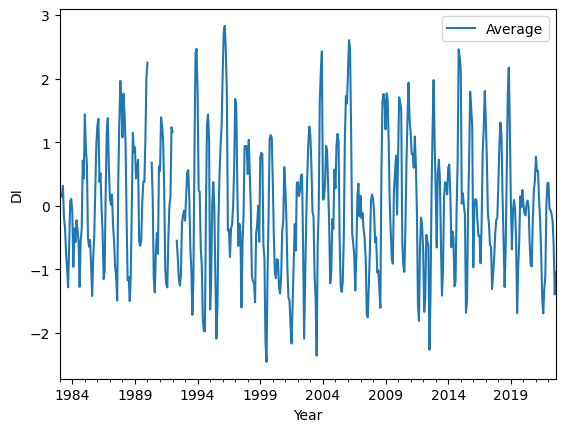

In [75]:
#plt.plot(dfmean['Dates'], dfmean['Average'])
dfmean.plot(xlabel='Year', ylabel='DI')

**Z-score index**

In [144]:
#Old calculation
pixels = list(p.columns)[1:]
ZSI=pd.DataFrame()
ZSI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    ZSI[pixel] =  (ma - ma.mean(skipna=True))/ma.std(skipna=True)

In [19]:
pixels = list(p.columns)[1:]
ZSI=pd.DataFrame()
ZSI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    pa = np.array([[np.nanmean(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    ps = np.array([[np.nanstd(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    ZSI[pixel] = (ma - pa)/ps

In [20]:
ZSI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.785759,-0.817734,-0.831120,-0.796258,-0.798043,-0.840869,-0.839434,-0.813938,-0.839344,-0.865858
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.834492,-0.863752,-0.869753,-0.832951,-0.838759,-0.893653,-0.927534,-0.894343,-0.906790,-0.909271
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.777452,-0.768410,-0.784088,-0.768239,-0.775338,-0.821896,-0.797461,-0.756850,-0.767445,-0.803366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.346696,1.367871,1.353608,1.408294,1.469773,1.542635,1.677415,1.758086,1.760925,1.818277
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.978380,1.977058,1.987627,1.992878,2.006930,1.992384,1.966431,1.978397,2.035971,2.001113
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.746715,1.732455,1.714388,1.678997,1.600661,1.537011,1.437507,1.280691,0.984500,0.603964
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.052258,-0.079030,-0.034843,-0.105576,-0.147802,-0.191650,-0.364985,-0.451579,-0.402123,-0.440487


In [21]:
ZSI.to_csv("outputchirps/ZSI.csv")

In [ ]:
dfmean = pd.DataFrame()
dfmean["Dates"]=ZSI["Dates"]
dfmean["Average"]=ZSI.mean(axis=1, skipna=True)
dfmean

In [110]:
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())

<Axes: xlabel='Year', ylabel='ZSI'>

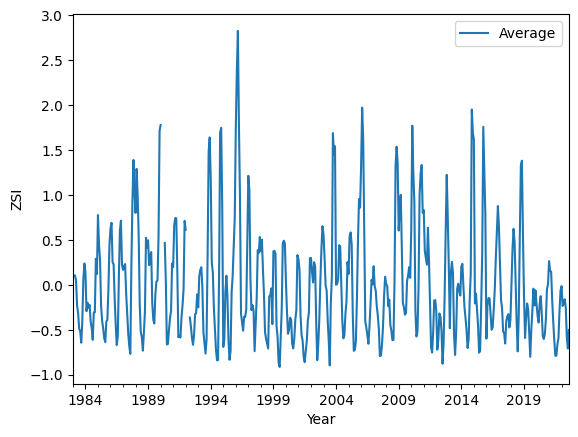

In [111]:
dfmean.plot(xlabel='Year', ylabel='ZSI')

**China Z-Index**

In [146]:
#Old calculation
pixels = list(p.columns)[1:]
CZI=pd.DataFrame()
CZI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    zsi = (ma - ma.mean(skipna=True))/ma.std(skipna=True)
    cs  = np.power(zsi, 3)/len(ma)
    CZI[pixel] =  6.0/cs*np.power((cs/2.0*zsi + 1.0), 1.0/3.0)-6.0/cs + cs/6.0

In [47]:
pixels = list(p.columns)[1:]
CZI=pd.DataFrame()
CZI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    pa = np.array([[np.nanmean(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    ps = np.array([[np.nanstd(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    zsi = (ma - pa)/ps
    cs  = np.power(zsi, 3)/len(ma)
    CZI[pixel] = (6.0/cs)*(np.power((1.0 + (cs/2.0)*zsi), 1.0/3.0)) - (6.0/cs) + (cs/6.0)
    #CZI[pixel] = cs

In [48]:
CZI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.785825,-0.817798,-0.831184,-0.796324,-0.798108,-0.840932,-0.839496,-0.814002,-0.839407,-0.865915
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.834554,-0.863811,-0.869810,-0.833014,-0.838822,-0.893705,-0.927573,-0.894394,-0.906838,-0.909318
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.777518,-0.768476,-0.784154,-0.768305,-0.775404,-0.821960,-0.797526,-0.756916,-0.767511,-0.803432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.345991,1.367081,1.352876,1.407321,1.468468,1.540841,1.674389,1.754074,1.756874,1.813386
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.970442,1.969149,1.979477,1.984606,1.998325,1.984123,1.958760,1.970458,2.026644,1.992646
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.742854,1.728779,1.710935,1.675954,1.598394,1.535259,1.436384,1.280214,0.984511,0.604014
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.052258,-0.079030,-0.034843,-0.105576,-0.147803,-0.191653,-0.365000,-0.451605,-0.402143,-0.440512


In [49]:
CZI.to_csv("outputchirps/CZI.csv")

<Axes: xlabel='Year', ylabel='CZI'>

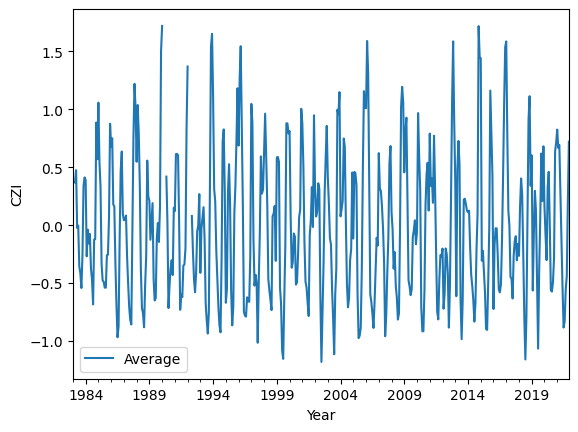

In [220]:
dfmean = pd.DataFrame()
dfmean["Dates"]=CZI["Dates"]
dfmean["Average"]=CZI.mean(axis=1, skipna=True)
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())
dfmean.plot(xlabel='Year', ylabel='CZI')

**RAI**

In [25]:
pixels = list(p.columns)[1:]
RAI=pd.DataFrame()
RAI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    y = ma.copy()
    x1 = ma.copy().sort_values(ascending=False).dropna()
    x_avg  = x1.mean()    
    mx_avg = x1.head(10).mean()
    mn_avg = x1.tail(10).mean()
    anom   = ma - x_avg

    rai_plus  = 3.0*anom[anom>=0]/(mx_avg-x_avg)
    rai_minus = -3.0*anom[anom<0]/(mn_avg-x_avg)     
    y.loc[anom>=0] = rai_plus.values
    y.loc[anom<0] = rai_minus.values
    RAI[pixel] =  y

In [26]:
RAI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.770215,-2.802785,-2.836609,-2.854491,-2.857376,-2.857542,-2.840056,-2.840293,-2.860735,-2.873107
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.883483,-2.907118,-2.925256,-2.944058,-2.954359,-2.976691,-2.977758,-2.975031,-2.980468,-2.970329
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.750908,-2.690960,-2.728688,-2.786096,-2.803296,-2.814713,-2.774451,-2.744630,-2.733098,-2.733161
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.032369,0.790072,0.649772,0.545453,0.547313,0.747074,0.825527,0.769243,0.667262,0.882737
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.565771,1.213952,1.055986,0.867339,0.819205,1.003501,0.988960,0.884346,0.797903,0.986761
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.370150,1.043754,0.880923,0.694509,0.613564,0.743867,0.689864,0.519824,0.298477,0.191859
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.629820,-0.975109,-1.042715,-1.375420,-1.450931,-1.333368,-1.885128,-2.215751,-2.069195,-2.098503


In [27]:
RAI.to_csv("outputchirps/RAI.csv")

<Axes: xlabel='Year', ylabel='RAI'>

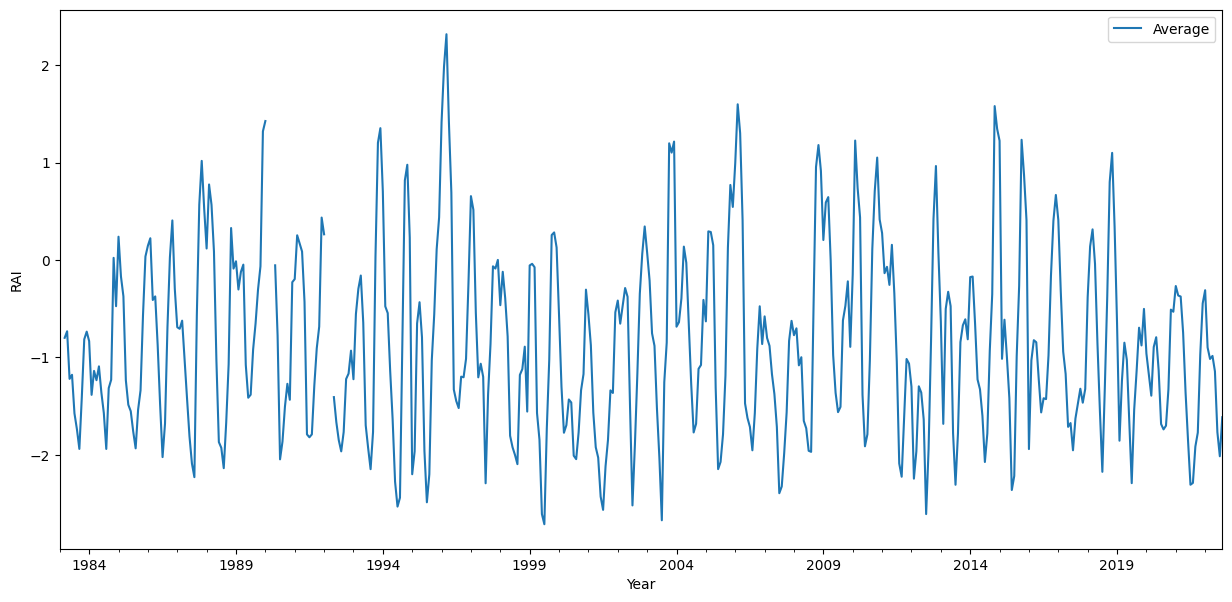

In [28]:
dfmean = pd.DataFrame()
dfmean["Dates"]=RAI["Dates"]
dfmean["Average"]=RAI.mean(axis=1, skipna=True)
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())
dfmean.plot(figsize=(15, 7), xlabel='Year', ylabel='RAI')

**SPI 3**

In [61]:
nans = list(dict.fromkeys(nans))
nans
#(1990-02-01, 1992-02-01, 1984-02-01, 1984-05-01, 1984-06-01)

[85, 109, 13, 16, 17]

In [28]:
spi = SPI()

In [29]:
def spi_value(p, pixel):
    return spi.calculate(
        p, 
        'Dates', 
        pixel, 
        freq="M", 
        scale=3,
        fit_type="lmom", 
        dist_type="gam"
    )

In [75]:
df_spi=spi_value(p, '4822')

In [76]:
df_spi

,Dates,4822_scale_3,4822_scale_3_calculated_index
0,1983-01-01,NaN,NaN
1,1983-02-01,NaN,NaN
2,1983-03-01,0.246599,0.045667
3,1983-04-01,0.246599,0.022404
4,1983-05-01,0.246599,-0.179676
...,...,...,...
471,2022-04-01,0.500907,0.207108
472,2022-05-01,1.356771,0.298157
473,2022-06-01,7.977522,0.561127
474,2022-07-01,23.897840,0.289689


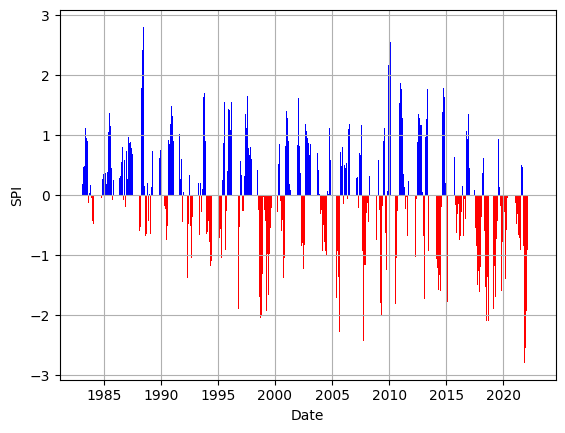

In [167]:
fig = plot_index(df_spi, 'Dates', '0_scale_3_calculated_index')

In [30]:
# Needs optimisation !!
pixels = list(p.columns)[1:]
spi_data=pd.DataFrame()
spi_data["Dates"]=p["Dates"]
for pixel in pixels:
    #fill missing data (-99.0) with a moving average (not a good idea for rainfall data)
    #ma = p[pixel].rolling(window=3 , min_periods=1).mean()
    #for i in range(476):
    #    if pd.isnull(p[pixel][i]):
    #        p[pixel][i] = ma[i]
    x = spi_value(p, pixel)
    spi_data[pixel] = x[pixel + '_scale_3_calculated_index']

In [31]:
df = spi_data[[str(i) for i in range(4824)]]
df.insert(0, 'Dates', p["Dates"])
df

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.514597,-0.540595,-0.557972,-0.530734,-0.507785,-0.519451,-0.495876,-0.497043,-0.527725,-0.596167
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.611205,-0.634696,-0.639515,-0.615881,-0.604126,-0.650685,-0.656984,-0.663574,-0.683568,-0.741117
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.499722,-0.455234,-0.473097,-0.474293,-0.461537,-0.480250,-0.436035,-0.408987,-0.407479,-0.449154
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.141504,1.039796,0.939712,0.910360,0.956437,1.105808,1.173874,1.142616,1.077444,1.171010
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.394595,1.269465,1.166426,1.106432,1.132052,1.259819,1.270882,1.212892,1.161167,1.229403
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.306327,1.181388,1.073079,1.004727,1.001439,1.103770,1.087801,0.975961,0.805076,0.694768
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.321702,0.235861,0.219539,0.152617,0.152811,0.191975,0.033005,-0.092467,-0.034770,-0.068291


In [933]:
dfmean = pd.DataFrame()
dfmean["Dates"]=df["Dates"]
dfmean["Average"]=df.mean(axis=1, skipna=True)
dfmean

,Dates,Average
0,01-01-83,NaN
1,01-02-83,NaN
2,01-03-83,0.090936
3,01-04-83,0.171679
4,01-05-83,-0.121787
...,...,...
463,01-08-21,-1.004478
464,01-09-21,-0.726878
465,01-10-21,-0.611393
466,01-11-21,-0.051201


In [133]:
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())

<Axes: xlabel='Year', ylabel='SPI3'>

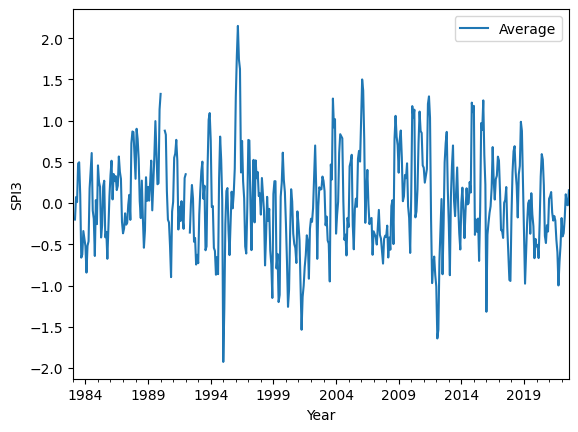

In [134]:
#plt.plot(dfmean['Dates'], dfmean['Average'])
dfmean.plot(xlabel='Year', ylabel='SPI3')
#fig = plot_index(dfmean, 'Dates', 'Average')

In [32]:
df.to_csv("outputchirps/SPI3.csv")

**SPEI**

In [ ]:
#see SPEI_package in R studio

In [161]:
spei = pd.read_csv('spei3_thorthwaite.csv', low_memory=False)

In [163]:
spei = spei.drop(columns='Unnamed: 0')
spei

,Dates,spei3$fitted,spei3$fitted.1,spei3$fitted.2,spei3$fitted.3,spei3$fitted.4,spei3$fitted.5,spei3$fitted.6,spei3$fitted.7,spei3$fitted.8,...,spei3$fitted.4814,spei3$fitted.4815,spei3$fitted.4816,spei3$fitted.4817,spei3$fitted.4818,spei3$fitted.4819,spei3$fitted.4820,spei3$fitted.4821,spei3$fitted.4822,spei3$fitted.4823
0,1983-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1983-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1983-03-01,0.266574,0.171241,0.037820,0.075758,0.063070,0.153254,0.157710,0.236095,-0.023911,...,0.500481,0.578952,0.634251,0.660912,0.770060,0.803850,0.859592,0.915240,0.968892,1.064163
3,1983-04-01,0.602232,0.533202,0.747785,0.784670,0.781340,0.499433,0.678306,0.655357,0.372343,...,-0.189733,-0.144631,-0.085641,-0.051326,0.067125,0.118371,0.211062,0.293303,0.381153,0.507308
4,1983-05-01,0.724621,0.916248,1.048500,1.160215,1.213706,0.810783,0.834465,1.009732,0.575250,...,-0.828575,-0.781231,-0.709800,-0.679139,-0.650587,-0.607287,-0.552720,-0.491976,-0.454987,-0.400318
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471,2022-04-01,-0.490763,-0.512699,-0.487312,-0.685110,-0.409628,-0.296691,-0.403401,-0.488757,-0.413724,...,0.125572,0.144508,0.125746,0.111184,0.165310,0.142696,0.112295,0.077251,0.045194,-0.021504
472,2022-05-01,0.221295,-0.028520,-0.084371,-0.237974,0.251254,0.178479,0.015660,-0.159311,-0.040024,...,0.492186,0.527347,0.502225,0.501621,0.518809,0.528879,0.503839,0.456888,0.446283,0.441143
473,2022-06-01,0.201983,0.032350,0.078069,-0.104813,0.078264,-0.091661,-0.144669,-0.381430,-0.121536,...,0.523078,0.563041,0.539238,0.568855,0.696780,0.728207,0.701552,0.650300,0.664925,0.707084
474,2022-07-01,0.713291,0.533308,0.449680,0.220636,0.473998,0.251753,0.244248,0.184900,0.153823,...,0.288588,0.267801,0.215166,0.278259,0.537283,0.536638,0.540905,0.532145,0.534922,0.528474


In [164]:
speimean = pd.DataFrame()
speimean["Dates"]=spei["Dates"]
speimean["Average"]=spei.mean(axis=1, skipna=True)
speimean

,Dates,Average
0,1983-01-01,NaN
1,1983-02-01,NaN
2,1983-03-01,-0.122181
3,1983-04-01,-0.023228
4,1983-05-01,-0.079087
...,...,...
471,2022-04-01,0.021819
472,2022-05-01,-0.123980
473,2022-06-01,-0.649486
474,2022-07-01,-0.976145


In [165]:
speimean = speimean.reset_index(drop=True)
speimean.set_index('Dates', inplace = True)
speimean.index = pd.to_datetime(speimean.index.to_numpy())

<Axes: xlabel='Year', ylabel='SPEI3'>

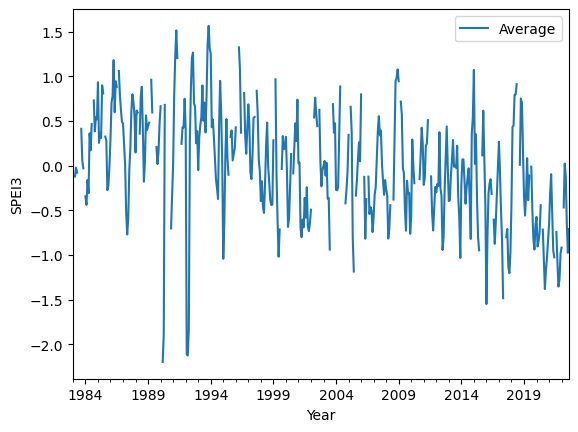

In [167]:
speimean.plot(xlabel='Year', ylabel='SPEI3')

**Drought indices analysis**

**aridity categories**

In [28]:
p = pd.read_csv('precip_chirps.csv', low_memory=False)
p = p.drop(['Dates'], axis=1)
p = p.replace([-99],[np.nan])
p = p[:-8]
pet = pd.read_csv('outputchirps/PEthorn.csv', low_memory=False)
pet = pet.drop(['Unnamed: 0'], axis=1)

In [30]:
pixels = list(p.columns)[0:]
AI=[]
for pixel in pixels:
    pa = [sum(p[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    peta = [sum(pet[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    p_pet = [pa[i]/peta[i] for i in range(39)]
    AI.append(np.nanmean(p_pet))

In [31]:
AI_classes = []
for i in AI:
    if i <= 0.05: AI_classes.append(5) #Hyper-arid climate zone
    elif 0.05 < i <= 0.2 : AI_classes.append(4) #Arid climate zone
    elif 0.2 < i <= 0.5 : AI_classes.append(3) #Semi-arid climate zone
    elif 0.5 < i <= 0.75 : AI_classes.append(2) #Sub-humid climate zone
    else : AI_classes.append(1) #Humid climate zone

In [21]:
shp = pd.read_csv('shapfiles/01shp_ext.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

<Figure size 640x480 with 0 Axes>

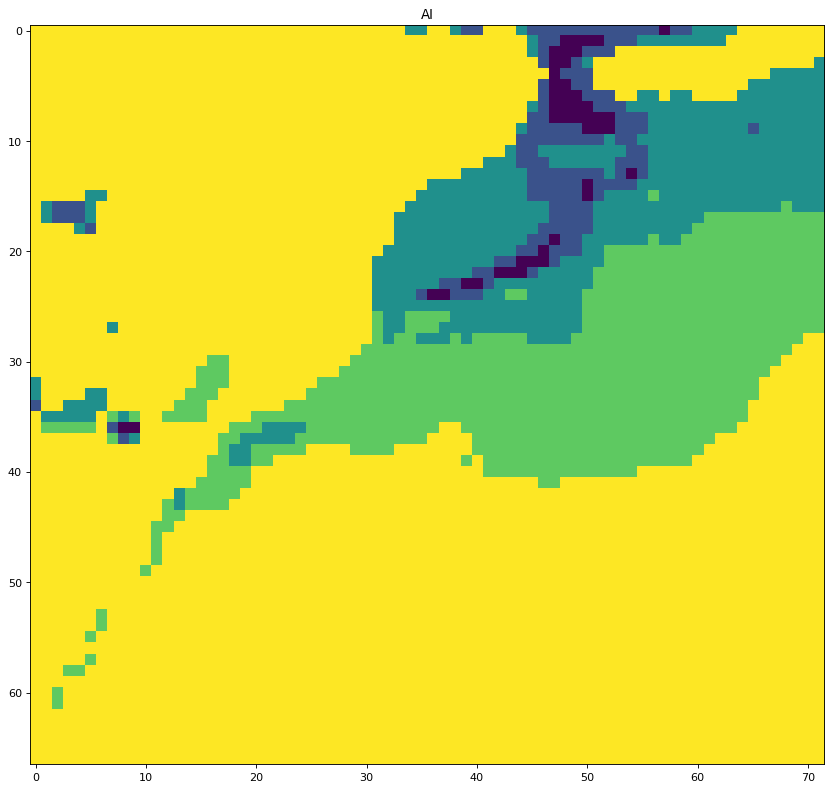

In [33]:
I = np.array(AI_classes)
I = np.reshape(I, (-1, 72))
#I = I*shp
#I = I.flatten()

plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.title('AI')
plt.imshow(I)

In [34]:
# export
driver = gdal.GetDriverByName("GTiff")
driver.Register()
outds = driver.Create("outputchirps/AI.tif", xsize = I.shape[1],
                      ysize = I.shape[0], bands = 1, 
                      eType = gdal.GDT_Float32)

gt = [-17.875, 0.25, 0, 37.125, 0, -0.25]
outds.SetGeoTransform(gt)

# Get raster projection
epsg = 4326
srs = osr.SpatialReference()
srs.ImportFromEPSG(epsg)
proj = srs.ExportToWkt()
outds.SetProjection(proj)

outband = outds.GetRasterBand(1)
outband.WriteArray(I)
outband.SetNoDataValue(np.nan)
outband.FlushCache()

# close your datasets and bands!!!
outband = None
outds = None

**trend significance map**

In [159]:
SPI = pd.read_csv('output/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI[:-8]
SPI = SPI.drop(['Dates'], axis=1)
SPI.columns = [str(i) for i in range(4824)]

SPEI = pd.read_csv('output/spei.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI.columns = [str(i) for i in range(4824)]

mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)

PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)

In [162]:
pixels = list(p.columns)[1:]
ptrend=[]
ttrend=[]
spitrend=[]
speitrend=[]
scpdsitrend=[]
pzitrend=[]

lat = [[37 - 0.25*i]*72 for i in range(67)]
lat = np.reshape(lat, (-1,4824))
lon = [0.25*i - 17.75 for i in range(72)]*67
for pixel in pixels:
    ptrend.append(mk.original_test(p[pixel]).z)
    ttrend.append(mk.original_test(t[pixel]).z)
    spitrend.append(mk.original_test(SPI[pixel]).z)
    speitrend.append(mk.original_test(SPEI[pixel]).z)
    scpdsitrend.append(mk.original_test(mPDSI[pixel]).z)
    pzitrend.append(mk.original_test(PalmerZ[pixel]).z)

C = pd.DataFrame()
C['Lat'] = pd.Series(lat[0])
C['Lon'] = pd.Series(lon)
C['pZ'] = pd.Series(ptrend)
C['tZ'] = pd.Series(ttrend)
C['spiZ'] = pd.Series(spitrend)
C['speiZ'] = pd.Series(speitrend)
C['scpdsiZ'] = pd.Series(scpdsitrend)
C['pziZ'] = pd.Series(pzitrend)
C['Coordinates'] = C[['Lon', 'Lat']].values.tolist()
C['Coordinates'] = C['Coordinates'].apply(Point)
trends = gpd.GeoDataFrame(C, geometry = 'Coordinates')
trends = trends.set_crs('epsg:4326')

trends.to_file('output/mkZ.shp')

**Morocco**

In [79]:
avgs.to_csv("output/pt_avgs.csv")

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.6457450970456375, z=0.45968115637214557, Tau=0.05263157894736842, s=39.0, var_s=6833.666666666667, slope=0.1816059073104719, intercept=188.42474552910505)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=4.812539262810667e-05, z=4.064549172132655, Tau=0.45479082321187586, s=337.0, var_s=6833.666666666667, slope=0.026333258114481506, intercept=19.662358510398025)


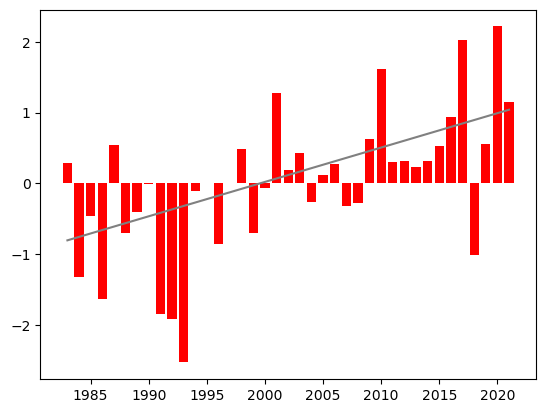

In [73]:
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp = shp.flatten()

annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shp)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shp)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['Precipitation'] = (pa - np.mean(pa))/np.std(pa) 
avgs['Temperature'] = (ta - np.mean(ta))/np.std(ta) 
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%YYYY/%m/%d').year

plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 100
#avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), kind='bar', grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in Morocco')
#avgs.loc[:,['Temperature']].plot(figsize = (15,5), kind='bar', xlabel='Year', color='orange', title='Temperature variation in Morocco')

# Sen's slope
from scipy.stats import theilslopes
y = avgs.loc[:,['Temperature']]
x = avgs.index
slp, intcp, lo, hi = theilslopes(y, x)

# Plot
y2 = slp*x + intcp
plt.bar(x, height=avgs['Temperature'], color='red') 
plt.plot(x, y2, color='grey')

#avgs.loc[:,['t']].plot(figsize = (20,5), kind='bar', grid=True, xlabel='Year', title='Temperature variation in Morocco')
ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)
#avgs

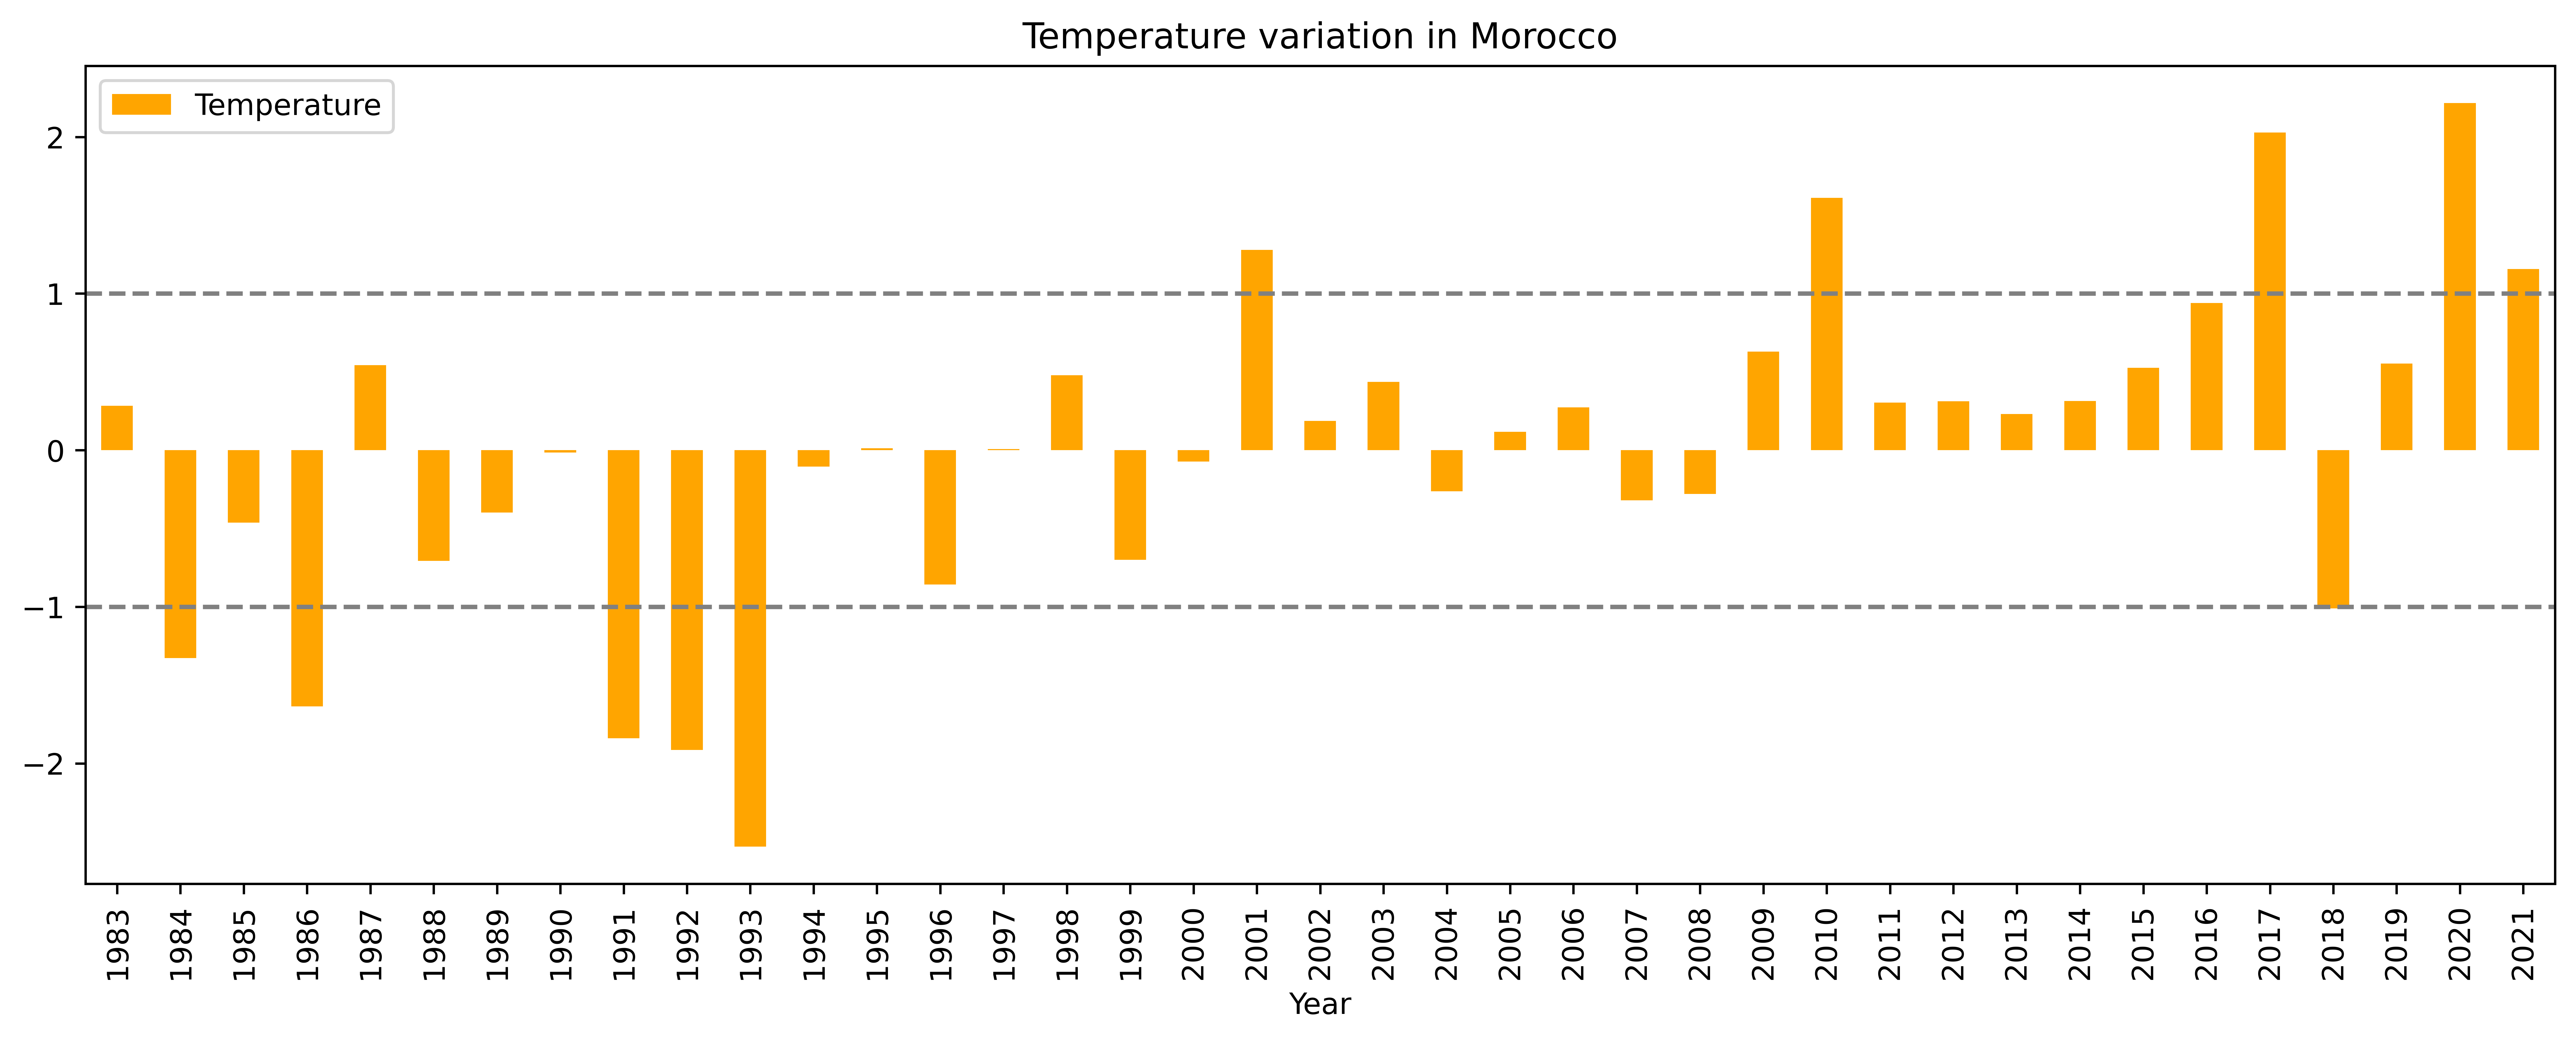

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.7348263750767032, z=-0.33871243101105464, Tau=-0.03913630229419703, s=-29.0, var_s=6833.666666666667, slope=-0.3336473135127349, intercept=205.9910593559312)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=4.812539262810667e-05, z=4.064549172132655, Tau=0.45479082321187586, s=337.0, var_s=6833.666666666667, slope=0.026333258114481506, intercept=19.662358510398025)


In [62]:
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp = shp.flatten()

annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shp)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shp)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['Precipitation'] = (pa - np.mean(pa))/np.std(pa) 
avgs['Temperature'] = (ta - np.mean(ta))/np.std(ta) 
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%YYYY/%m/%d').year

plt.rcParams['figure.dpi'] = 800
plt.rcParams['savefig.dpi'] = 800
#avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), kind='bar', grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in Morocco')
ax = avgs.loc[:,['Temperature']].plot(figsize = (15,5), kind='bar', xlabel='Year', color='orange', title='Temperature variation in Morocco')
ax.axhline(y=1, color='grey', ls='--')
ax.axhline(y=-1, color='grey', ls='--')

# Sen's slope
from scipy.stats import theilslopes
y = avgs.loc[:,['Temperature']]
x = avgs.index
slp, intcp, lo, hi = theilslopes(y, x)

# Plot
y2 = slp*x + intcp
ax.plot(x, y2, color='black')
plt.show()

#avgs.loc[:,['t']].plot(figsize = (20,5), kind='bar', grid=True, xlabel='Year', title='Temperature variation in Morocco')
ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)
#avgs

In [220]:
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp = shp.flatten()

DI_ma = pd.DataFrame()
DI_ma["Dates"]=p["Dates"]
DI = pd.read_csv('outputchirps/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
#DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shp)
DI = DI.replace(0, np.nan)
DI_ma["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('outputchirps/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shp)
PNI = PNI.replace(0, np.nan)
DI_ma["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('outputchirps/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
#RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shp)
RAI = RAI.replace(0, np.nan)
DI_ma["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('outputchirps/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shp)
ZSI = ZSI.replace(0, np.nan)
DI_ma["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('outputchirps/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shp)
CZI = CZI.replace(0, np.nan)
DI_ma["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('outputchirps/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shp)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_ma["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('outputchirps/SPEI.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
#SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shp)
SPEI = SPEI.replace(np.Inf, np.nan)
SPEI = SPEI.replace(-np.Inf, np.nan)
SPEI = SPEI.replace(0, np.nan)
DI_ma["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('outputchirps/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shp)
PDSI = PDSI.replace(0, np.nan)
DI_ma["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('outputchirps/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shp)
mPDSI = mPDSI.replace(0, np.nan)
DI_ma["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('outputchirps/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shp)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_ma["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_ma = DI_ma[2:]
DI_ma

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
2,01-03-83,0.025641,0.862069,-0.243095,0.600159,0.599966,-0.182767,-0.481573,-0.769559,-0.774470,-1.514630
3,01-04-83,0.988506,0.634877,-0.440554,0.424530,0.424330,0.019836,-0.398533,-0.730758,-0.791624,-0.431808
4,01-05-83,-0.532000,-0.003247,-0.798486,0.147337,0.147168,0.716134,0.025765,-0.341293,-0.300174,0.577040
5,01-06-83,-1.000000,-1.042328,-1.424595,-0.325290,-0.325294,1.486410,0.487693,-0.217128,-0.129532,0.272342
6,01-07-83,-1.243023,-2.060573,-2.099500,-0.841144,-0.840975,1.553864,0.947716,-0.427822,-0.150345,-0.093791
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.398907,-2.664688,-2.550802,-1.136267,-1.135690,0.131389,-0.049136,-2.150356,-1.760865,-1.055940
464,01-09-21,-1.380562,-1.720497,-1.668050,-0.513414,-0.513232,-0.575475,-0.824135,-2.253849,-2.087879,-1.314946
465,01-10-21,-0.475390,-1.240206,-1.221999,-0.162933,-0.163572,-1.031643,-1.199914,-2.917636,-2.888578,-2.645090
466,01-11-21,1.151134,0.031566,-0.392877,0.354141,0.353372,-0.716604,-0.815424,-2.505103,-2.251099,0.256661


In [221]:
DI_ma.to_csv('outputchirps/DI_ma.csv')

In [62]:
DIc_ma = pd.DataFrame()
DIc_ma['Dates'] = DI_ma['Dates']
#DIc_ma['DI'] = DI_ma['DI'].round(0)

index = DI_ma['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['DI'] = ic

DIc_ma['PNI'] = DI_ma['PNI'].round(0)

index = DI_ma['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['RAI'] = ic

index = DI_ma['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['ZSI'] = ic

index = DI_ma['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['CZI'] = ic

index = DI_ma['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['SPI'] = ic

index = DI_ma['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['SPEI'] = ic

index = DI_ma['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['PDSI'] = ic

index = DI_ma['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['scPDSI'] = ic

index = DI_ma['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['PZI'] = ic
DIc_ma

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.0,NaN,NaN,NaN,NaN,NaN,0,0,0
1,01-02-83,NaN,1.0,NaN,NaN,NaN,NaN,NaN,0,0,0
2,01-03-83,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,-1
3,01-04-83,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0,0,0
4,01-05-83,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,0.0,-1,-1,-1
464,01-09-21,-1.0,-2.0,-1.0,0.0,0.0,0.0,0.0,-1,-1,-1
465,01-10-21,0.0,-1.0,-1.0,0.0,0.0,-1.0,-1.0,-1,-1,-1
466,01-11-21,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,0


In [63]:
DI_ma['rand'] = (np.random.rand(len(DI_ma)))/5
DI_ma['CZI'] = DI_ma['CZI'].sub(DI_ma['rand'])
DI_ma['rand'] = (np.random.rand(len(DI_ma)))/5
DI_ma['ZSI'] = DI_ma['ZSI'].sub(DI_ma['rand'])
DI_ma = DI_ma.drop(['rand'], axis=1)

DI_ma

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.153776,-0.153776,-0.461327
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.251218,-0.222009,-0.252319
2,01-03-83,0.025641,0.862069,-0.243095,0.475032,0.595751,-0.182767,-0.481573,-0.769559,-0.774470,-1.514630
3,01-04-83,0.988506,0.634877,-0.440554,0.363772,0.357218,0.019836,-0.398533,-0.730758,-0.791624,-0.431808
4,01-05-83,-0.532000,-0.003247,-0.798486,0.060973,-0.004677,0.716134,0.025765,-0.341293,-0.300174,0.577040
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.398907,-2.664688,-2.550802,-1.266024,-1.201606,0.131389,-0.049136,-2.150356,-1.760865,-1.055940
464,01-09-21,-1.380562,-1.720497,-1.668050,-0.518090,-0.660955,-0.575475,-0.824135,-2.253849,-2.087879,-1.314946
465,01-10-21,-0.475390,-1.240206,-1.221999,-0.184841,-0.195809,-1.031643,-1.199914,-2.917636,-2.888578,-2.645090
466,01-11-21,1.151134,0.031566,-0.392877,0.280891,0.180022,-0.716604,-0.815424,-2.505103,-2.251099,0.256661


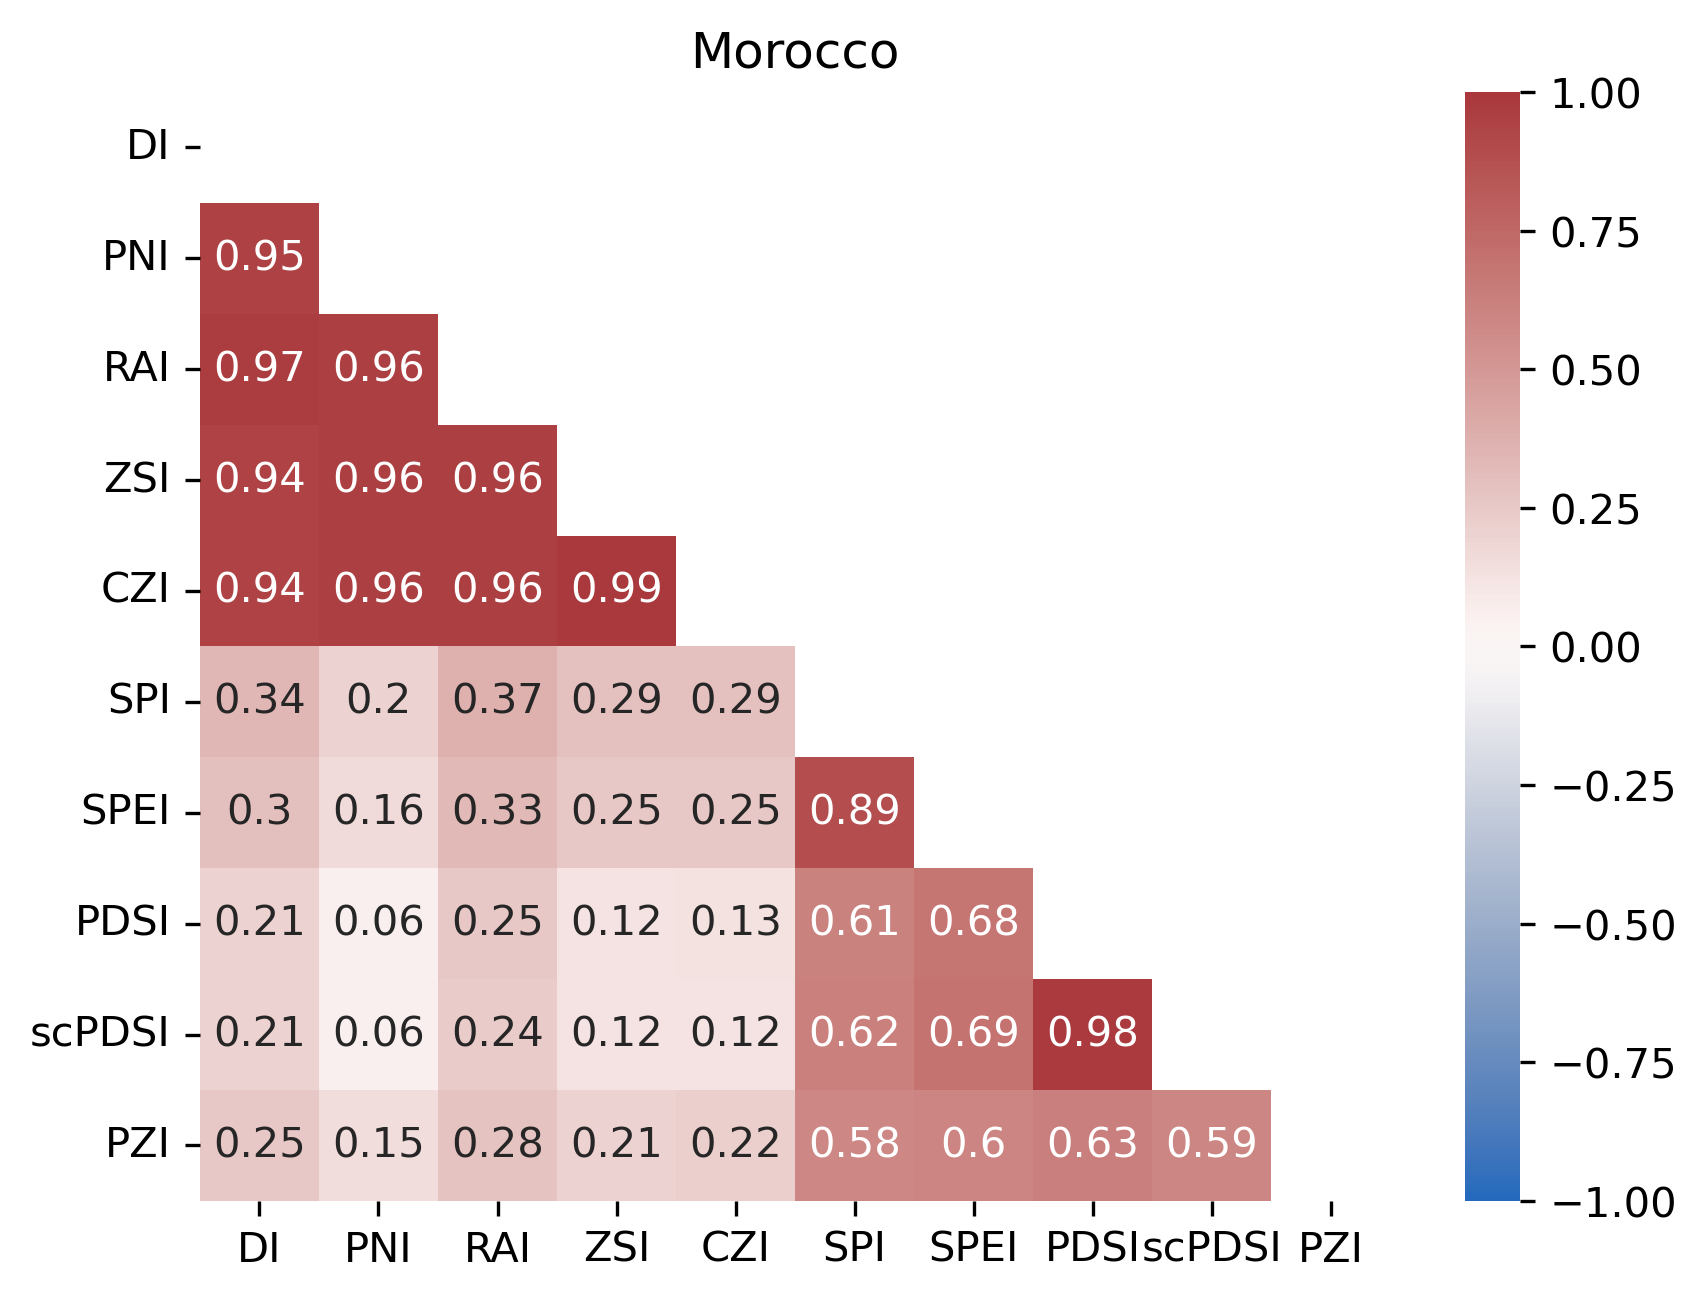

In [56]:
#DI_ma = DI_ma.drop(['Dates'], axis=1)
DI_ma.replace([np.inf, -np.inf], np.nan, inplace=True)
DI_ma.dropna()
#pvalue = calculate_pvalues(DI_ma)
matrix = DI_ma.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
#pvalue = pvalue.astype(float).round(3)
#sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Morocco")
plt.show()

<AxesSubplot:title={'center':'Morocco'}, ylabel='Value'>

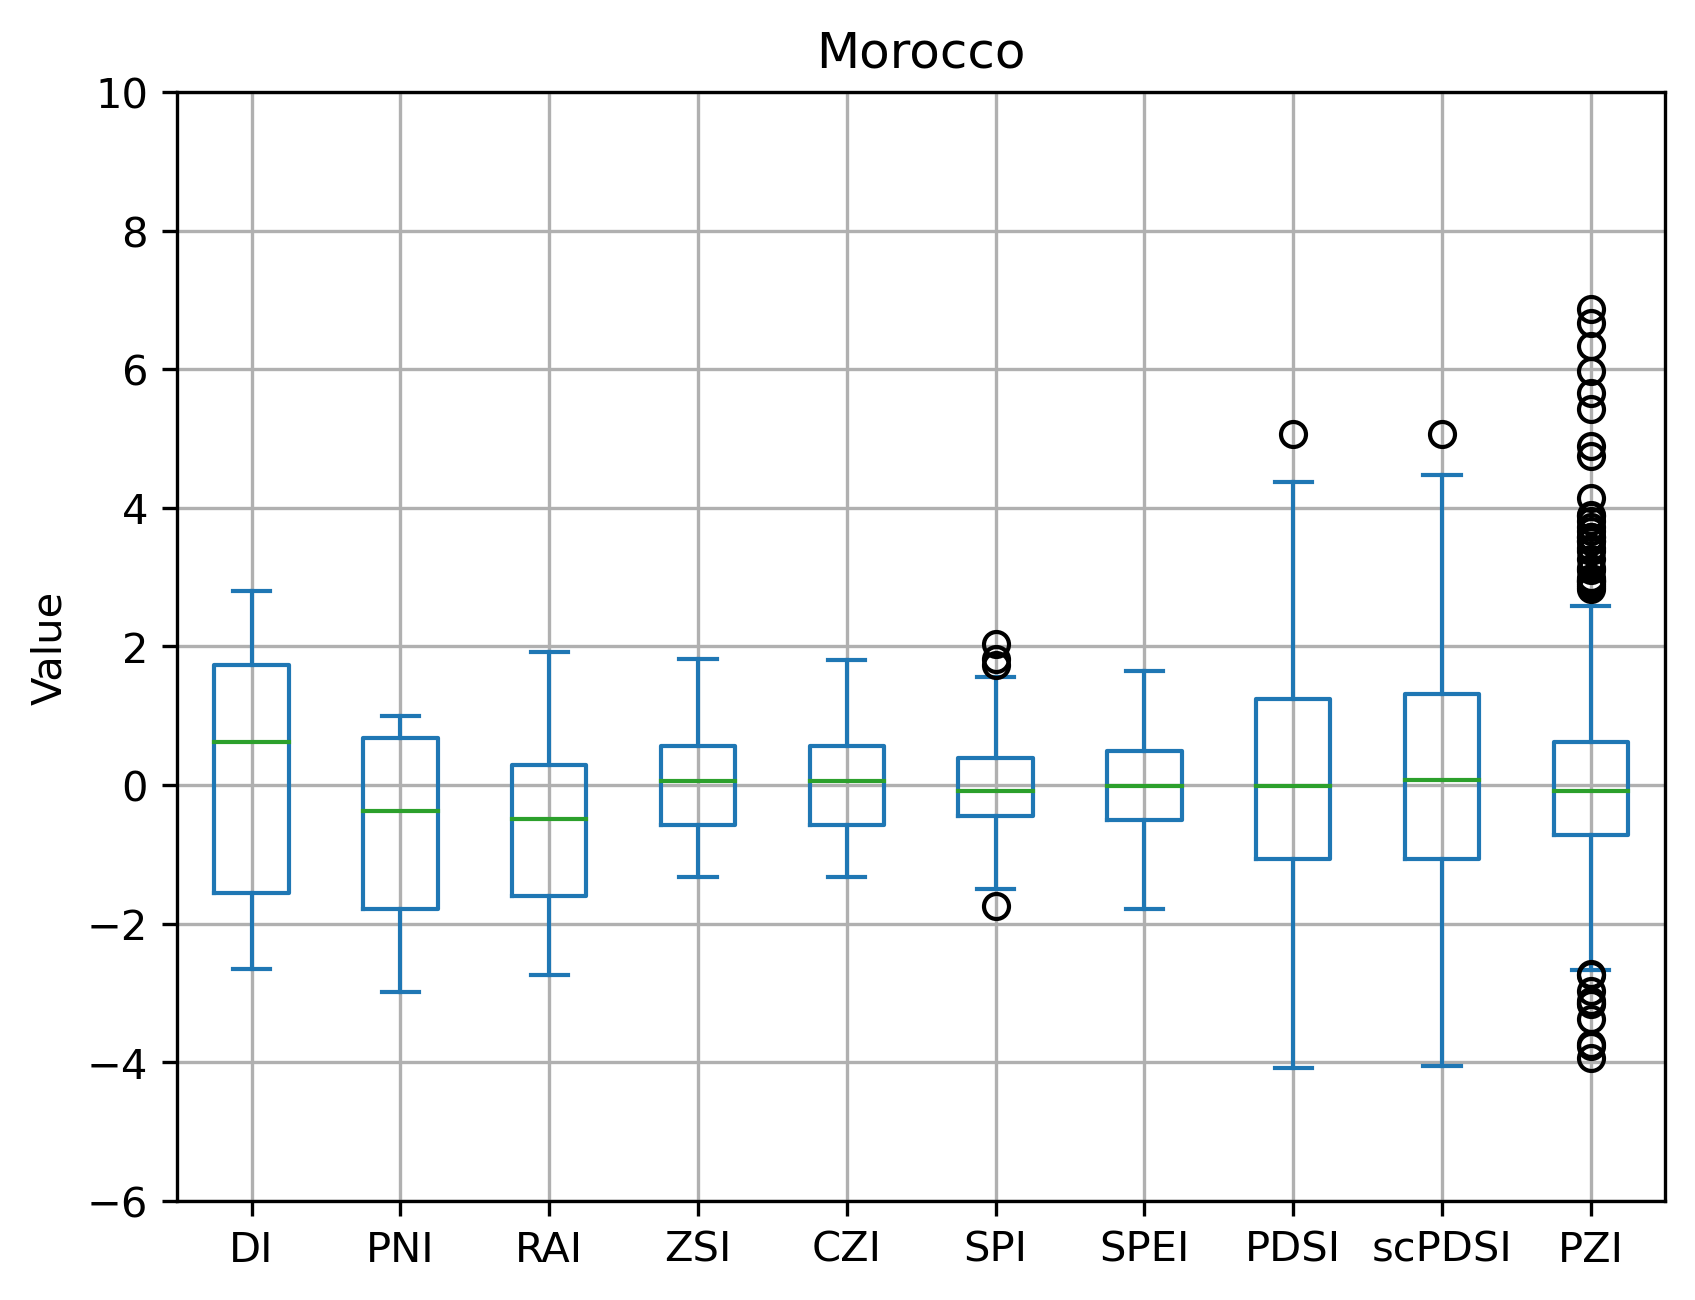

In [52]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
DI_ma.plot(kind='box', title='Morocco', grid = True, ylim = (-6, 10), ylabel='Value')

<AxesSubplot:xlabel='Month'>

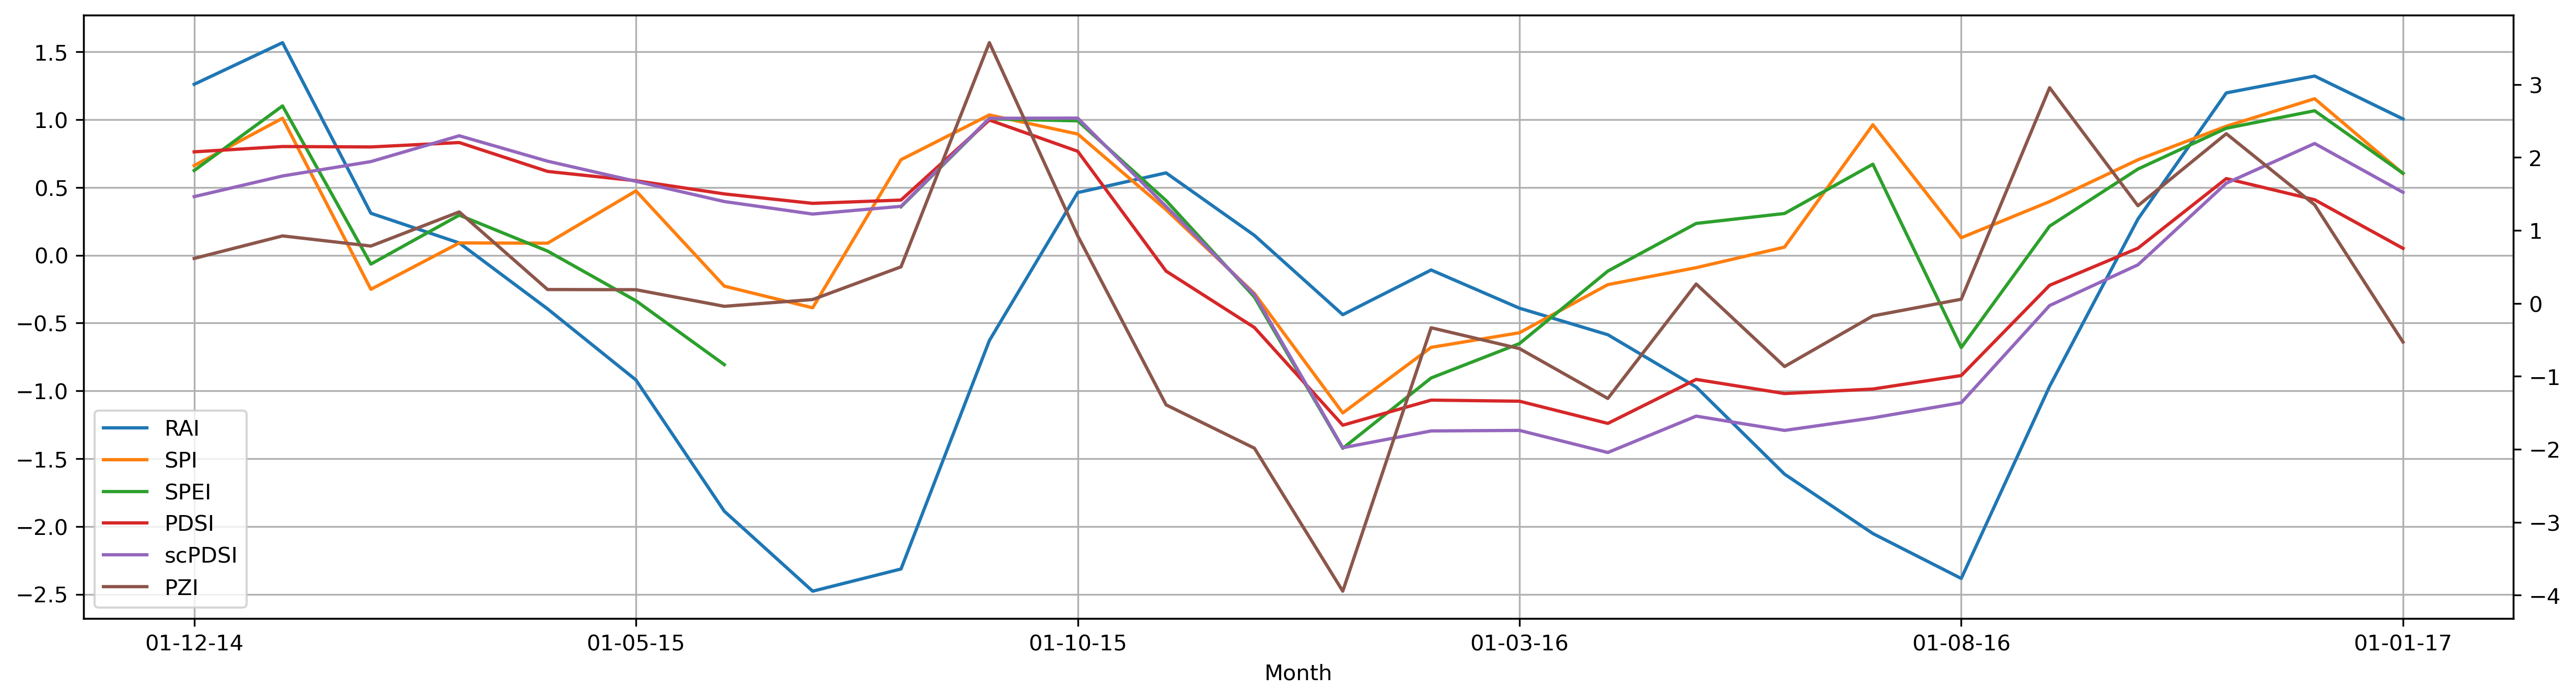

In [72]:
#DI_ma.set_index("Dates", inplace = True)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
#DI_ma.index = pd.to_datetime(DI_ma.index, format='%d/%mm/%YY')
DI_ma[383:409].loc[:,['RAI','SPI','SPEI','PDSI','scPDSI','PZI']].plot(secondary_y=['PDSI','scPDSI', 'PZI'], mark_right=False, grid=True, figsize = (20,5), xlabel='Month') #DI_ma[383:409] for the period 2014-2016 and [131:157] for the 1994-1996

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.9229050934914809, z=0.09677498028887276, Tau=0.012145748987854251, s=9.0, var_s=6833.666666666667, slope=0.00026471073256137954, intercept=-0.6385020499243323)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.9037158067879054, z=-0.12096872536109095, Tau=-0.014844804318488529, s=-11.0, var_s=6833.666666666667, slope=-0.0006108876344017288, intercept=0.02885225775571127)
SPEI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.005402514040003137, z=-2.781999397454505, Tau=-0.30229419703103916, s=-224.0, var_s=6425.333333333333, slope=-0.07463888224783019, intercept=1.2435405292649344)
scPDSI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.04463470183324292, z=-2.0080808409941096, Tau=-0.2253711201079622, s=-167.0, var_s=6833.666666666667, slope=-0.048913923744293104, intercept=0.9226186045295751)
PZI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.1466059857808104, z=-1.4516247043330912, Tau=-0.1632928475033738, s=

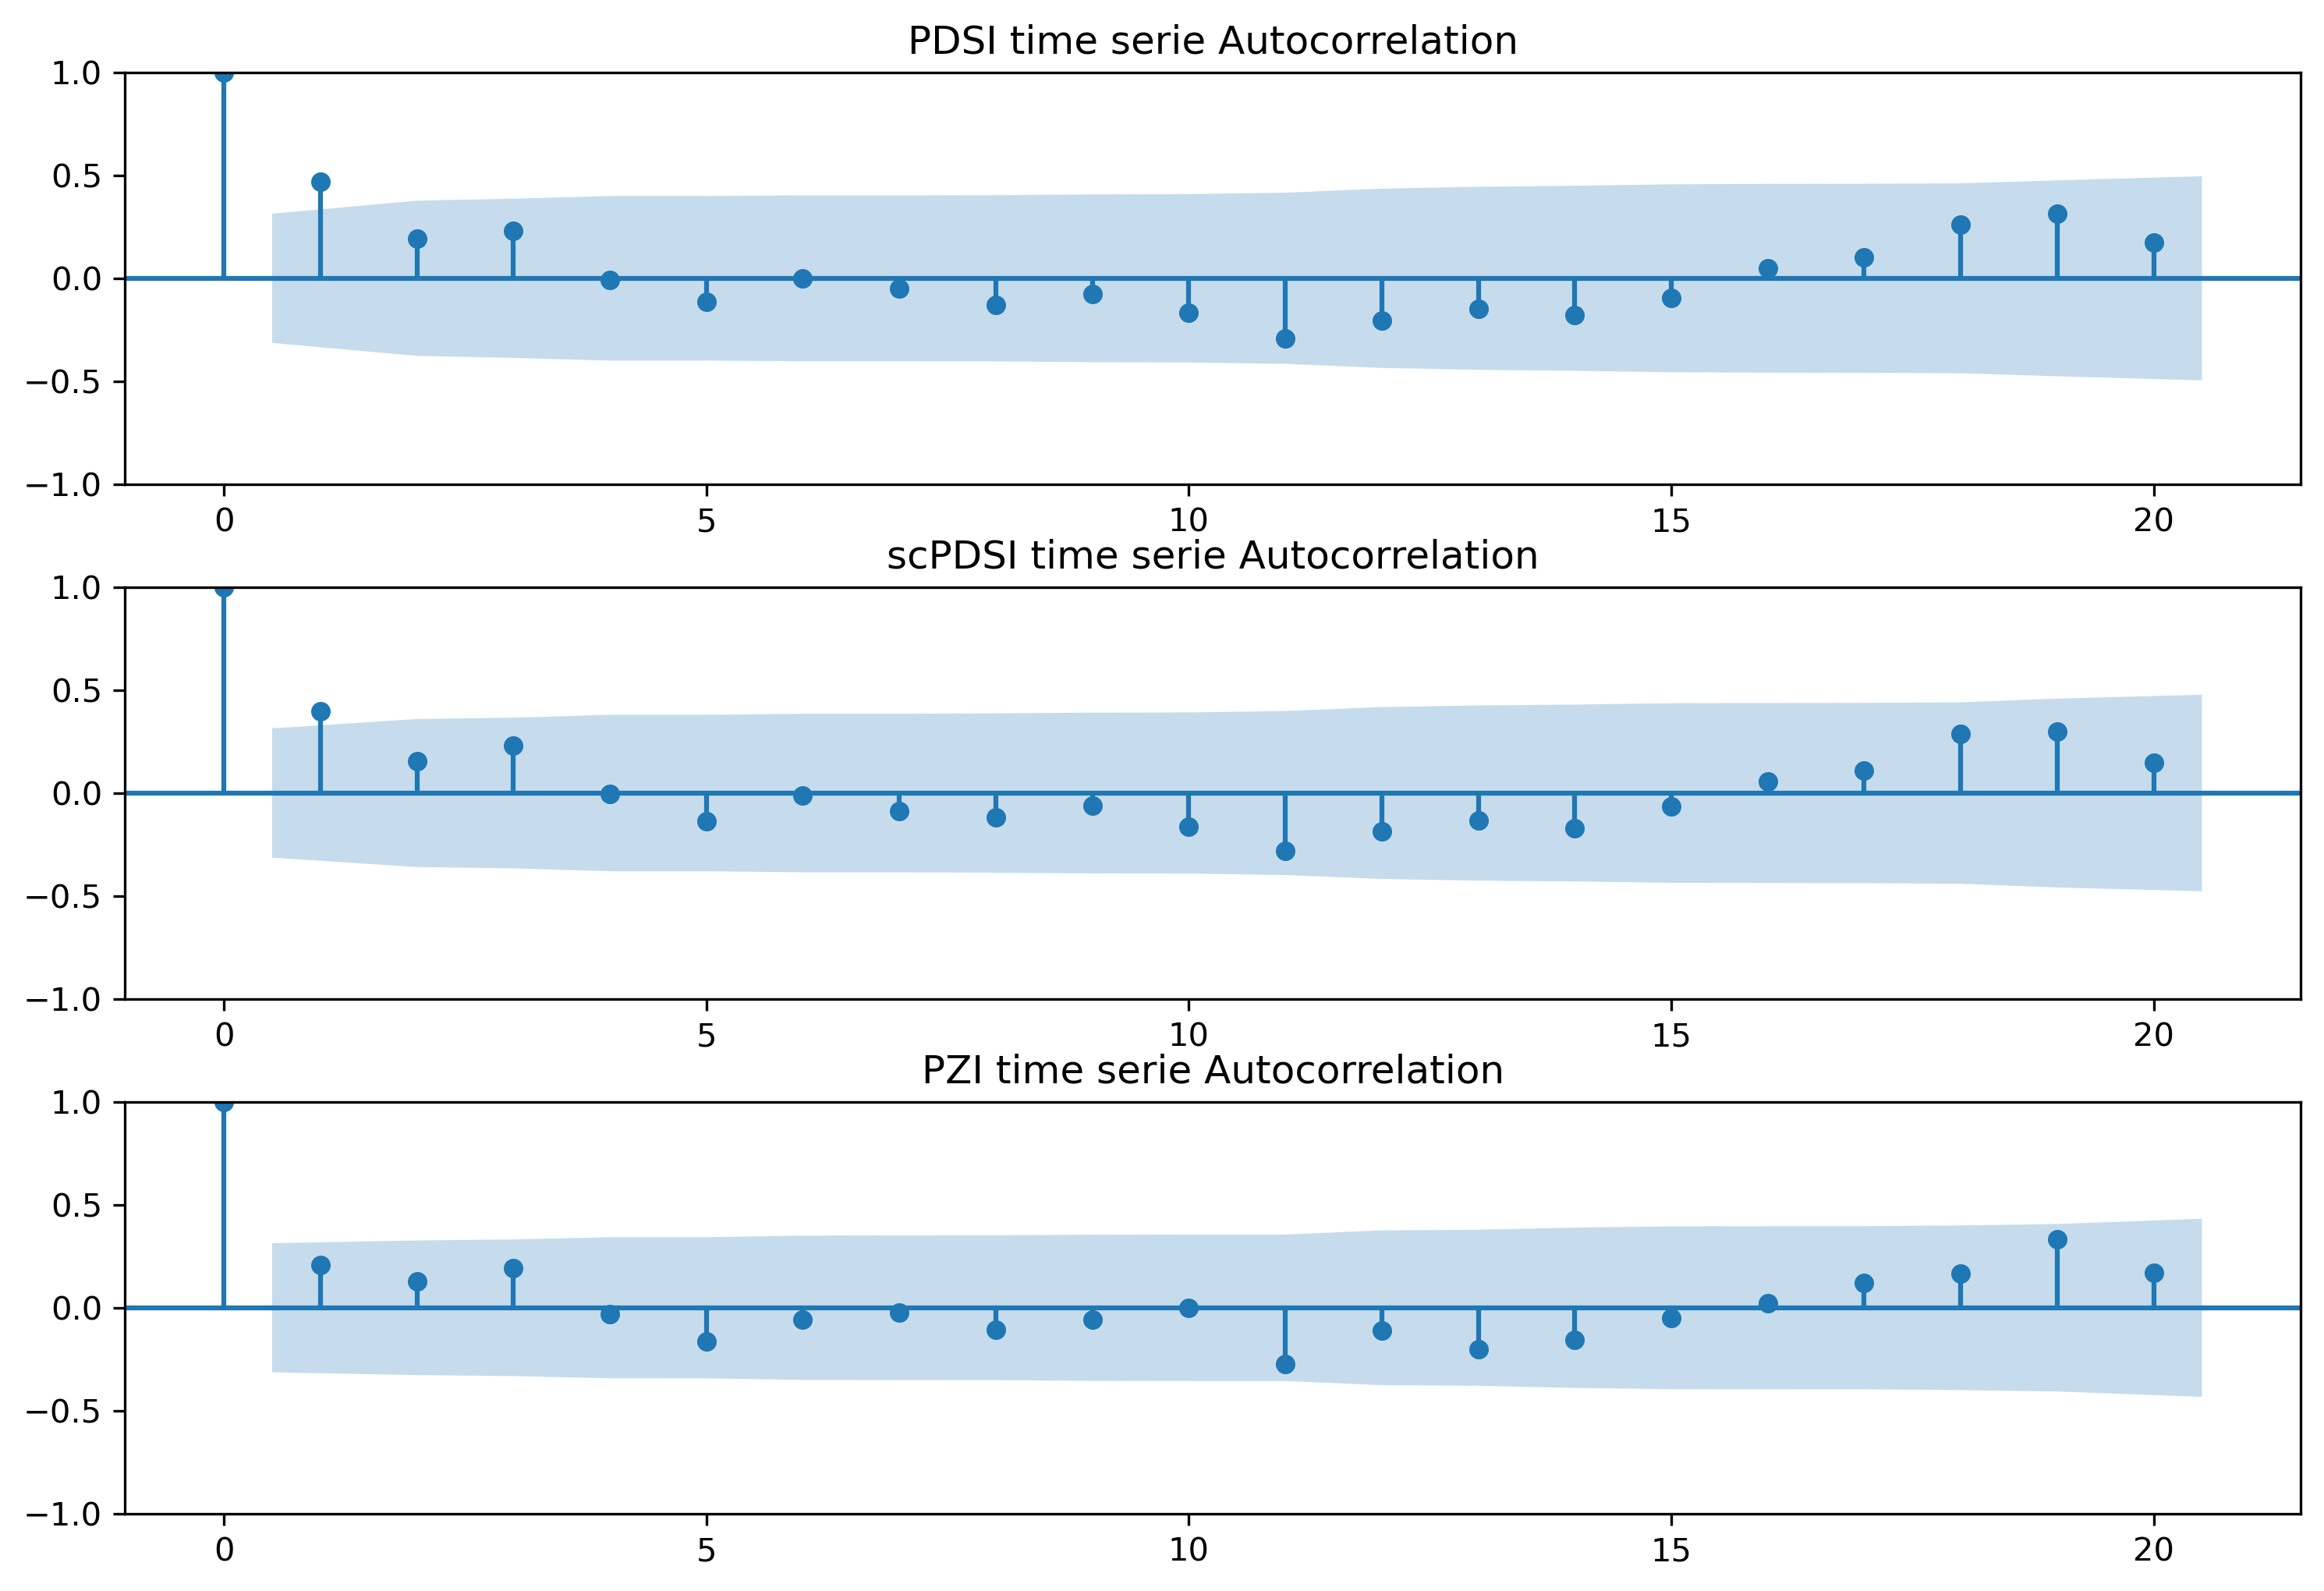

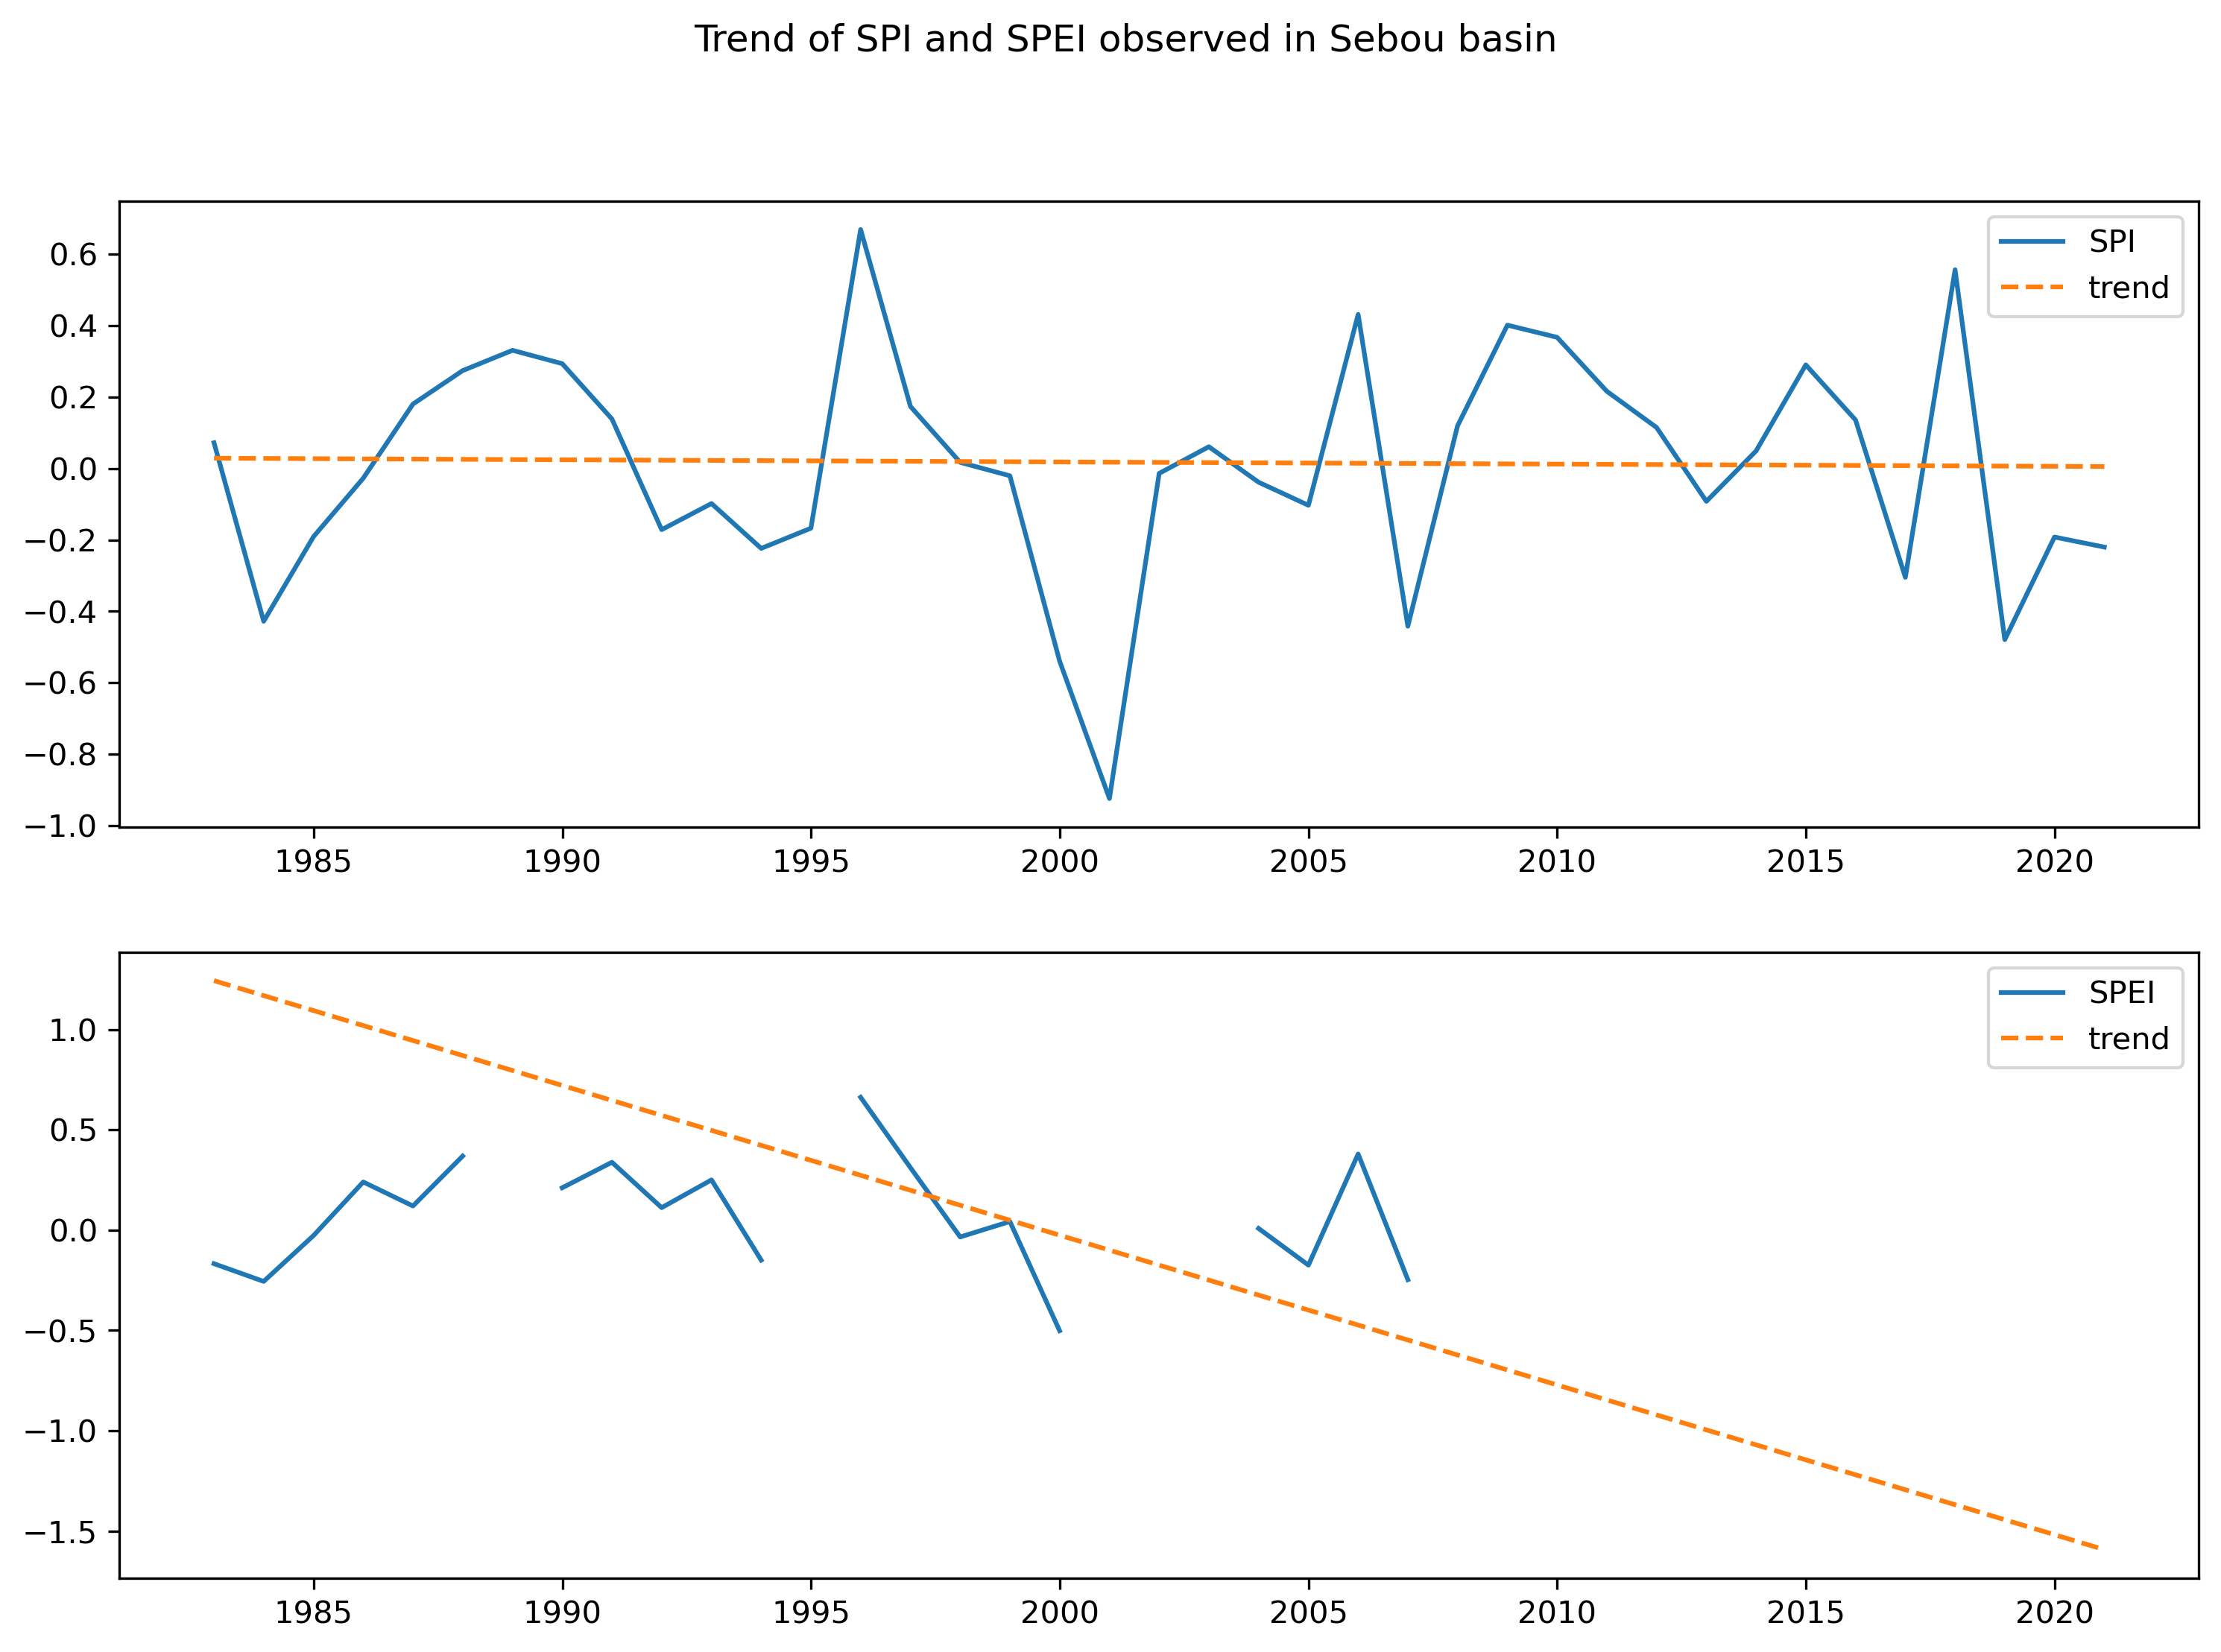

In [82]:
#trend analysis of spi and spei
arai = [np.nansum(DI_ma['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_ma['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_ma['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_ma['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_ma['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_ma['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()

datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Sebou basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

plt.show()

**Sebou basin**

In [ ]:
pop = [698, 699, 700, 701, 702, 
       767, 768, 769, 770, 771, 772, 773, 774, 
       838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 
       911, 912, 913, 914, 915, 916, 917, 
       984, 985, 986, 987, 988, 989, 
       1057, 1058, 1059, 1060, 1061, 
       1131]

**Sebou Basin with mask on pixel > 1000m**

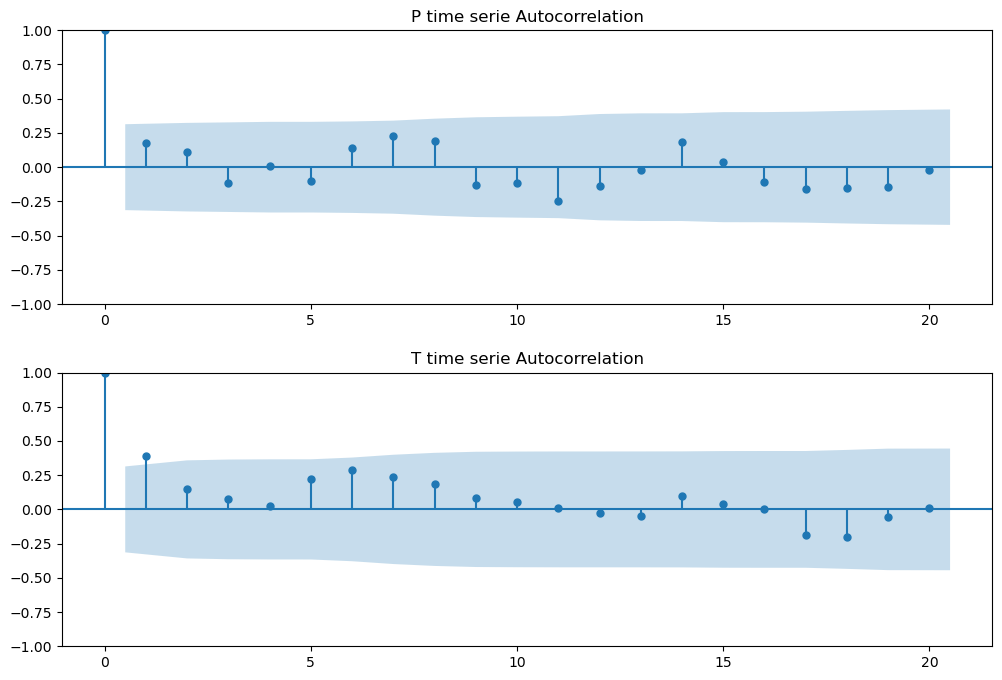

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.1274572747761462, z=1.5242059395497458, Tau=0.17139001349527666, s=127.0, var_s=6833.666666666667, slope=2.0039655853200826, intercept=410.35461276548887)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=0.0008416025845414676, z=3.33873681996611, Tau=0.3738191632928475, s=277.0, var_s=6833.666666666667, slope=0.026539347432659902, intercept=17.964227922544893)


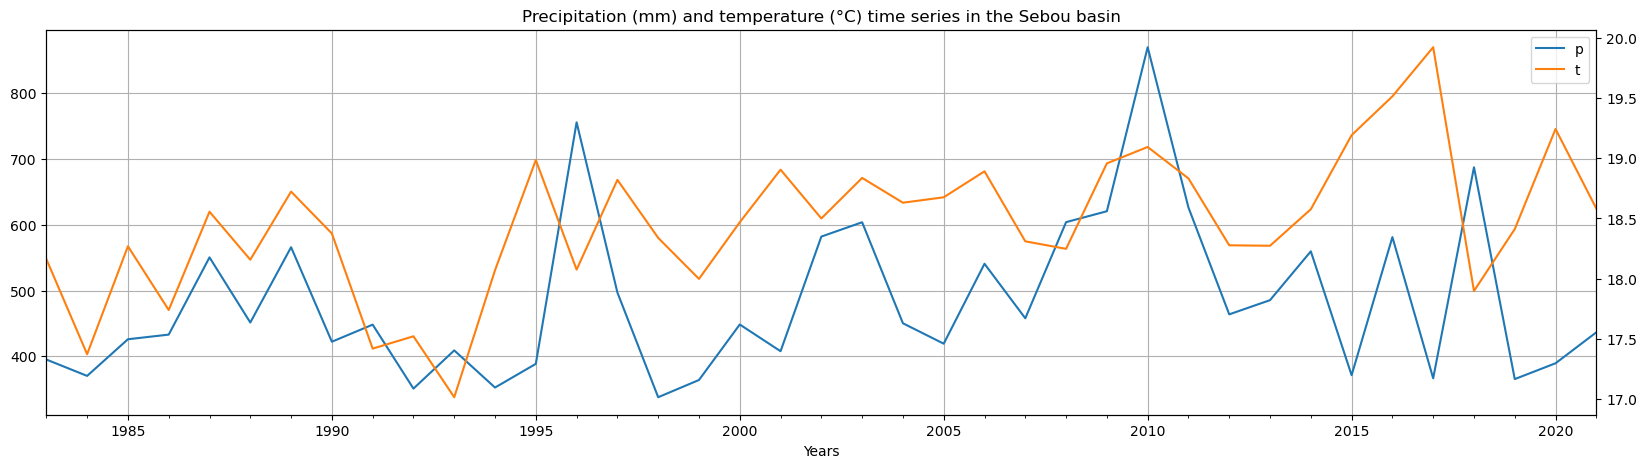

In [75]:
pop = [698, 699, 
       766, 767, 768, 769, 770, 771, 772,
       837, 838, 839, 840, 841, 842, 843, 844, 845, 
       910, 911, 912, 913, 914, 915, 
       983, 984, 985]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shpa)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shpa)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(pa, lags=20, ax=axs[0], alpha=0.05, title='P time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ta, lags=20, ax=axs[1], alpha=0.05, title='T time serie Autocorrelation')
plt.show()

avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in the Sebou basin')

ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)

In [222]:
pop = [698, 699, 
       766, 767, 768, 769, 770, 771, 772,
       837, 838, 839, 840, 841, 842, 843, 844, 845, 
       910, 911, 912, 913, 914, 915, 
       983, 984, 985]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_sebou = pd.DataFrame()
DI_sebou["Dates"]=p["Dates"]
DI = pd.read_csv('outputchirps/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
#DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_sebou["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('outputchirps/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_sebou["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('outputchirps/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
#RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_sebou["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('outputchirps/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_sebou["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('outputchirps/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_sebou["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('outputchirps/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_sebou["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('outputchirps/SPEI.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
#SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(np.Inf, np.nan)
SPEI = SPEI.replace(-np.Inf, np.nan)
SPEI = SPEI.replace(0, np.nan)
DI_sebou["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('outputchirps/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_sebou["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('outputchirps/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_sebou["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('outputchirps/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_sebou["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_sebou = DI_sebou[2:]
DI_sebou

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
2,01-03-83,NaN,1.000000,-0.008603,0.653810,0.653857,-0.733935,-0.795059,-1.132611,-1.133856,-1.499456
3,01-04-83,1.000000,1.000000,0.294372,1.035642,1.035547,-0.289370,-0.258561,-1.313786,-1.322824,-0.893501
4,01-05-83,NaN,1.000000,-0.312217,0.412072,0.412095,-0.577191,-0.589371,-0.603535,-0.866770,0.257549
5,01-06-83,NaN,-1.000000,-1.255252,-0.187556,-0.187561,-0.402467,-0.386826,-0.477988,-0.495407,0.125915
6,01-07-83,-1.000000,-2.259259,-2.198991,-0.793813,-0.793875,0.053798,0.485885,-0.383472,-0.324669,0.135848
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.000000,-3.000000,-2.880494,-1.217909,-1.217516,0.232238,0.471326,-0.383364,0.609723,-0.182284
464,01-09-21,-2.740741,-3.000000,-2.852165,-1.206140,-1.205781,-0.522603,-0.470018,-0.631405,0.013792,-0.636620
465,01-10-21,-2.000000,-3.000000,-2.549629,-1.065191,-1.065104,-1.837944,-1.967290,-1.598262,-1.586951,-3.095675
466,01-11-21,-1.000000,-1.360000,-1.378170,-0.516908,-0.516944,-1.154062,-1.188427,-1.837610,-1.833777,-1.211909


In [223]:
DI_sebou.to_csv('outputchirps/DI_sebou.csv')

In [77]:
DIc_sebou = pd.DataFrame()
DIc_sebou['Dates'] = DI_sebou['Dates']
#DIc_sebou['DI'] = DI_sebou['DI'].round(0)

index = DI_sebou['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['DI'] = ic

DIc_sebou['PNI'] = DI_sebou['PNI'].round(0)
DIc_sebou['PNI'] = DIc_sebou['PNI'].replace(1, np.nan)

index = DI_sebou['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['RAI'] = ic

index = DI_sebou['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['ZSI'] = ic

index = DI_sebou['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['CZI'] = ic

index = DI_sebou['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['SPI'] = ic

index = DI_sebou['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['SPEI'] = ic

index = DI_sebou['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['PDSI'] = ic

index = DI_sebou['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['scPDSI'] = ic

index = DI_sebou['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['PZI'] = ic
DIc_sebou

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,-2
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
2,01-03-83,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0
3,01-04-83,0.0,NaN,0.0,1.0,1.0,0.0,0.0,0,0,0
4,01-05-83,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,NaN,0,0,0
464,01-09-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,NaN,0,0,0
465,01-10-21,-3.0,-3.0,-2.0,-1.0,-1.0,-2.0,NaN,0,0,-2
466,01-11-21,-1.0,-1.0,-1.0,0.0,0.0,-1.0,NaN,0,0,0


In [78]:
DI_sebou['rand'] = (np.random.rand(len(DI_sebou)))/5
DI_sebou['CZI'] = DI_sebou['CZI'].sub(DI_sebou['rand'])
DI_sebou['rand'] = (np.random.rand(len(DI_sebou)))/5
DI_sebou['ZSI'] = DI_sebou['ZSI'].sub(DI_sebou['rand'])
DI_sebou = DI_sebou.drop(['rand'], axis=1)

DI_sebou

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-1.045690,-1.045690,-3.137070
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.674293,-0.395616,0.591802
2,01-03-83,NaN,1.000000,-0.008603,0.603469,0.478633,-0.733935,-0.795059,-1.132611,-1.133856,-1.499456
3,01-04-83,1.000000,1.000000,0.294372,0.939742,0.872621,-0.289370,-0.258561,-1.313786,-1.322824,-0.893501
4,01-05-83,NaN,1.000000,-0.312217,0.285745,0.356651,-0.577191,-0.589371,-0.603535,-0.866770,0.257549
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.000000,-3.000000,-2.880494,-1.411474,-1.304607,0.232238,NaN,-0.383364,0.609723,-0.182284
464,01-09-21,-2.740741,-3.000000,-2.852165,-1.358396,-1.213117,-0.522603,NaN,-0.631405,0.013792,-0.636620
465,01-10-21,-2.000000,-3.000000,-2.549629,-1.209067,-1.250968,-1.837944,NaN,-1.598262,-1.586951,-3.095675
466,01-11-21,-1.000000,-1.360000,-1.378170,-0.613399,-0.599974,-1.154062,NaN,-1.837610,-1.833777,-1.211909


<AxesSubplot:title={'center':'Sebou Basin (Subhumid)'}>

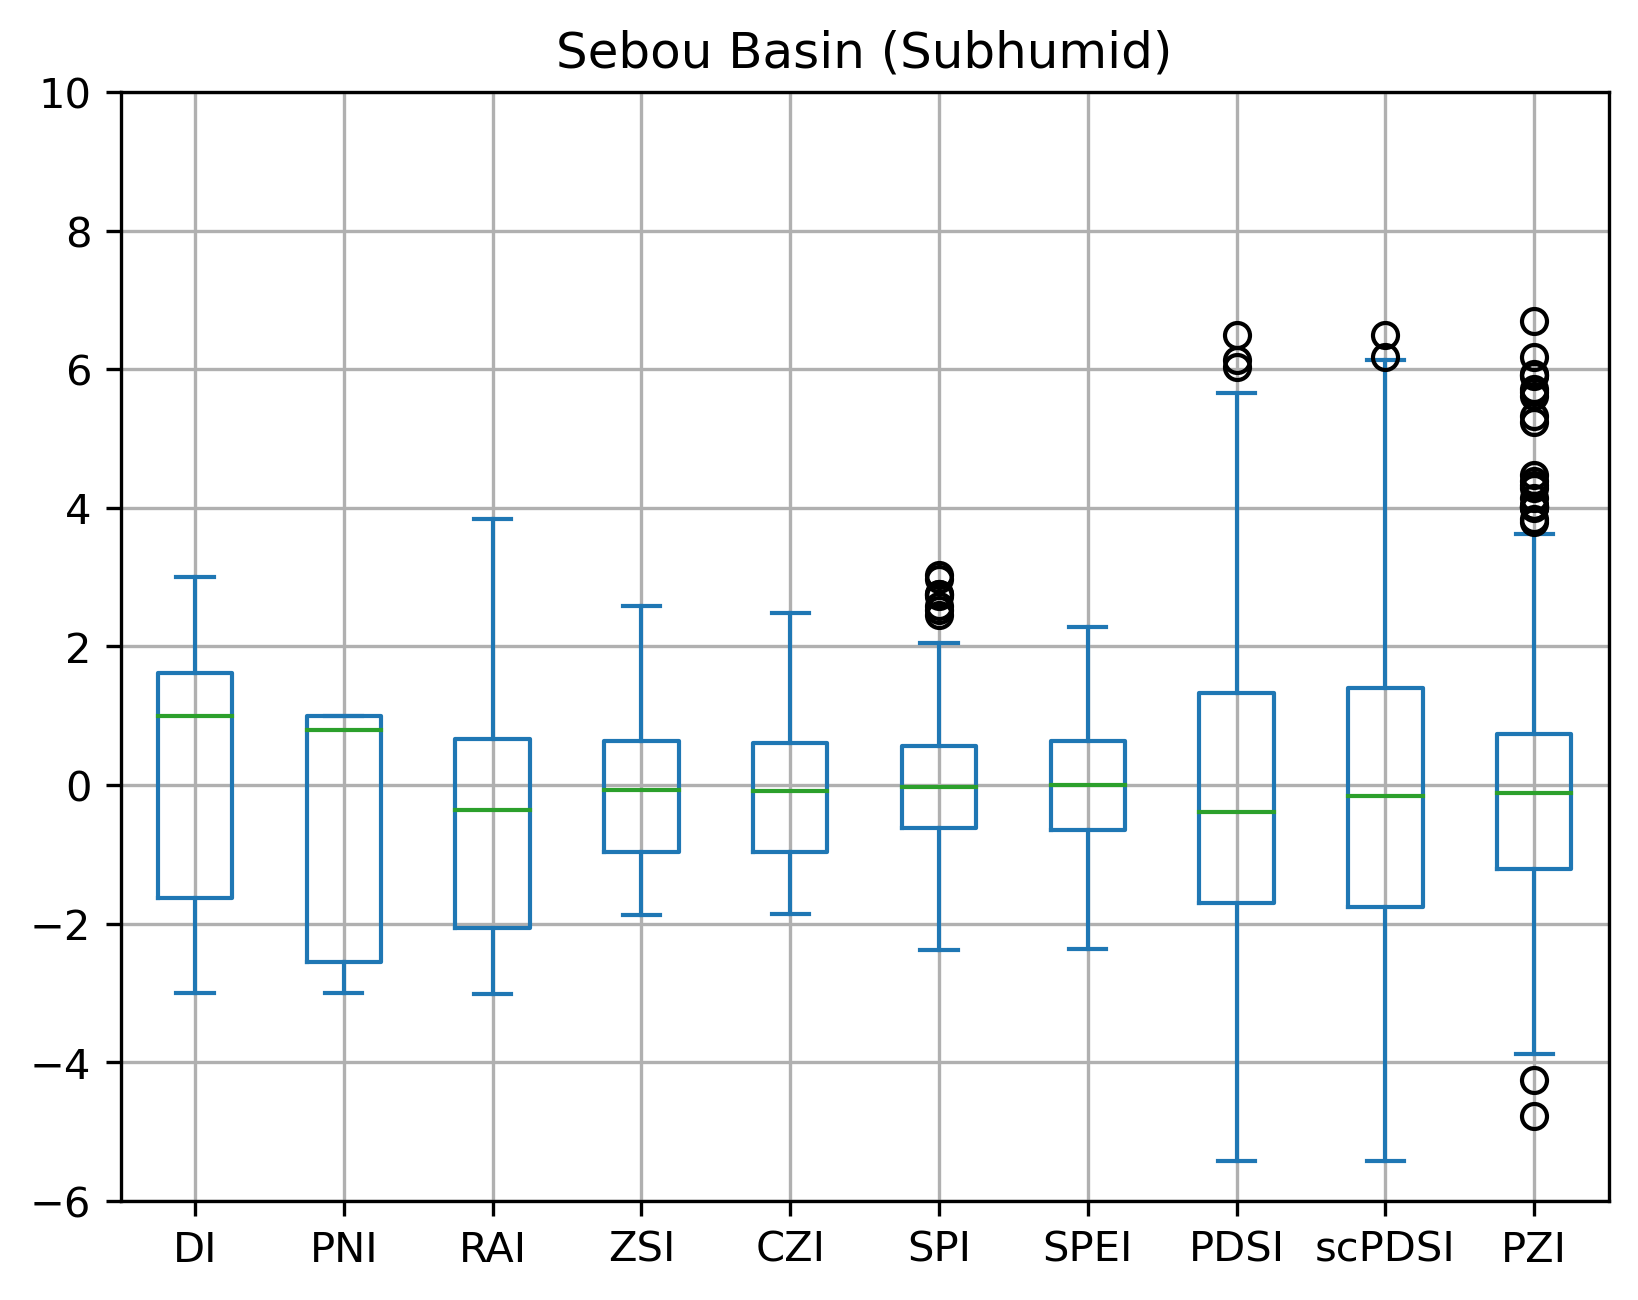

In [79]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
DI_sebou.plot(kind='box', title='Sebou Basin (Subhumid)', grid = True, ylim = (-6, 10))

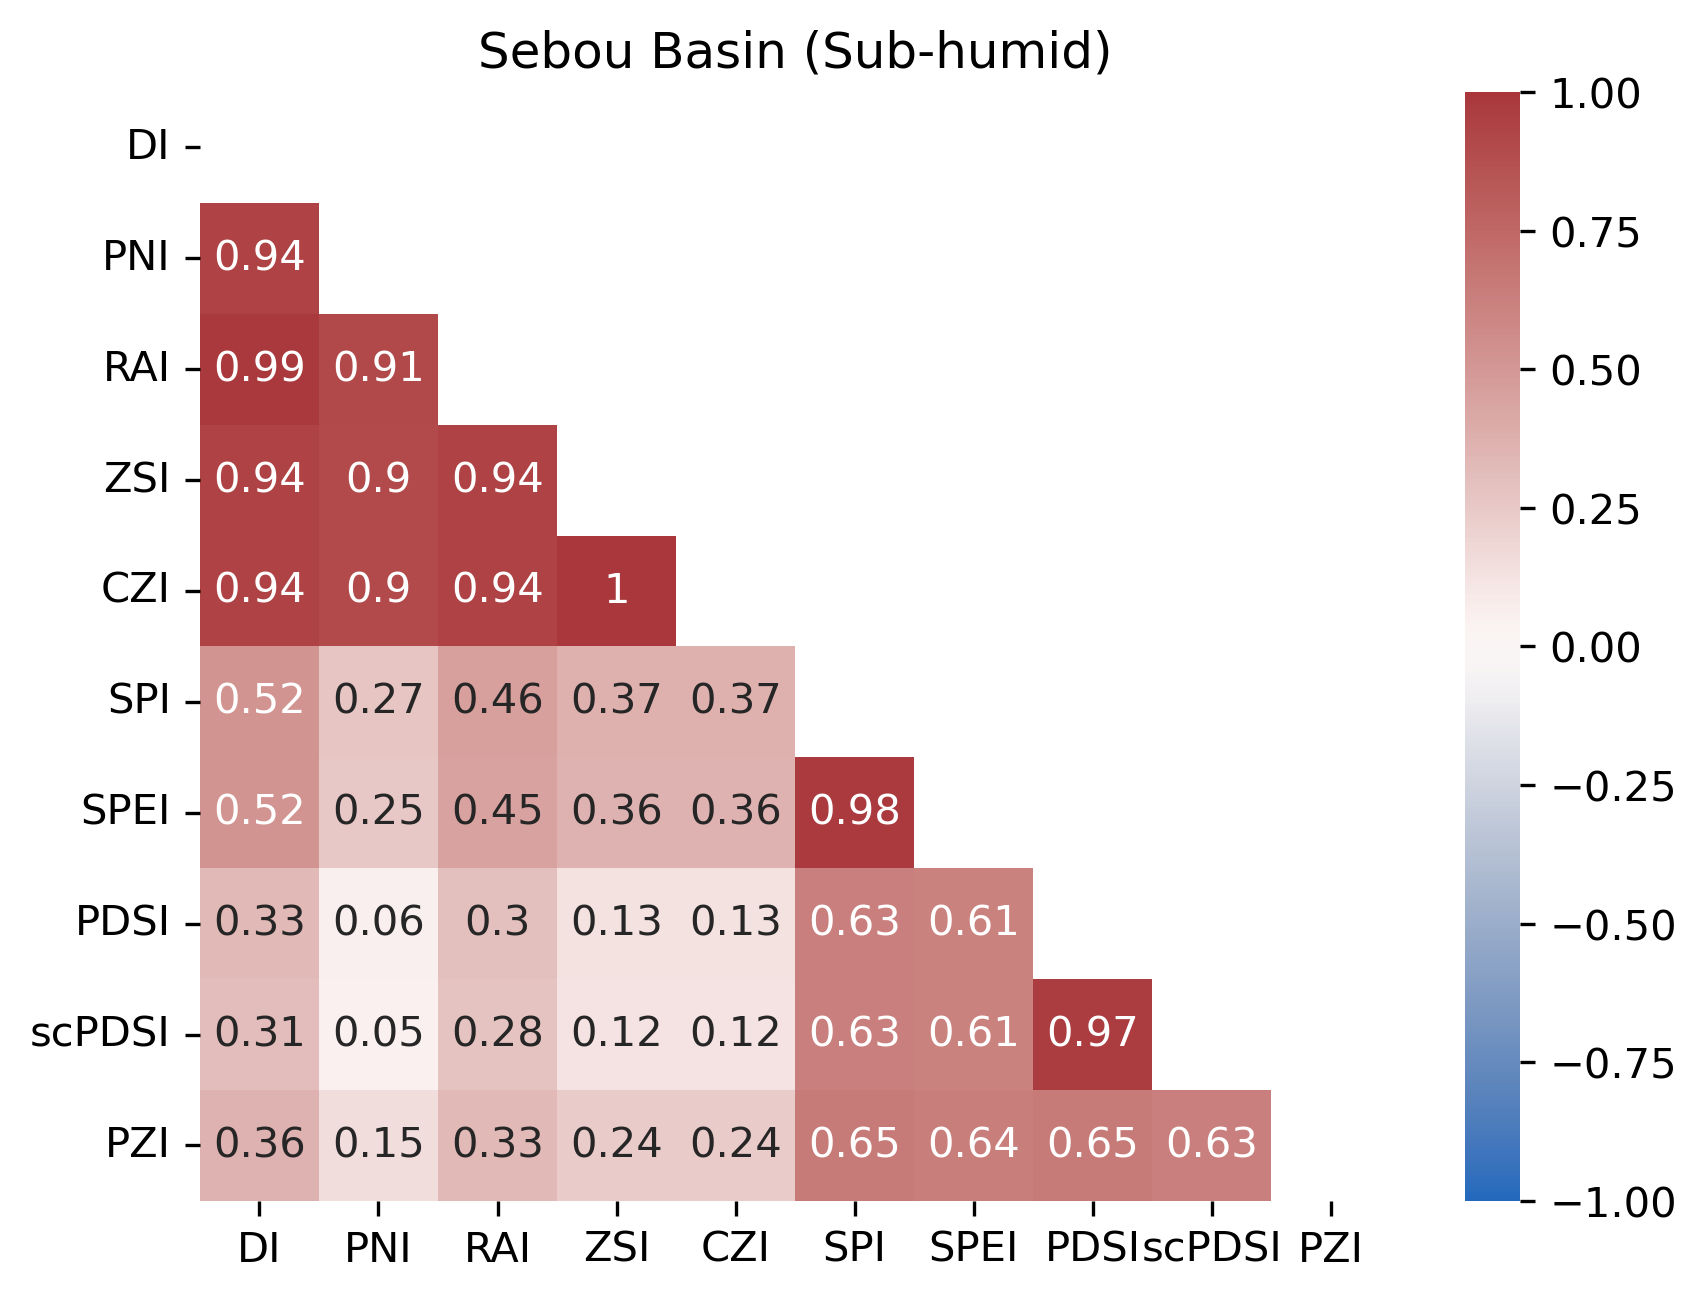

In [80]:
#DI_sebou = DI_sebou.drop(['Dates'], axis=1)
DI_sebou.replace([np.inf, -np.inf], np.nan, inplace=True)
DI_sebou.dropna()
#pvalue = calculate_pvalues(DI_sebou)
matrix = DI_sebou.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
#pvalue = pvalue.astype(float).round(3)
#sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Sebou Basin (Sub-humid)")
plt.show()

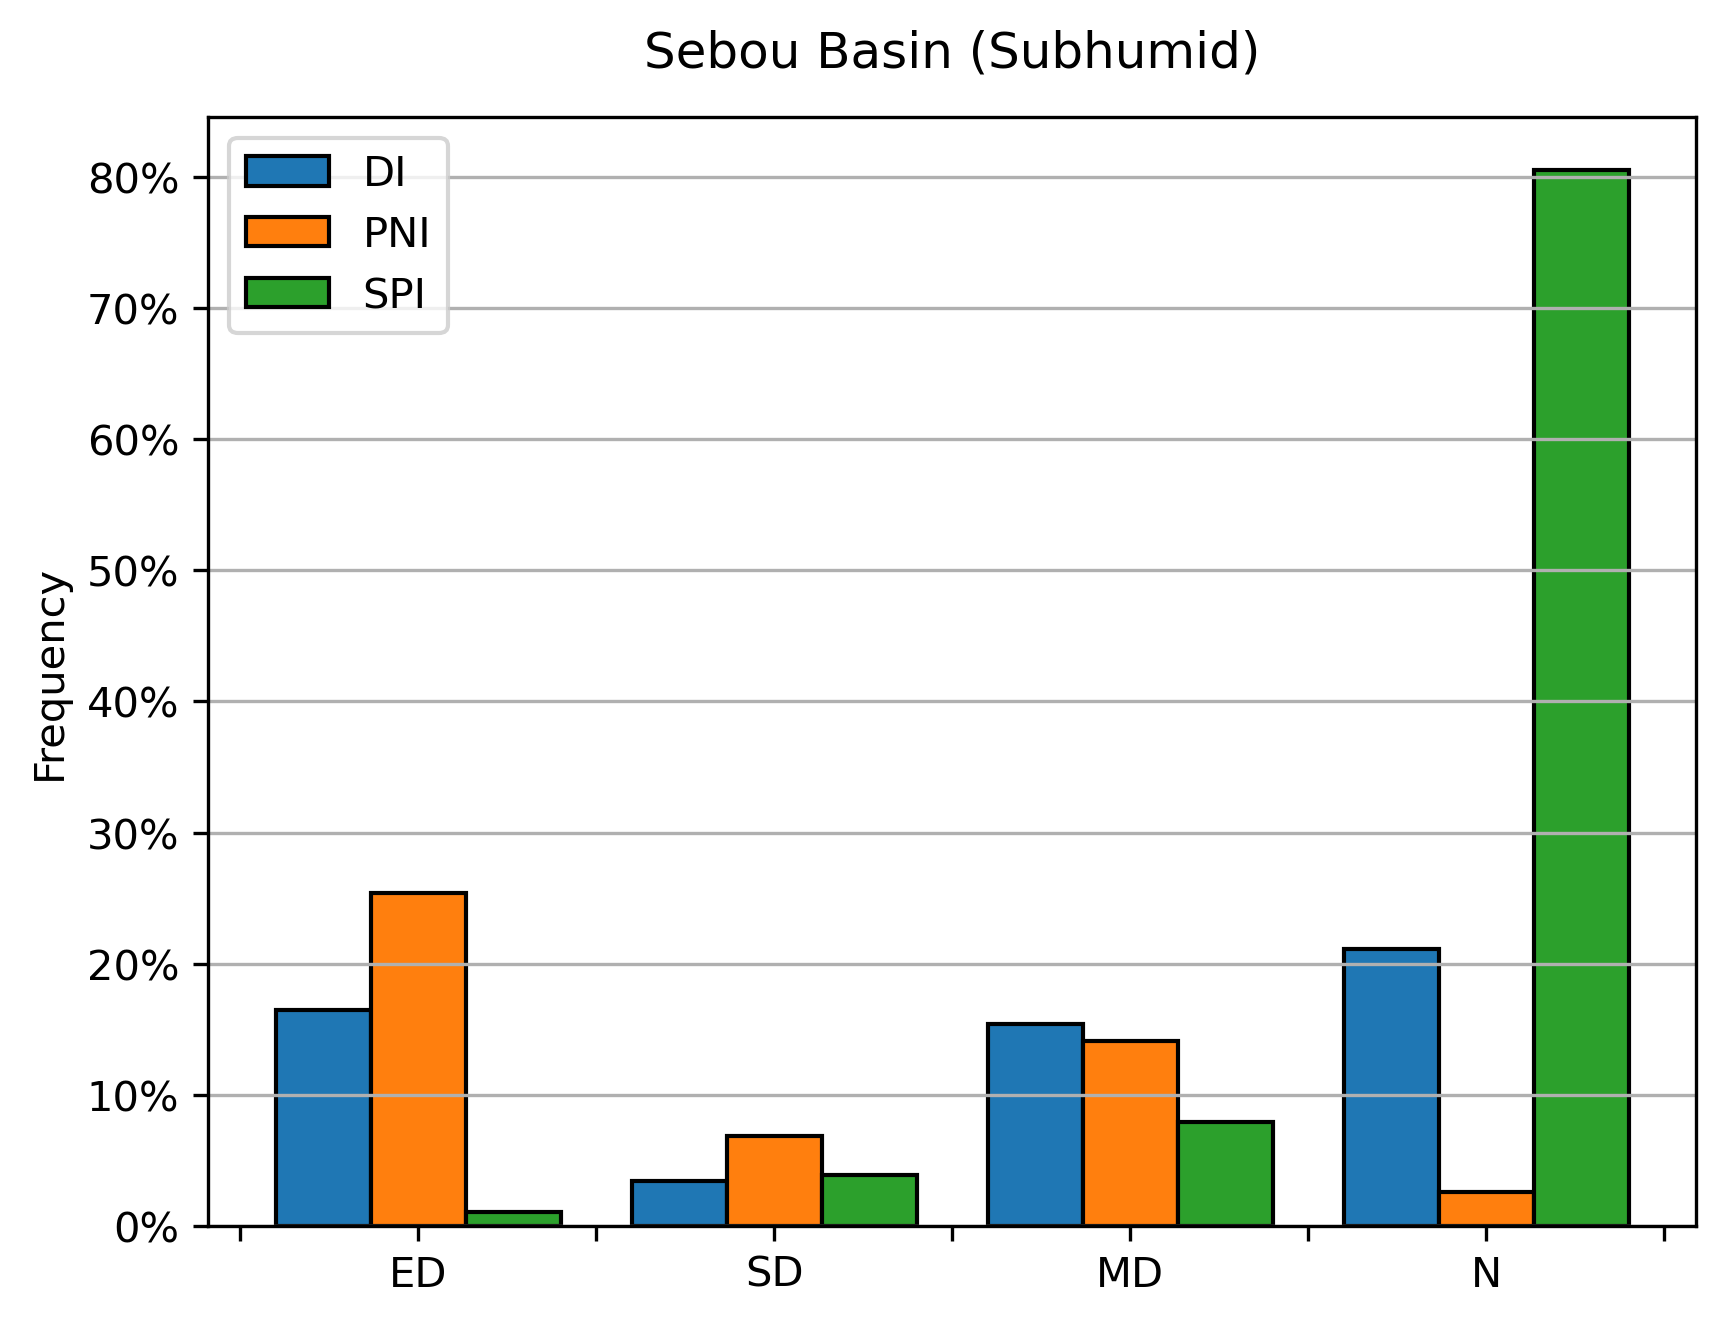

In [89]:
#create relative frequency histogram with percentages on y-axis
data = DIc_sebou[['DI', 'PNI', 'SPI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['DI', 'PNI', 'SPI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.grid(axis='y')
ax.set_title('Sebou Basin (Subhumid)', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [991]:
DI_sebou.set_index("Dates", inplace = True)
DI_sebou.index = pd.to_datetime(DI_sebou.index)

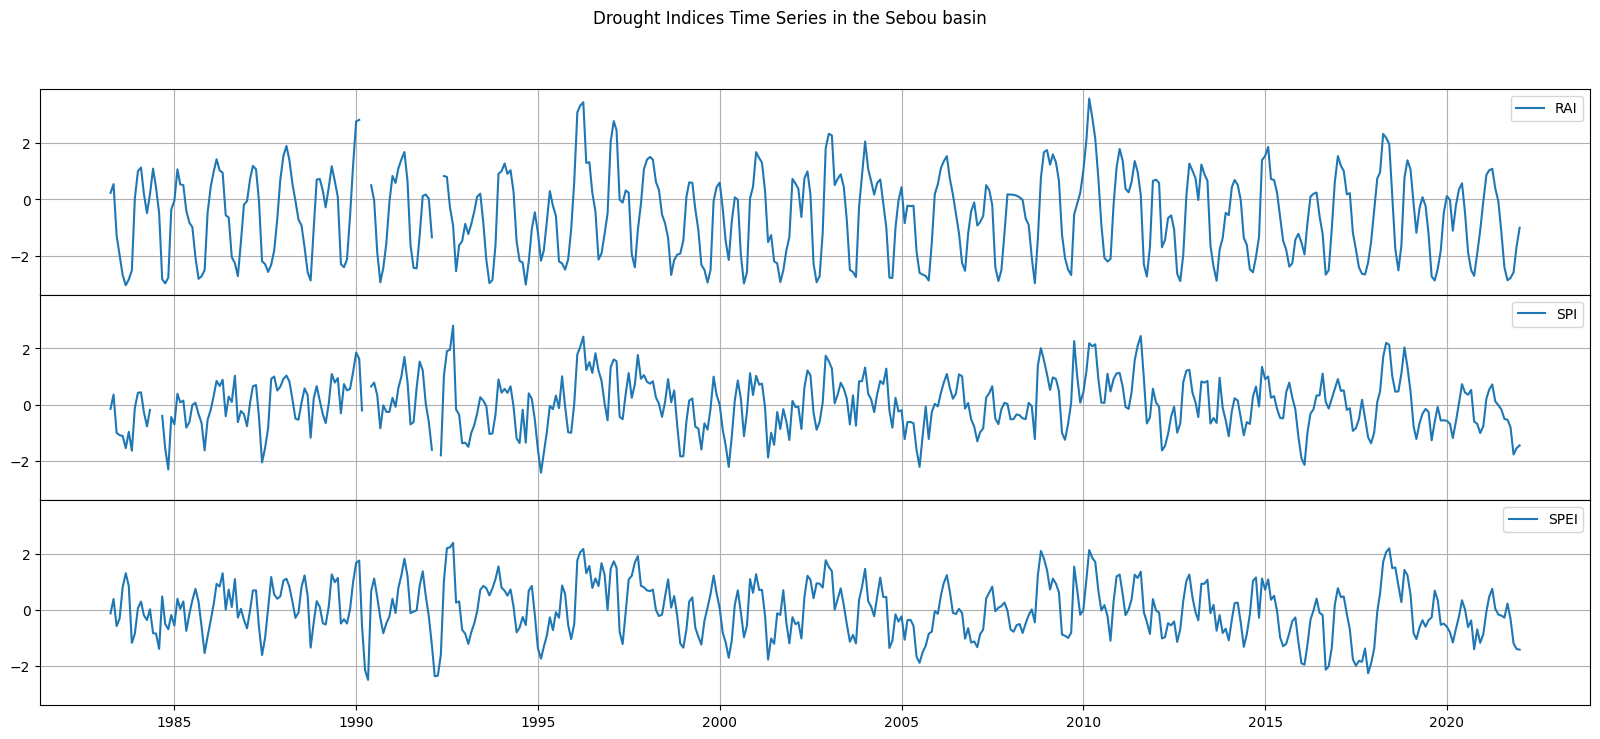

In [996]:
datetime_series = pd.Series(pd.date_range("1983", periods=468, freq="M"))
data = DI_sebou
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Sebou basin')
axs[0].plot(datetime_series, data['RAI'], label='RAI')
axs[0].legend()
axs[1].plot(datetime_series, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(datetime_series, data['SPEI'], label='SPEI')
axs[2].legend()

# Hide x labels and tick labels for all but bottom plot.
for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_sebou
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

In [733]:
DI_sebou[394:398]

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
2015-11-01,NaN,-1.000000,-1.225764,-0.432412,-0.432436,-1.132312,-1.129152,-1.528141,-1.528141,-2.614881
2015-12-01,-1.000000,-1.259259,-1.534790,-0.589316,-0.589361,-1.900441,-1.898273,-2.585471,-2.585471,-3.644187
2016-01-01,-1.038462,-2.296296,-1.958559,-0.914368,-0.914402,-2.142553,-1.942987,-3.239650,-3.239650,-2.761445
2016-02-01,-1.000000,-1.000000,-0.858311,-0.287819,-0.287830,-1.009878,-1.246258,-2.996684,-2.945870,-0.272154


<Axes: title={'center': 'Time series of Drought Indices in Sebou basin during 2019 drought spell'}, xlabel='Months'>

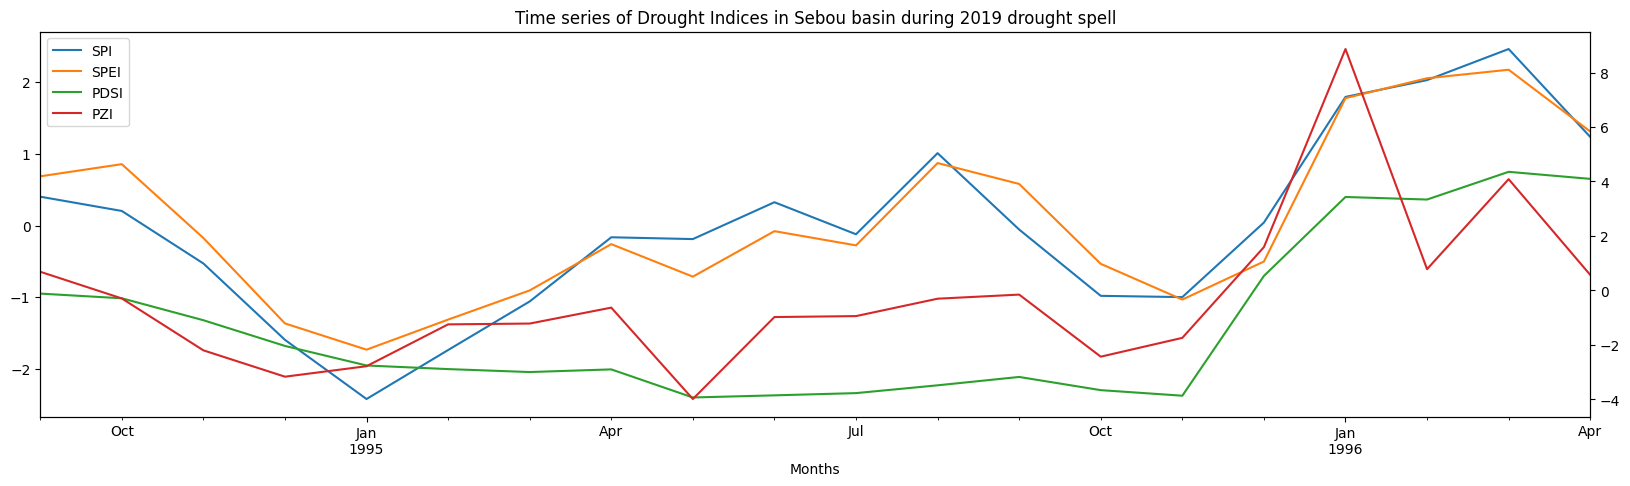

In [776]:
DI_sebou[140:160].loc[:,['SPI','SPEI','PDSI','PZI']].plot(secondary_y=['PDSI', 'PZI'], mark_right=False, figsize = (20,5), xlabel='Months', title='Time series of Drought Indices in Sebou basin during 2019 drought spell')

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.18330223399258028, z=1.3306559789720003, Tau=0.14979757085020243, s=111.0, var_s=6833.666666666667, slope=0.007206992587179671, intercept=-0.68495497077217)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.28709103347587495, z=1.0645247831776004, Tau=0.12010796221322537, s=89.0, var_s=6833.666666666667, slope=0.0074082853855725545, intercept=-0.18539380234183986)
SPEI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.2554939683022921, z=1.1371060183942547, Tau=0.1282051282051282, s=95.0, var_s=6833.666666666667, slope=0.006198545118294452, intercept=-0.10913315496876683)
scPDSI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.8465282828044682, z=0.1935499605777455, Tau=0.022941970310391364, s=17.0, var_s=6833.666666666667, slope=0.004408852363432053, intercept=-0.12449717933736454)
PZI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.961407429045934, z=0.04838749014443638, Tau=0.006747638326585695, s=5.0, var_s=6833

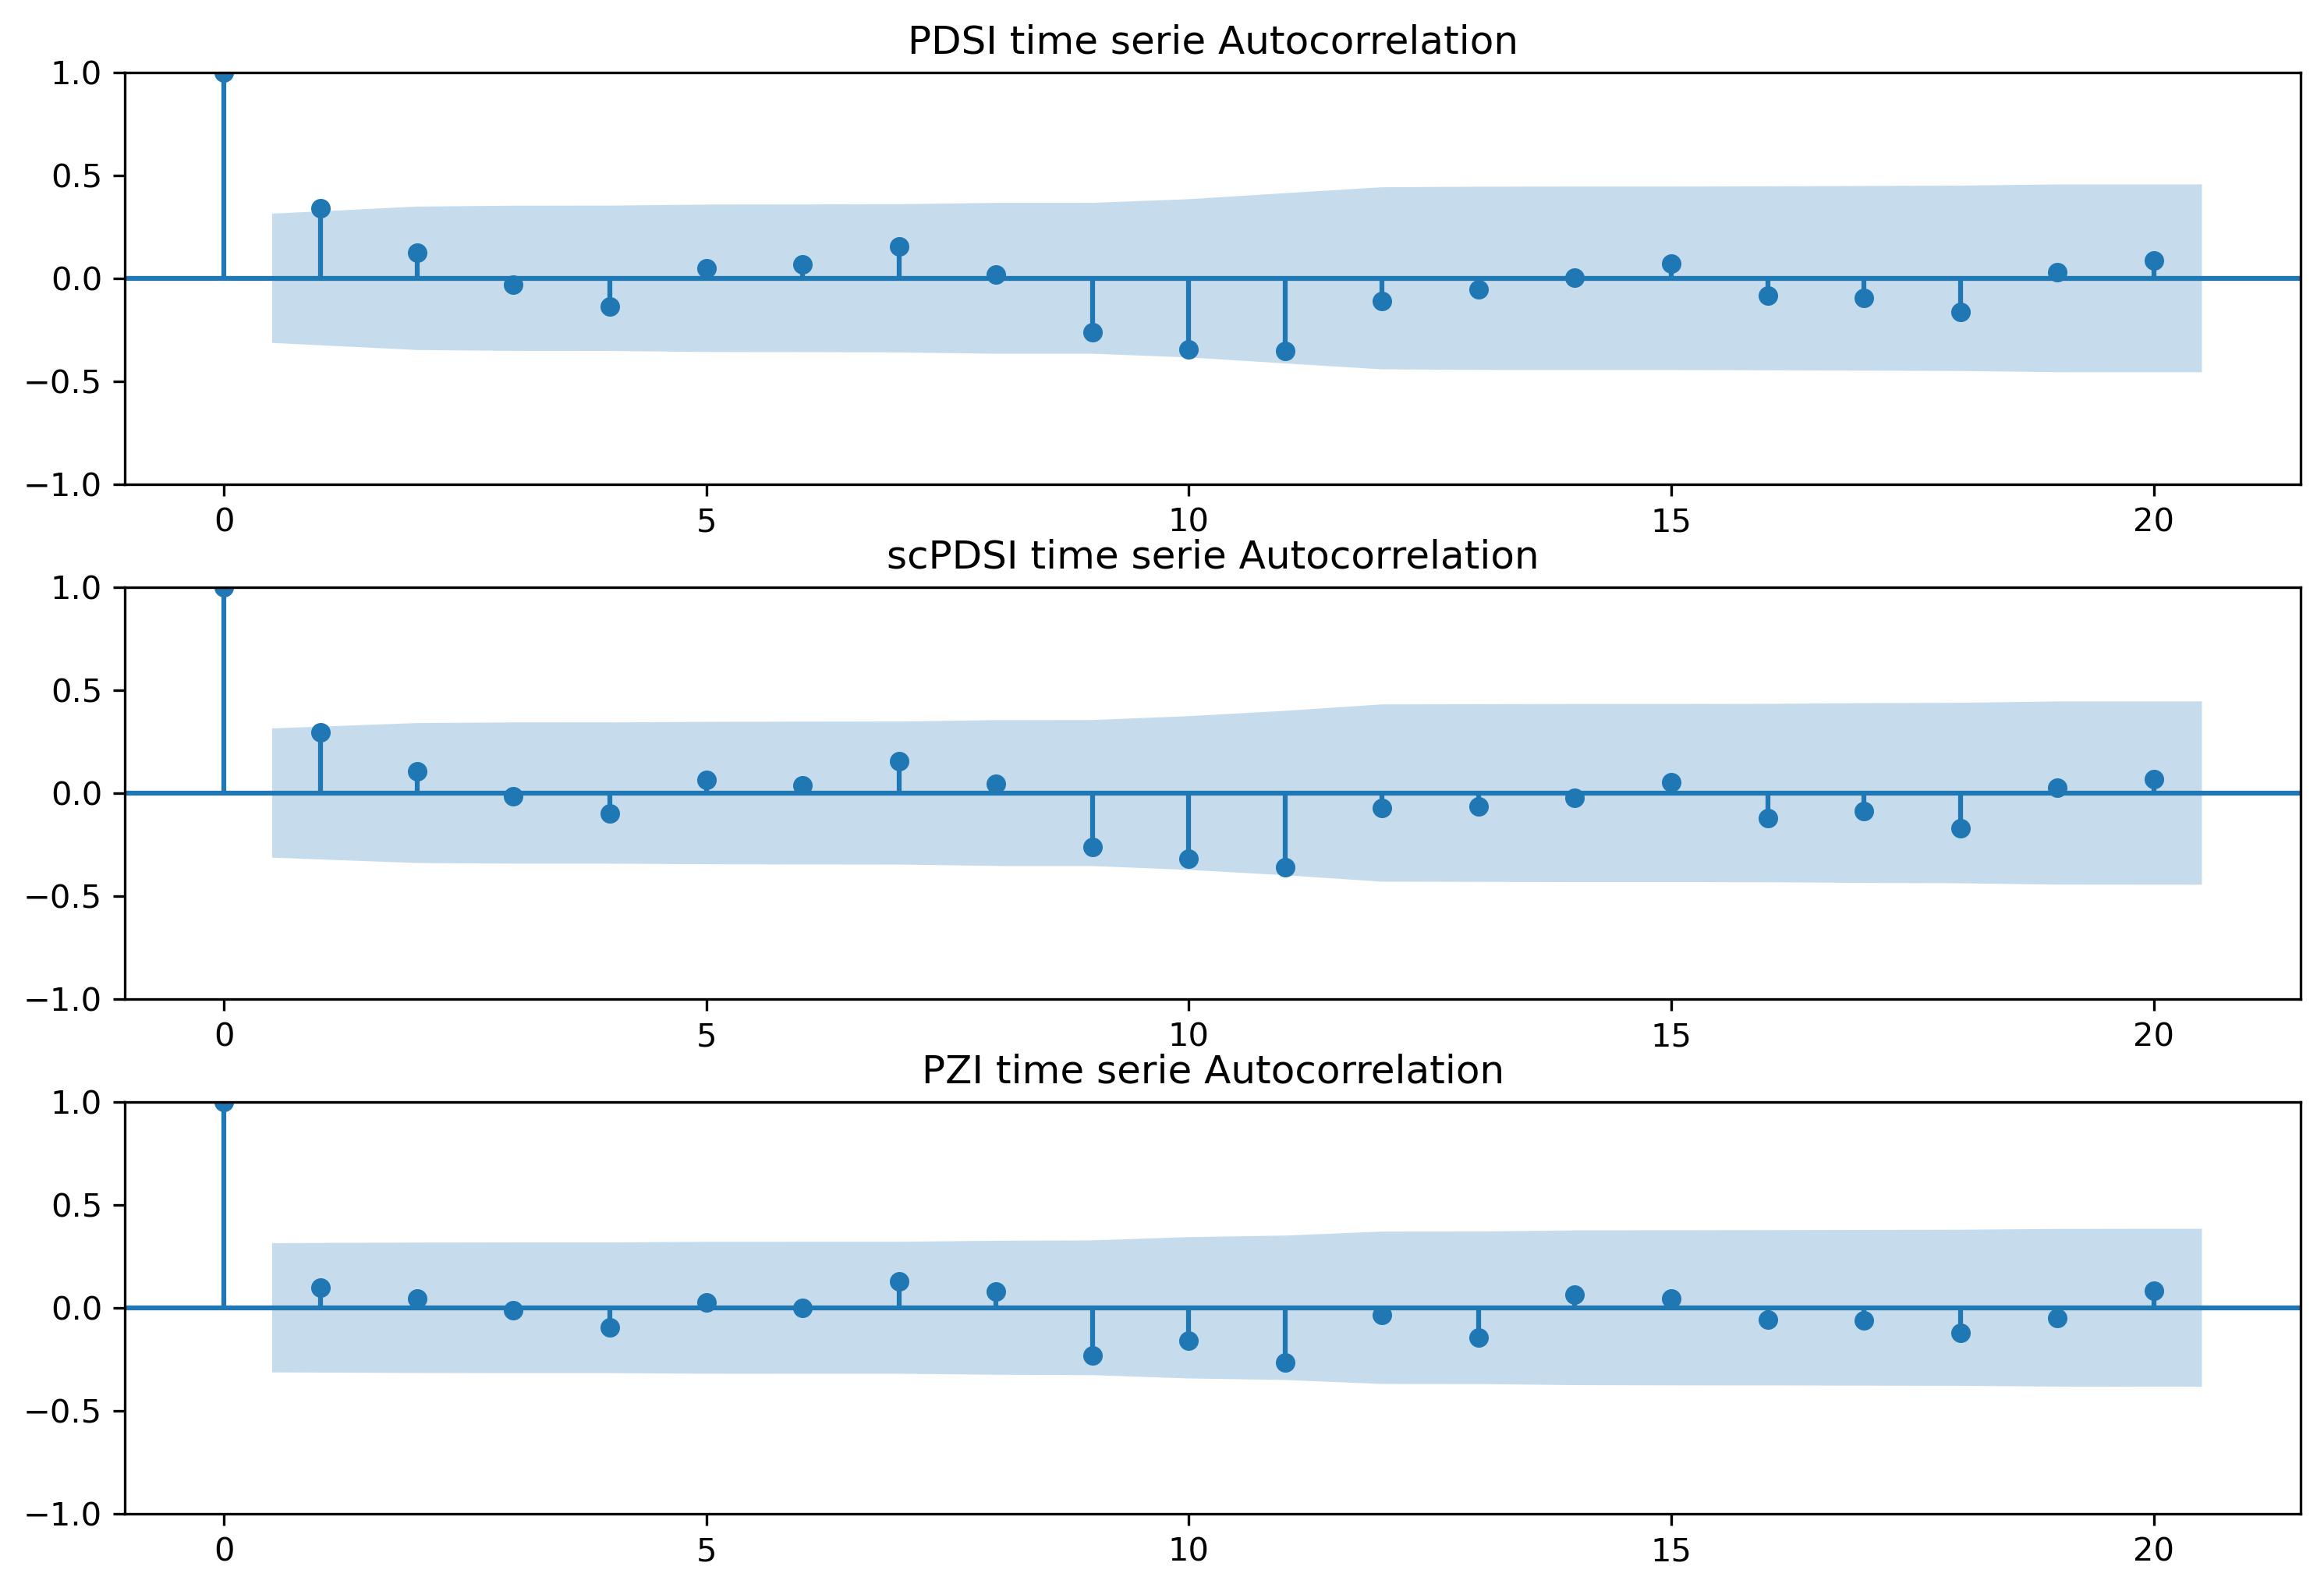

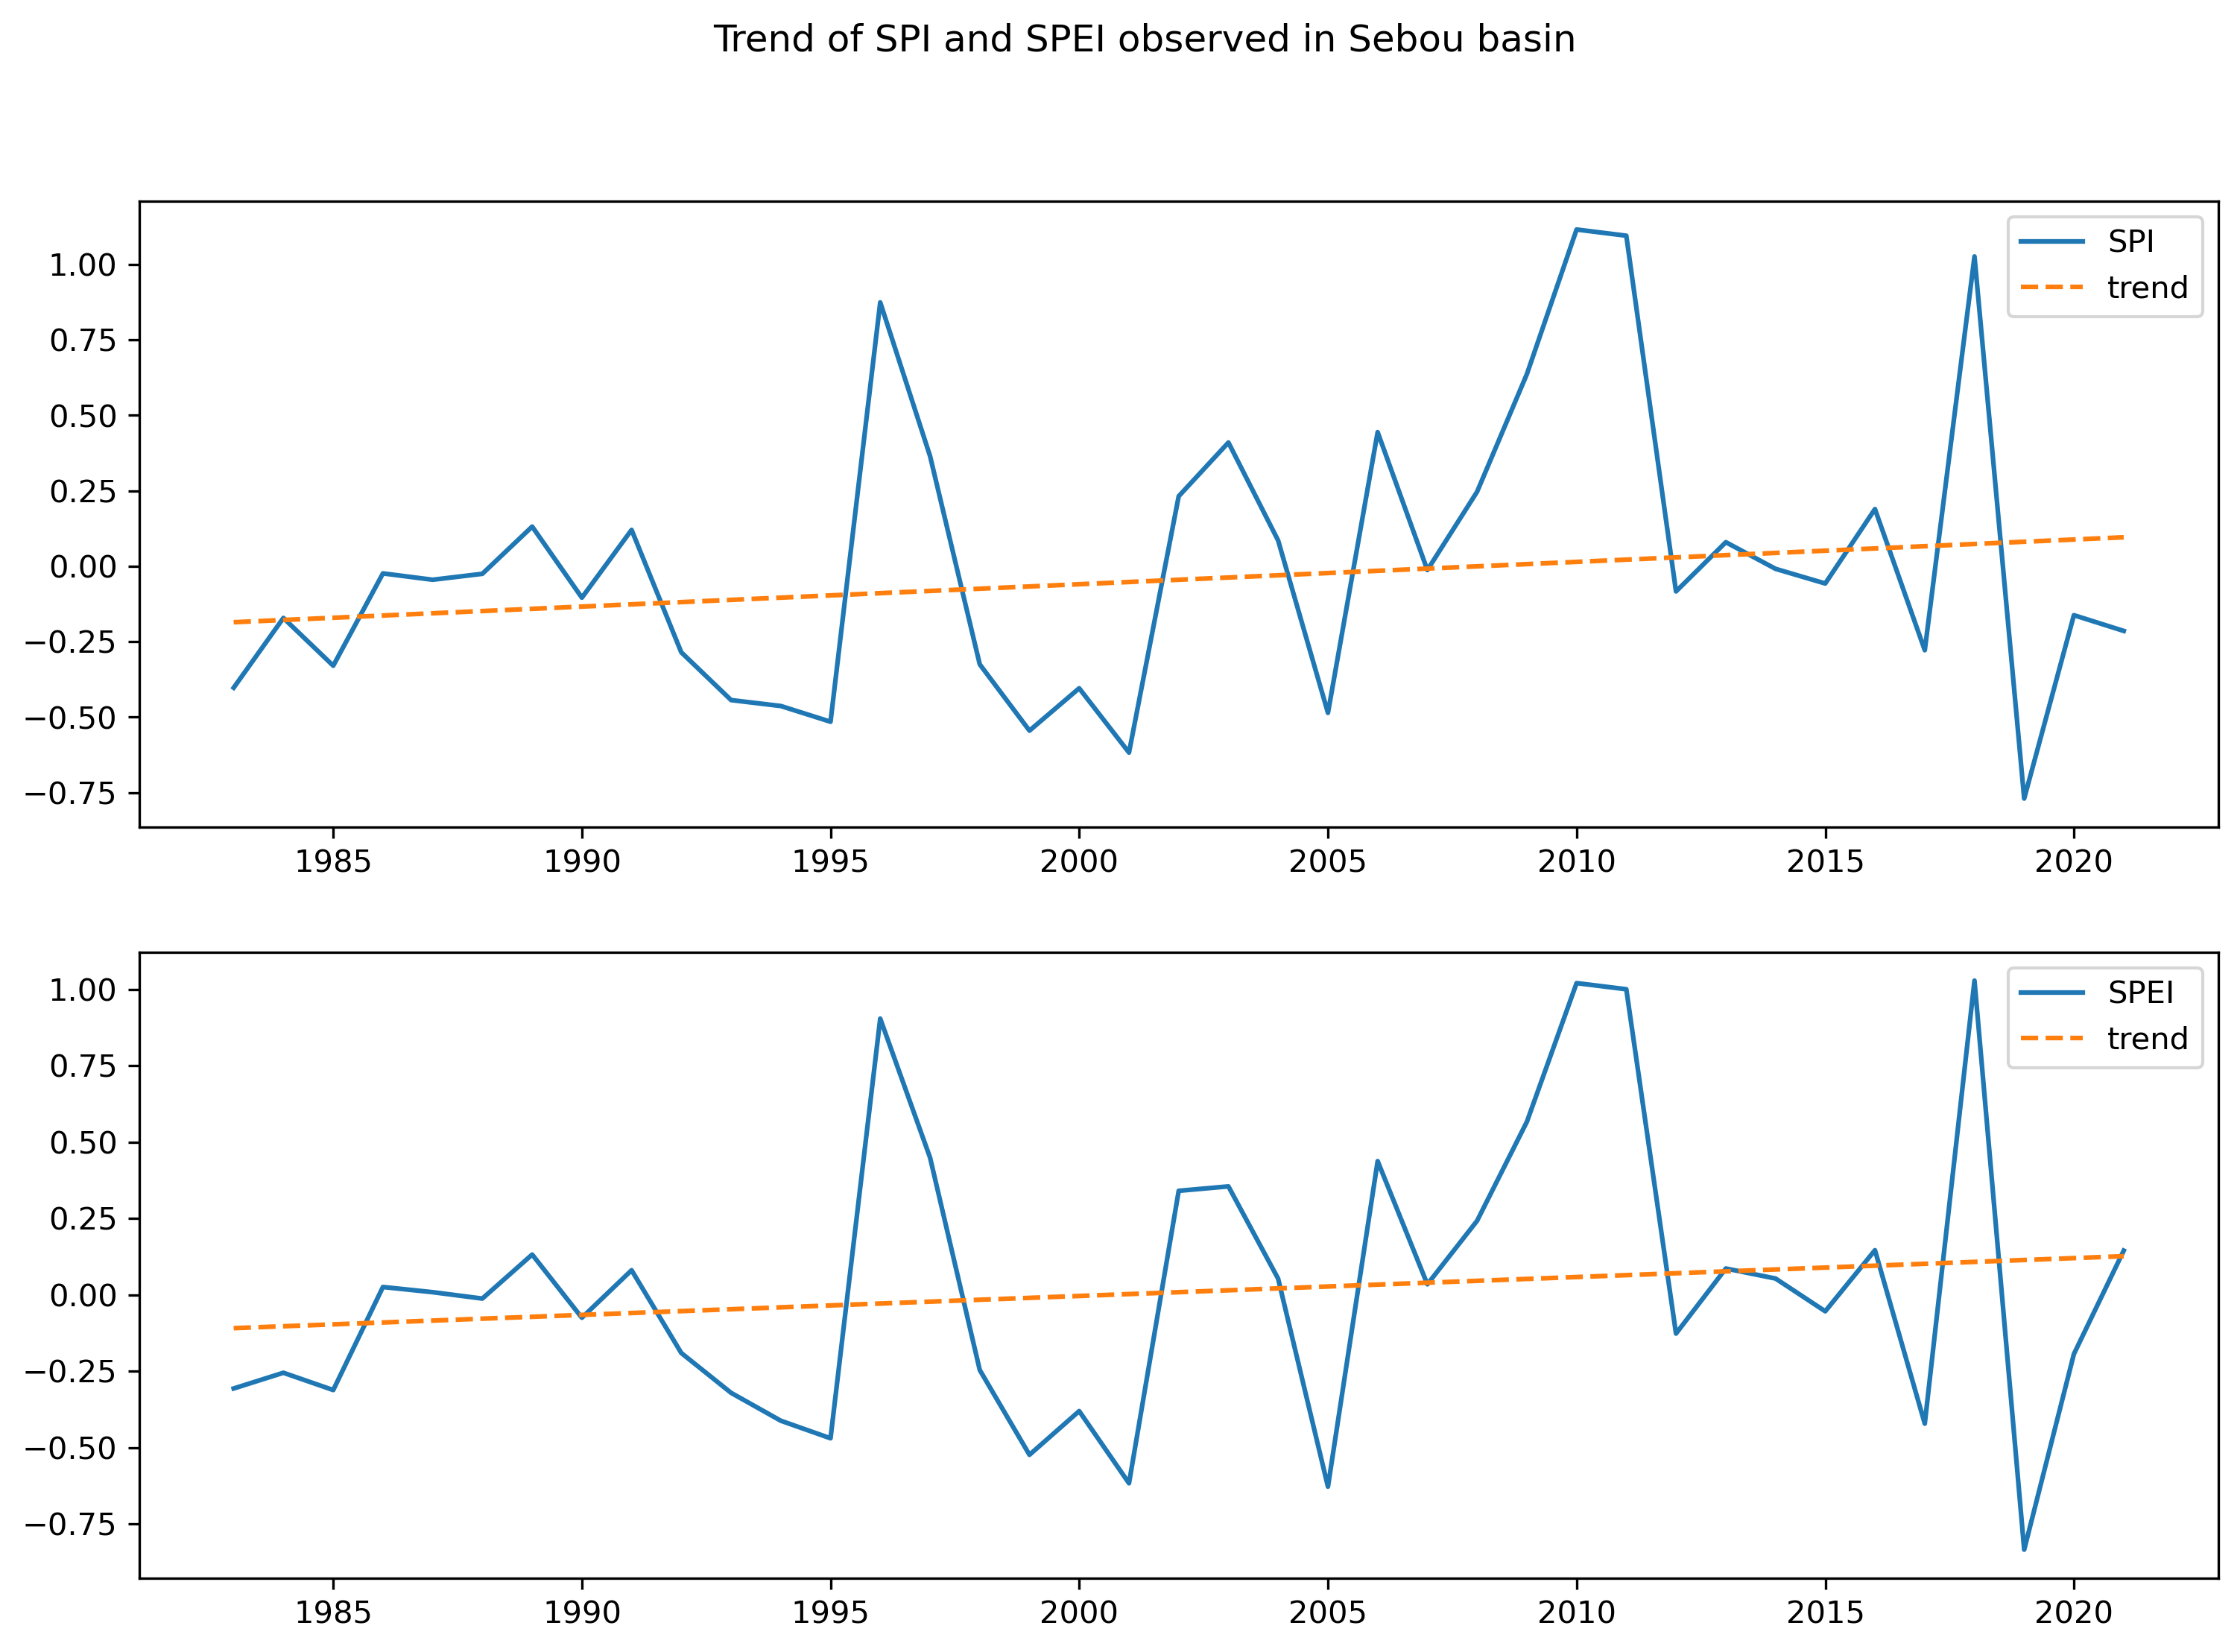

In [81]:
#trend analysis of spi and spei
arai = [np.nansum(DI_sebou['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_sebou['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_sebou['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_sebou['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_sebou['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_sebou['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()

datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Sebou basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

plt.show()

**Tensift Basin with mask on pixels > 1000m**

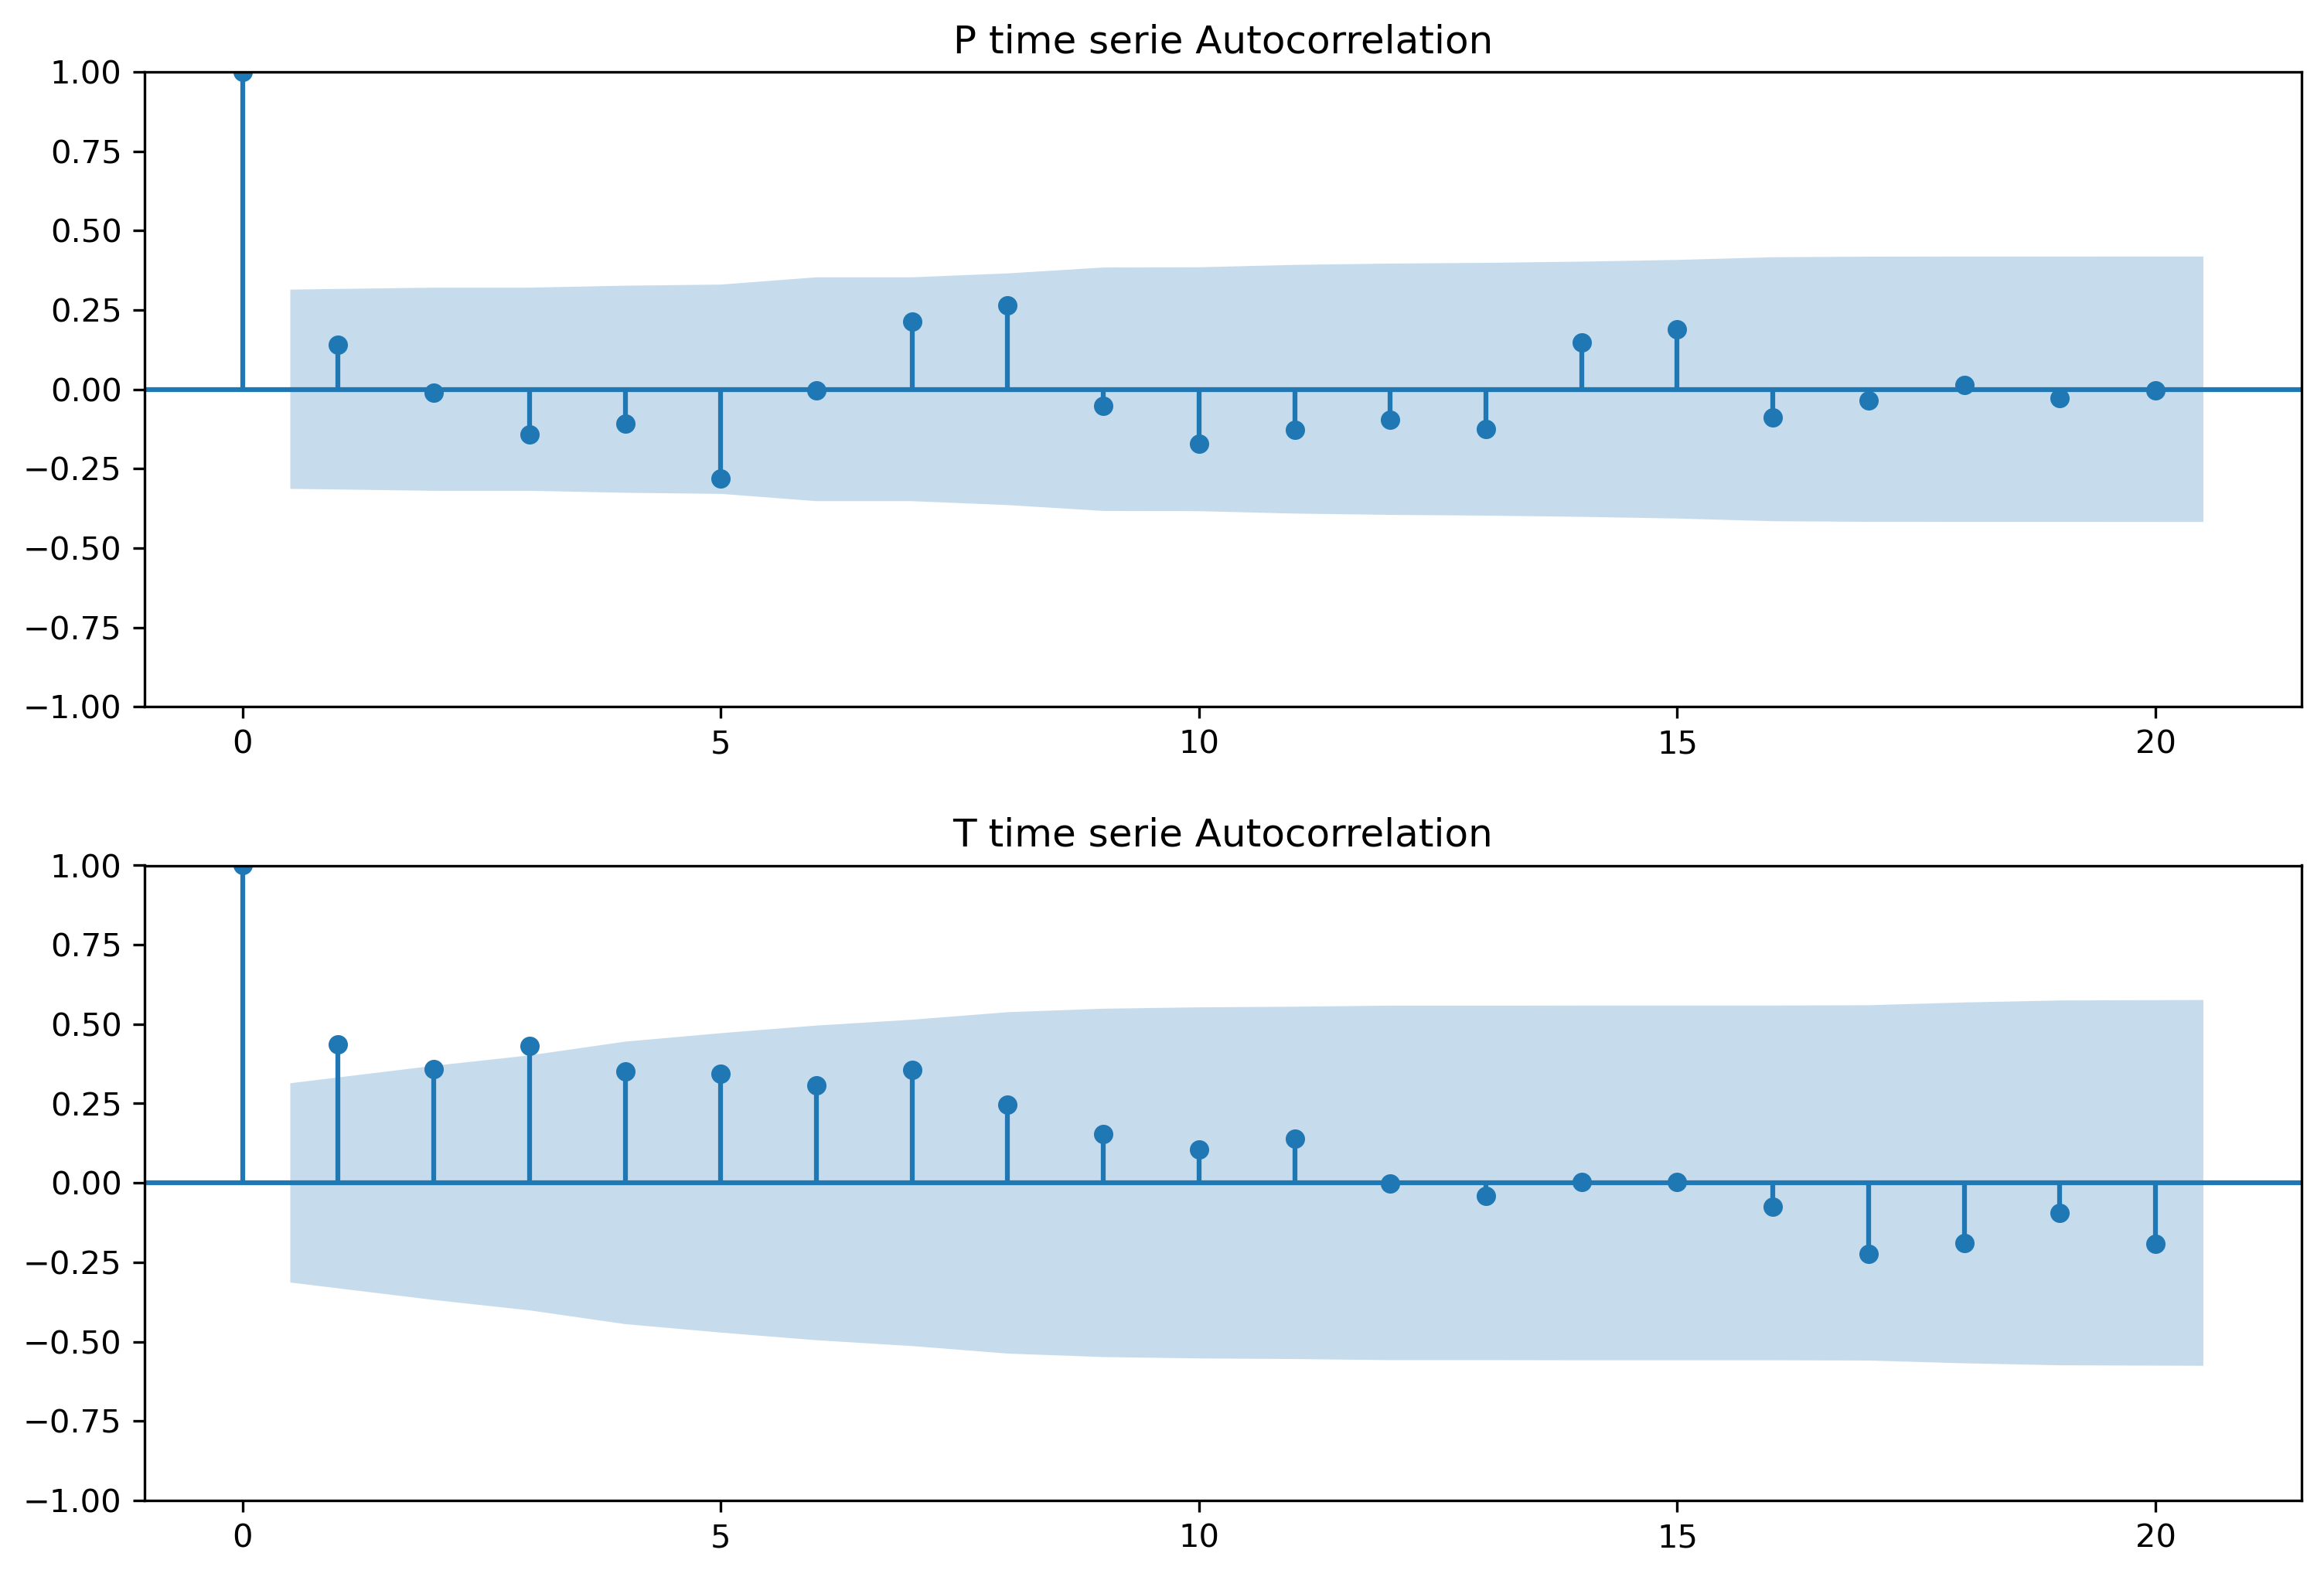

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.29818612881587514, z=-1.040331038105382, Tau=-0.11740890688259109, s=-87.0, var_s=6833.666666666667, slope=-0.8417261415348802, intercept=290.4088112045993)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=1.0231315816788822e-06, z=4.887136504588074, Tau=0.5465587044534413, s=405.0, var_s=6833.666666666667, slope=0.038038574548907786, intercept=18.3182940098528)


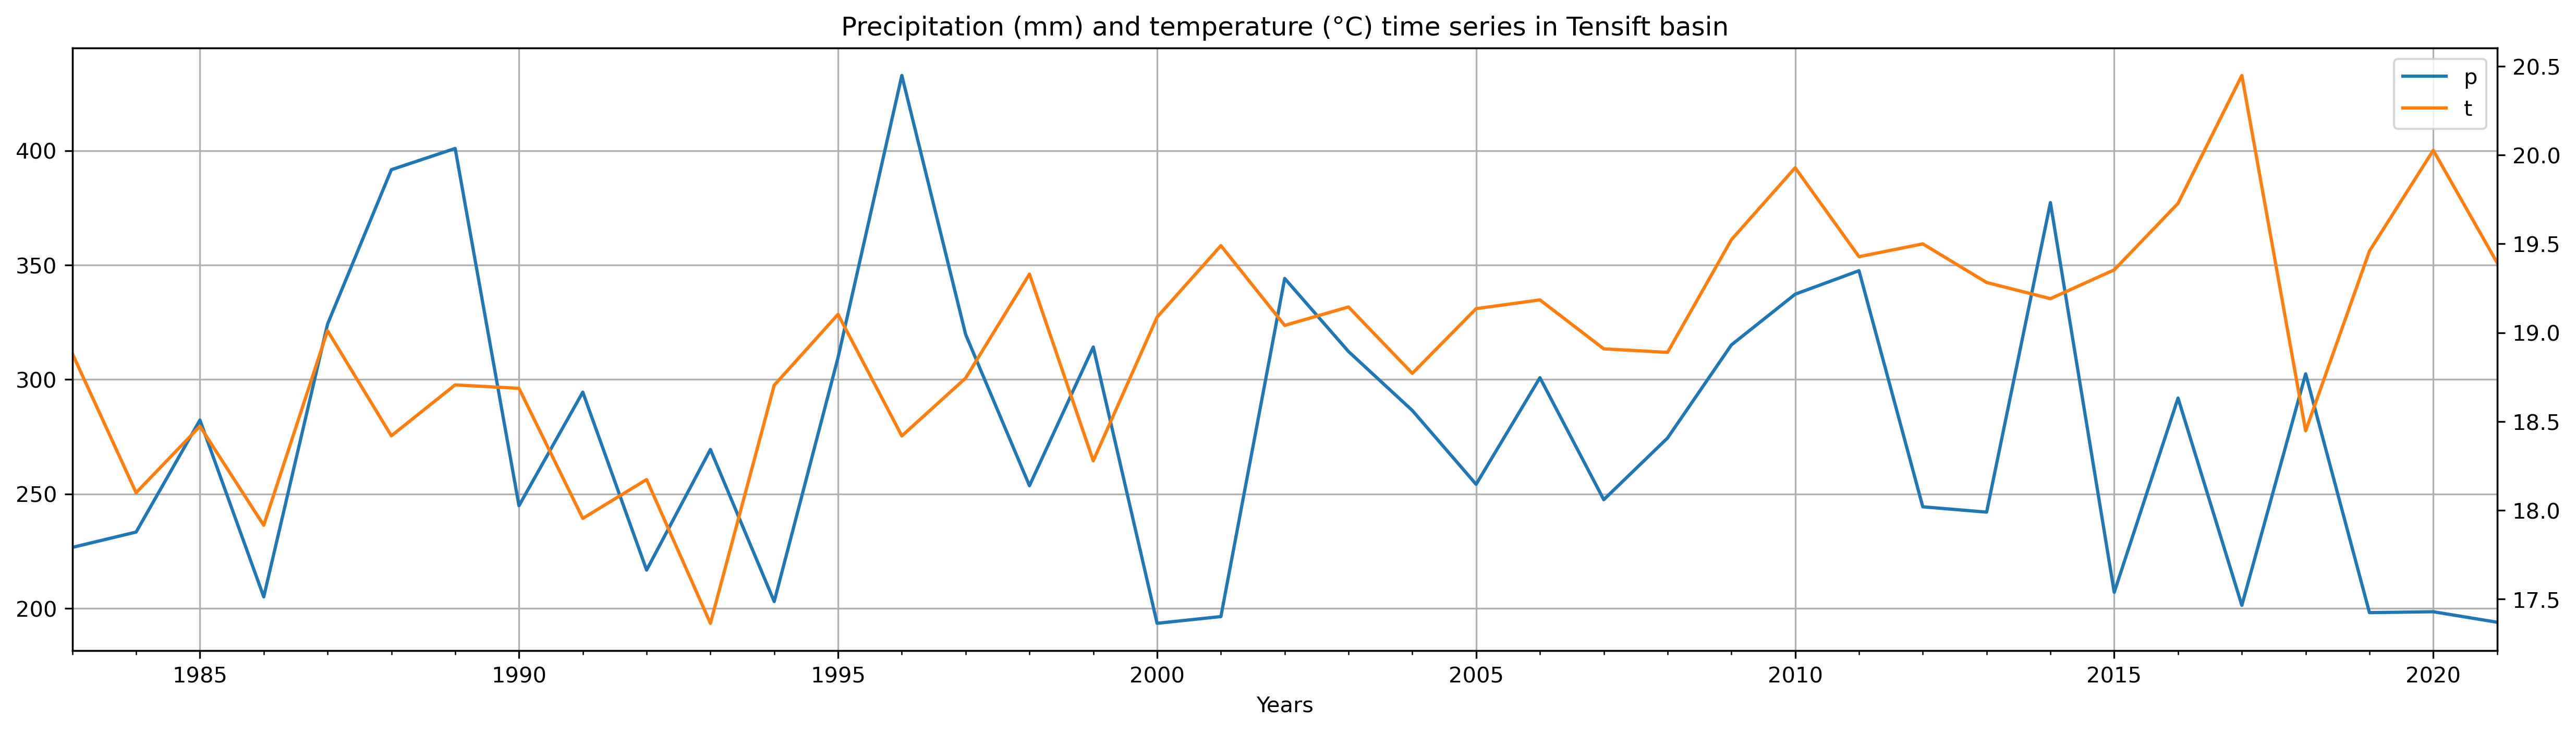

In [90]:
pop = [1477,
       1547, 1548, 1549, 1550, 1551, 1552, 1553,
       1619, 1620, 1621, 1622, 1623]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shpa)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shpa)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(pa, lags=20, ax=axs[0], alpha=0.05, title='P time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ta, lags=20, ax=axs[1], alpha=0.05, title='T time serie Autocorrelation')
plt.show()

avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in Tensift basin')

ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)

In [224]:
pop = [1477,
       1547, 1548, 1549, 1550, 1551, 1552, 1553,
       1619, 1620, 1621, 1622, 1623]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_tensift = pd.DataFrame()
DI_tensift["Dates"]=p["Dates"]
DI = pd.read_csv('outputchirps/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
#DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_tensift["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('outputchirps/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_tensift["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('outputchirps/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
#RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_tensift["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('outputchirps/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_tensift["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('outputchirps/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_tensift["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('outputchirps/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_tensift["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('outputchirps/SPEI.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
#SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(np.Inf, np.nan)
SPEI = SPEI.replace(-np.Inf, np.nan)
SPEI = SPEI.replace(0, np.nan)
DI_tensift["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('outputchirps/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_tensift["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('outputchirps/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_tensift["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('outputchirps/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_tensift["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_tensift = DI_tensift[2:]
DI_tensift

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
2,01-03-83,1.000000,1.000000,0.124745,0.834533,0.834464,-0.843569,-0.929301,-1.870906,-1.870906,-3.125489
3,01-04-83,1.666667,1.000000,0.384690,1.161915,1.161443,-0.459395,-0.515100,-2.183390,-2.183390,-1.515561
4,01-05-83,NaN,1.000000,0.165957,0.839559,0.839562,-0.237716,-0.143736,-1.904878,-1.720874,0.160867
5,01-06-83,NaN,0.333333,-0.852592,0.009617,0.009621,0.244164,0.434492,-1.856952,-1.702668,-0.625531
6,01-07-83,-1.000000,-1.333333,-1.852350,-0.705502,-0.705560,0.771521,1.114297,-1.743454,-1.594400,-0.233304
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.538462,-3.000000,-2.801504,-1.191686,-1.191410,0.830618,0.922806,-3.440979,-3.424233,-0.243409
464,01-09-21,-2.461538,-3.000000,-2.826914,-1.199639,-1.199354,-0.627650,-0.762069,-3.283476,-3.283476,-0.590754
465,01-10-21,-1.461538,-2.461538,-2.359592,-0.901471,-0.901512,-1.181368,-1.328331,-3.727598,-3.727598,-2.346960
466,01-11-21,-1.000000,-1.000000,-1.665484,-0.463399,-0.463429,-1.332359,-1.371461,-3.900374,-3.900374,-1.670156


In [225]:
DI_tensift.to_csv('outputchirps/DI_tensift.csv')

In [93]:
DIc_tensift = pd.DataFrame()
DIc_tensift['Dates'] = DI_tensift['Dates']
#DIc_tensift['DI'] = DI_tensift['DI'].round(0)

index = DI_tensift['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['DI'] = ic

DIc_tensift['PNI'] = DI_tensift['PNI'].round(0)
DIc_tensift['PNI'] = DIc_tensift['PNI'].replace(1, np.nan)

index = DI_tensift['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['RAI'] = ic

index = DI_tensift['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['ZSI'] = ic

index = DI_tensift['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['CZI'] = ic

index = DI_tensift['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['SPI'] = ic

index = DI_tensift['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['SPEI'] = ic

index = DI_tensift['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['PDSI'] = ic

index = DI_tensift['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['scPDSI'] = ic

index = DI_tensift['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['PZI'] = ic
DIc_tensift

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,-1
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
2,01-03-83,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,0,-2
3,01-04-83,2.0,NaN,0.0,1.0,1.0,0.0,0.0,-1,-1,0
4,01-05-83,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,0.0,-2,-2,0
464,01-09-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,0.0,-2,-2,0
465,01-10-21,-1.0,-2.0,-2.0,0.0,0.0,-1.0,-1.0,-2,-2,-1
466,01-11-21,-1.0,-1.0,-1.0,0.0,0.0,-1.0,-1.0,-2,-2,0


In [103]:
DI_tensift['rand'] = (np.random.rand(len(DI_tensift)))/5
DI_tensift['CZI'] = DI_tensift['CZI'].sub(DI_tensift['rand'])
DI_tensift['rand'] = (np.random.rand(len(DI_tensift)))/5
DI_tensift['ZSI'] = DI_tensift['ZSI'].sub(DI_tensift['rand'])
DI_tensift = DI_tensift.drop(['rand'], axis=1)

DI_tensift

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.921859,-0.921859,-2.765577
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.872614,-0.837405,-0.292108
2,01-03-83,1.000000,1.000000,0.124745,0.391735,0.417922,-0.843569,-0.929301,-1.870906,-1.870906,-3.125489
3,01-04-83,1.666667,1.000000,0.384690,0.675138,0.967888,-0.459395,-0.515100,-2.183390,-2.183390,-1.515561
4,01-05-83,NaN,1.000000,0.165957,0.506409,0.311816,-0.237716,-0.143736,-1.904878,-1.720874,0.160867
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.538462,-3.000000,-2.801504,-1.680212,-1.748103,0.830618,0.922806,-3.440979,-3.424233,-0.243409
464,01-09-21,-2.461538,-3.000000,-2.826914,-2.050244,-2.096592,-0.627650,-0.762069,-3.283476,-3.283476,-0.590754
465,01-10-21,-1.461538,-2.461538,-2.359592,-1.510754,-1.196708,-1.181368,-1.328331,-3.727598,-3.727598,-2.346960
466,01-11-21,-1.000000,-1.000000,-1.665484,-1.266467,-0.788047,-1.332359,-1.371461,-3.900374,-3.900374,-1.670156


<AxesSubplot:title={'center':'Tensift Basin (Semi-arid)'}, ylabel='Value'>

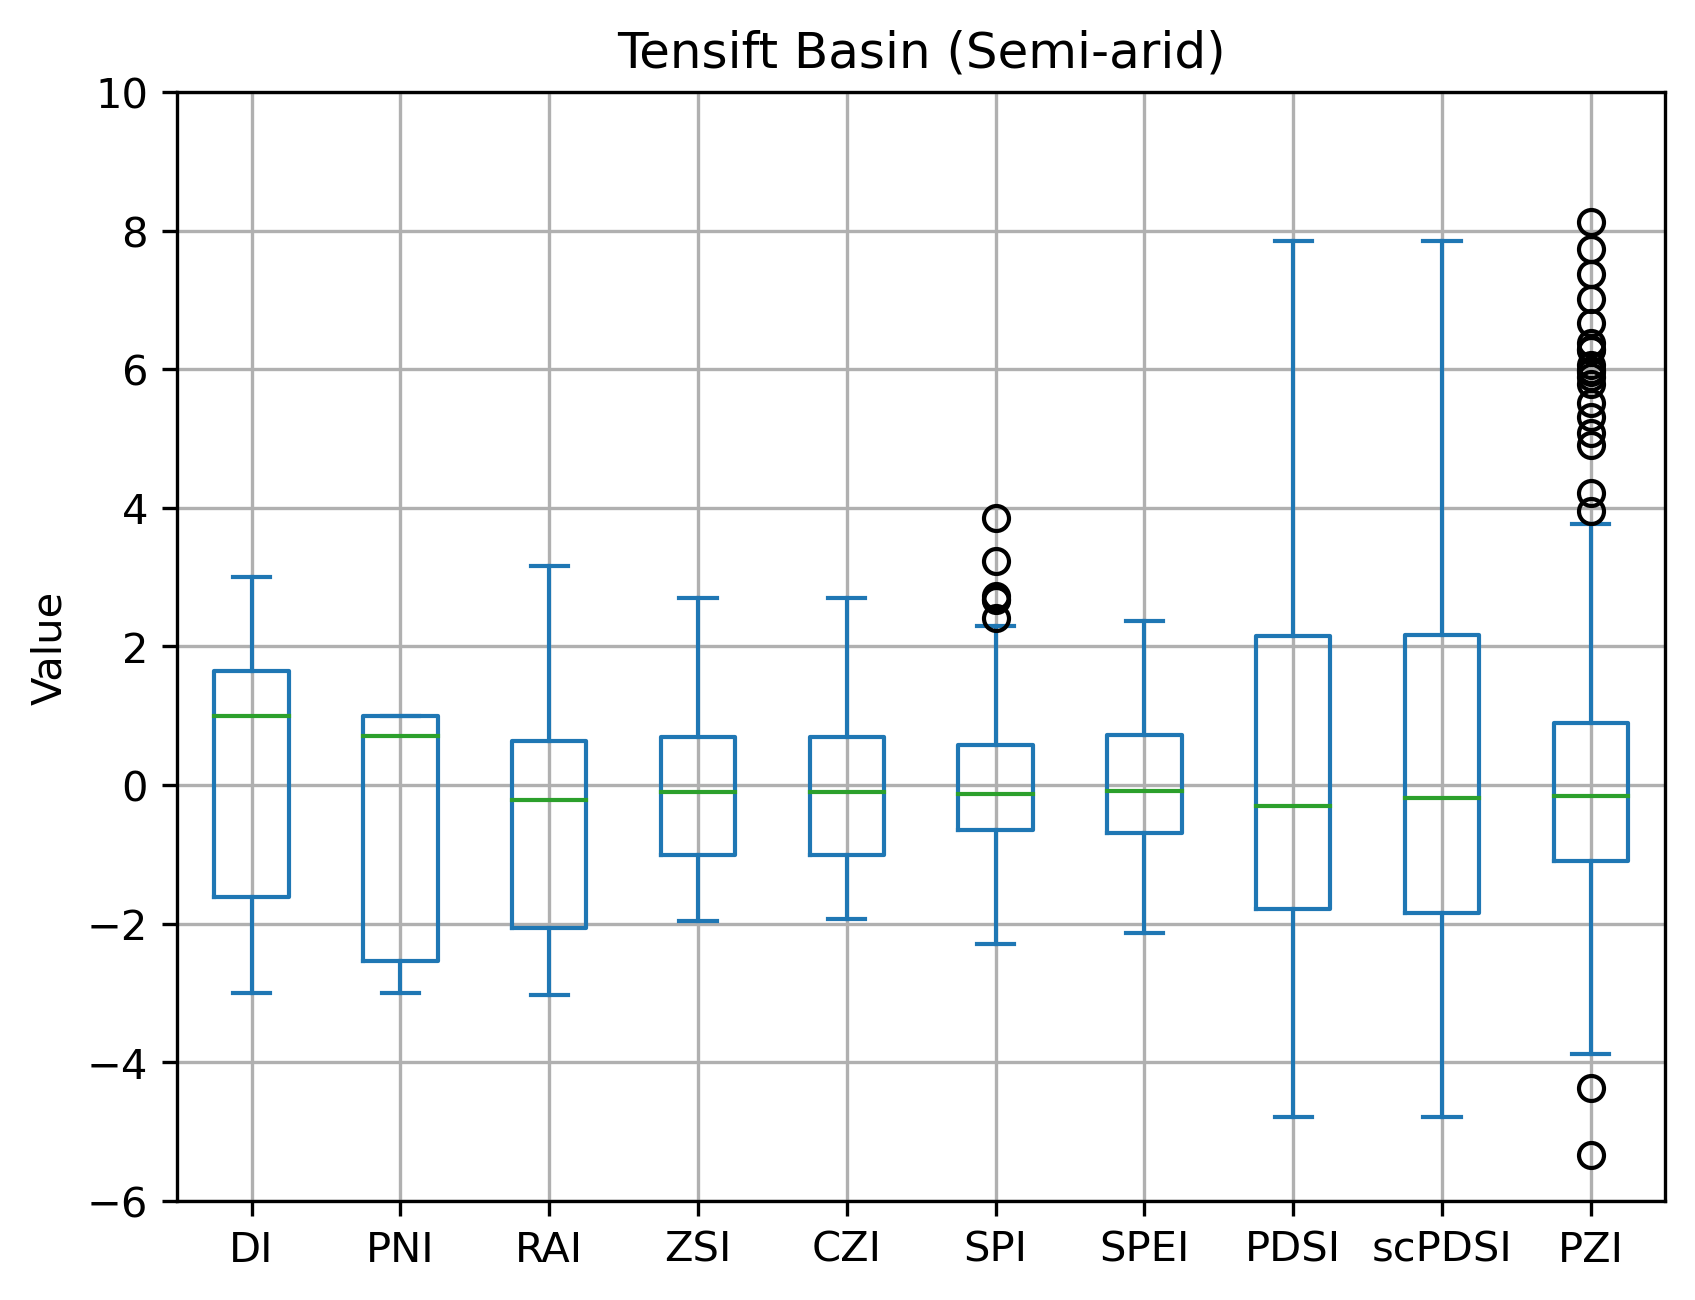

In [95]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
DI_tensift.plot(kind='box', title='Tensift Basin (Semi-arid)', grid = True, ylim = (-6, 10), ylabel='Value')

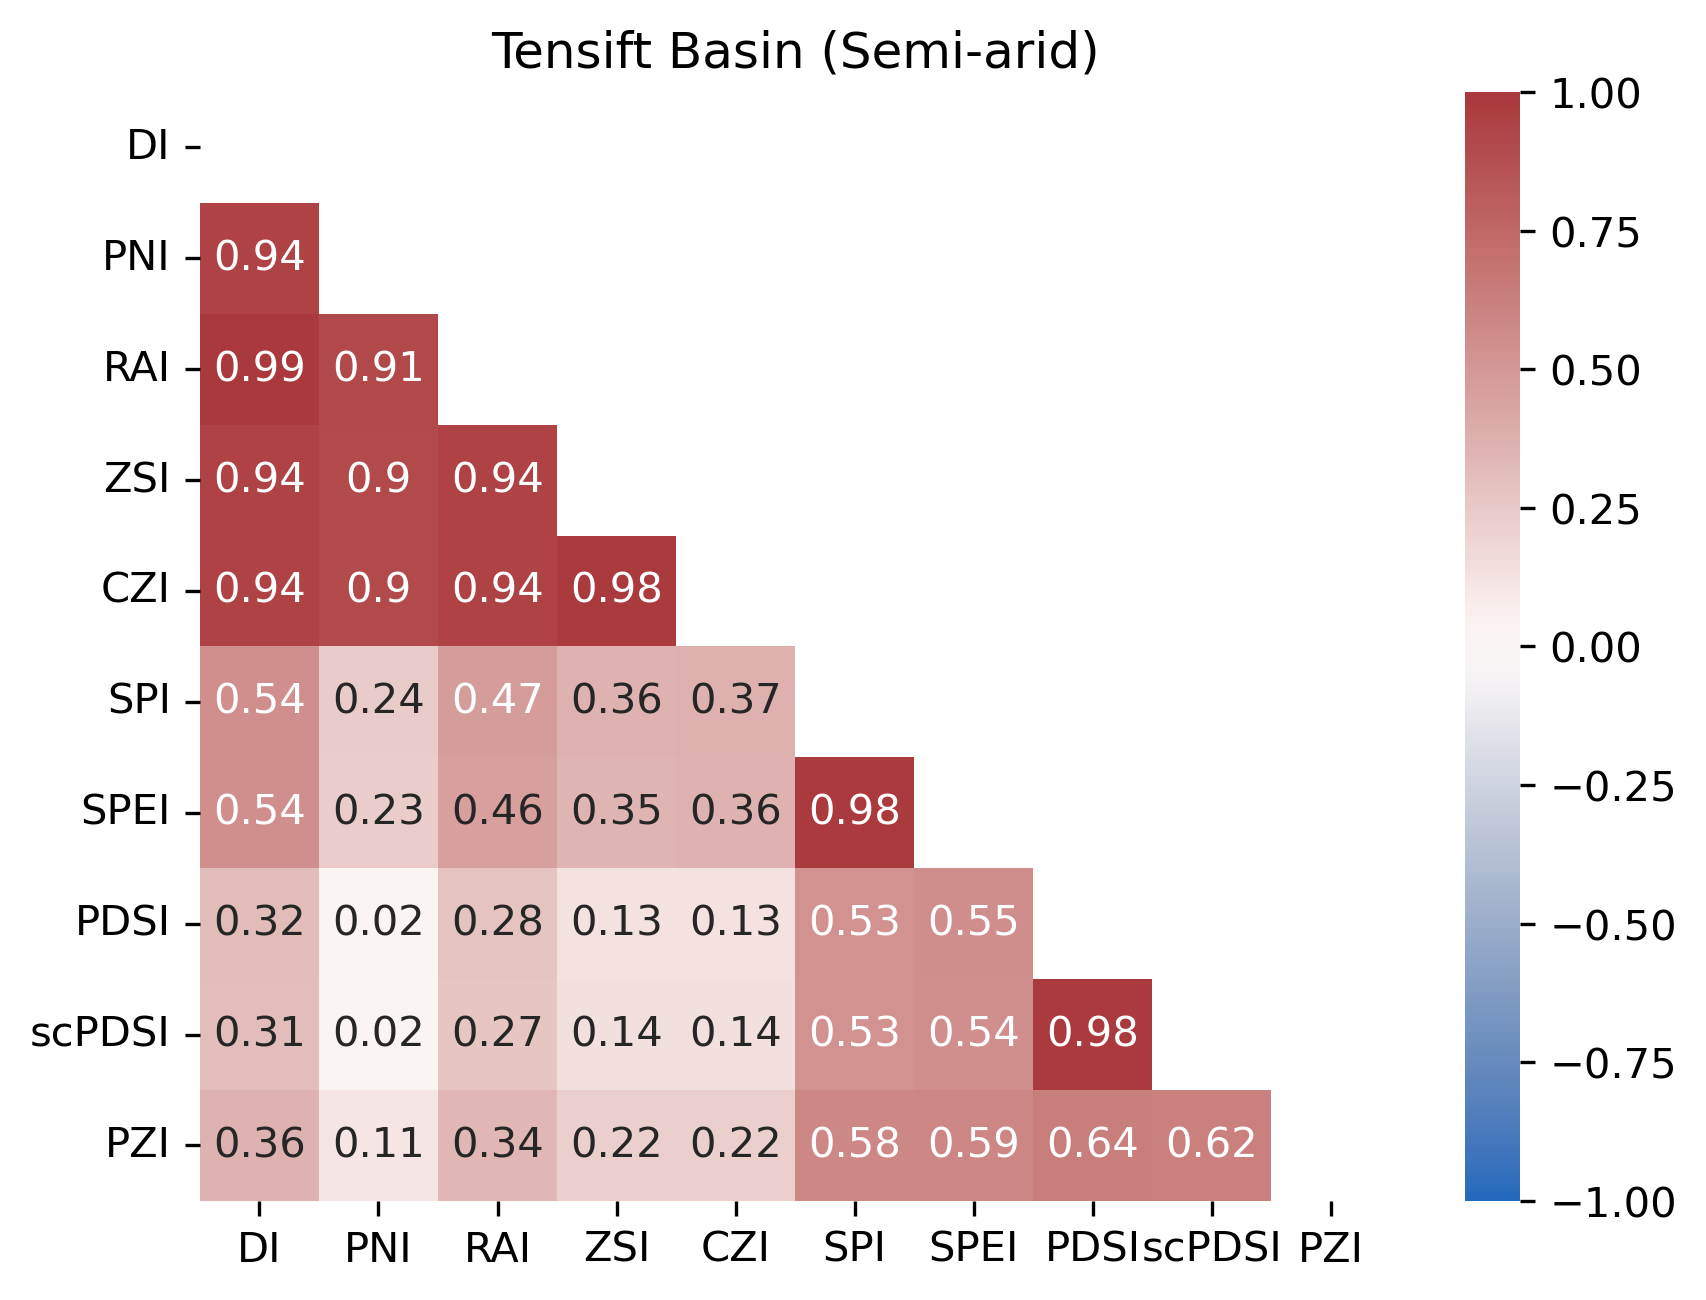

In [118]:
#DI_tensift = DI_tensift.drop(['Dates'], axis=1)
DI_tensift.replace([np.inf, -np.inf], np.nan, inplace=True)
DI_tensift.dropna()
#pvalue = calculate_pvalues(DI_tensift)
matrix = DI_tensift.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
#pvalue = pvalue.astype(float).round(3)
#sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Tensift Basin (Semi-arid)")
plt.show()

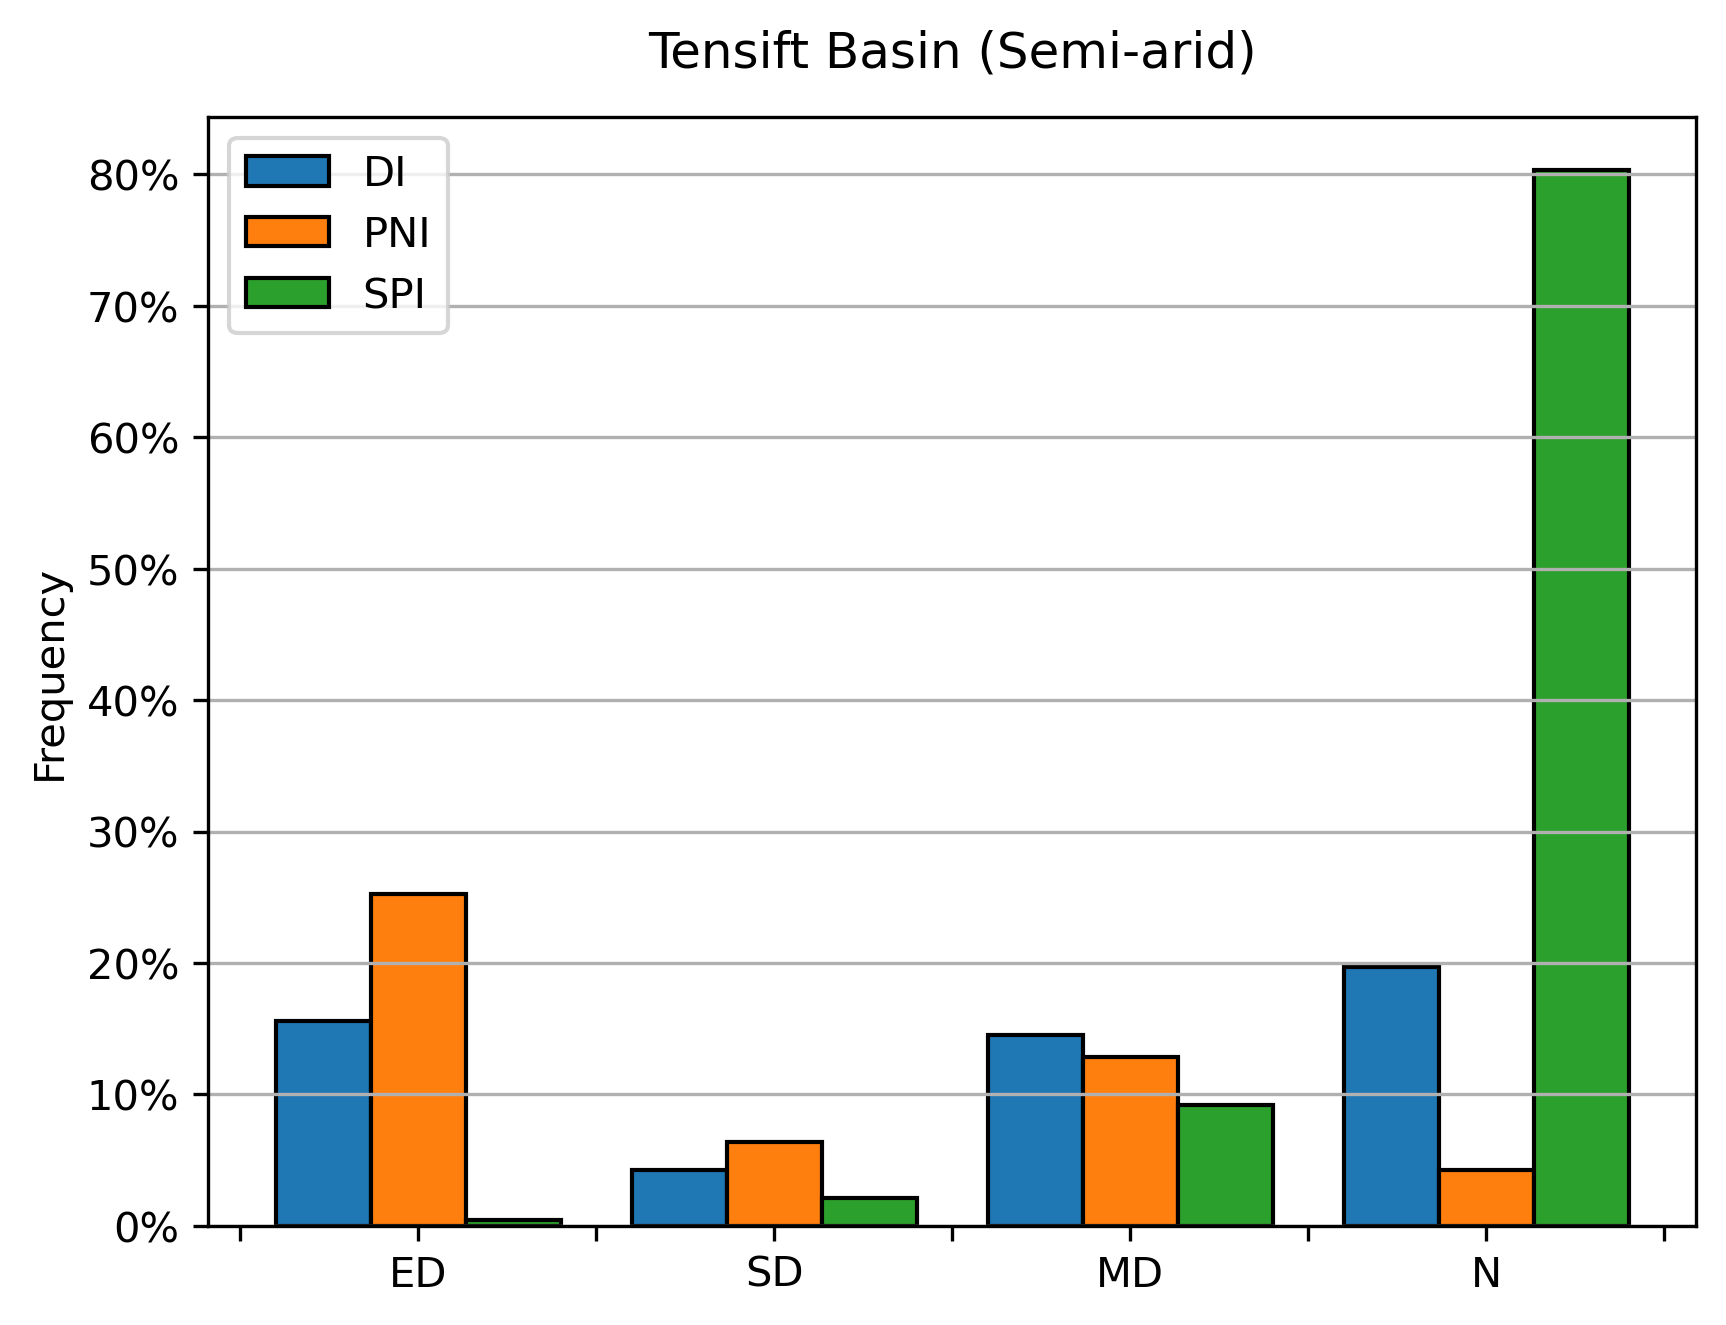

In [107]:
#create relative frequency histogram with percentages on y-axis
data = DIc_tensift[['DI', 'PNI', 'SPI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['DI', 'PNI', 'SPI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.grid(axis='y')
ax.set_title('Tensift Basin (Semi-arid)', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [417]:
DI_tensift.set_index("Dates", inplace = True)
DI_tensift.index = pd.to_datetime(DI_tensift.index, format='%Y/%m/%d')

In [ ]:

data = DI_tensift
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Tensift basin')
axs[0].plot(data.index, data['RAI'], label='RAI')
axs[0].legend()
axs[1].plot(data.index, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(data.index, data['SPEI'], label='SPEI')
axs[2].legend()
#axs[3].plot(data.index, data['PDSI'])
#axs[4].plot(data.index, data['scPDSI'])
#axs[5].plot(data.index, data['PZI'])
#axs[2].plot(x, y, '+')

# Hide x labels and tick labels for all but bottom plot.
for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_tensift
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

<Axes: title={'center': 'Time series of Drought Indices in Tensift basin during 2019 drought spell'}, xlabel='Months'>

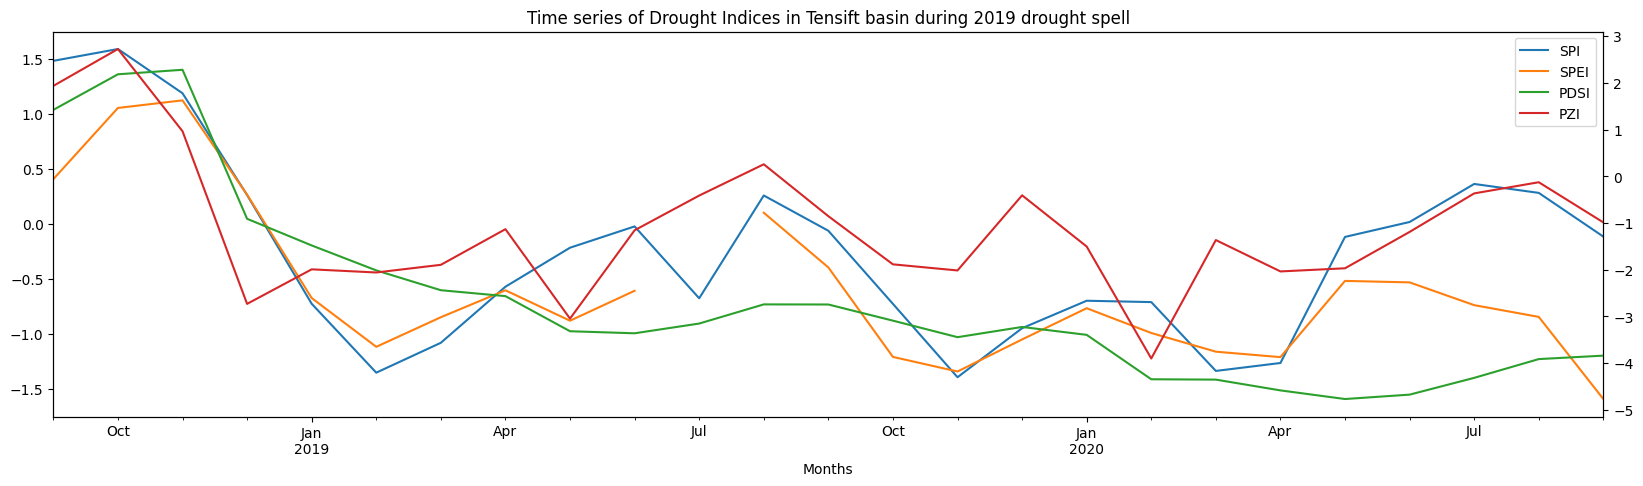

In [658]:
DI_tensift[428:453].loc[:,['SPI','SPEI','PDSI','PZI']].plot(secondary_y=['PDSI', 'PZI'], mark_right=False, figsize = (20,5), xlabel='Months', title='Time series of Drought Indices in Tensift basin during 2019 drought spell')

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.4679538135260932, z=-0.7258123521665456, Tau=-0.08232118758434548, s=-61.0, var_s=6833.666666666667, slope=-0.004875892035657877, intercept=-0.4493052278102191)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.7348263750767032, z=-0.33871243101105464, Tau=-0.03913630229419703, s=-29.0, var_s=6833.666666666667, slope=-0.0028142952313957477, intercept=0.09322109029100215)
SPEI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.357906094864779, z=-0.9193623127442911, Tau=-0.1039136302294197, s=-77.0, var_s=6833.666666666667, slope=-0.00788880077043854, intercept=0.10440193585481058)
scPDSI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.011864484832549982, z=-2.516149487510692, Tau=-0.28205128205128205, s=-209.0, var_s=6833.666666666667, slope=-0.09012693641016149, intercept=1.2126570524689049)
PZI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.03530386033195576, z=-2.104855821282982, Tau=-0.23616734143049933, s=-1

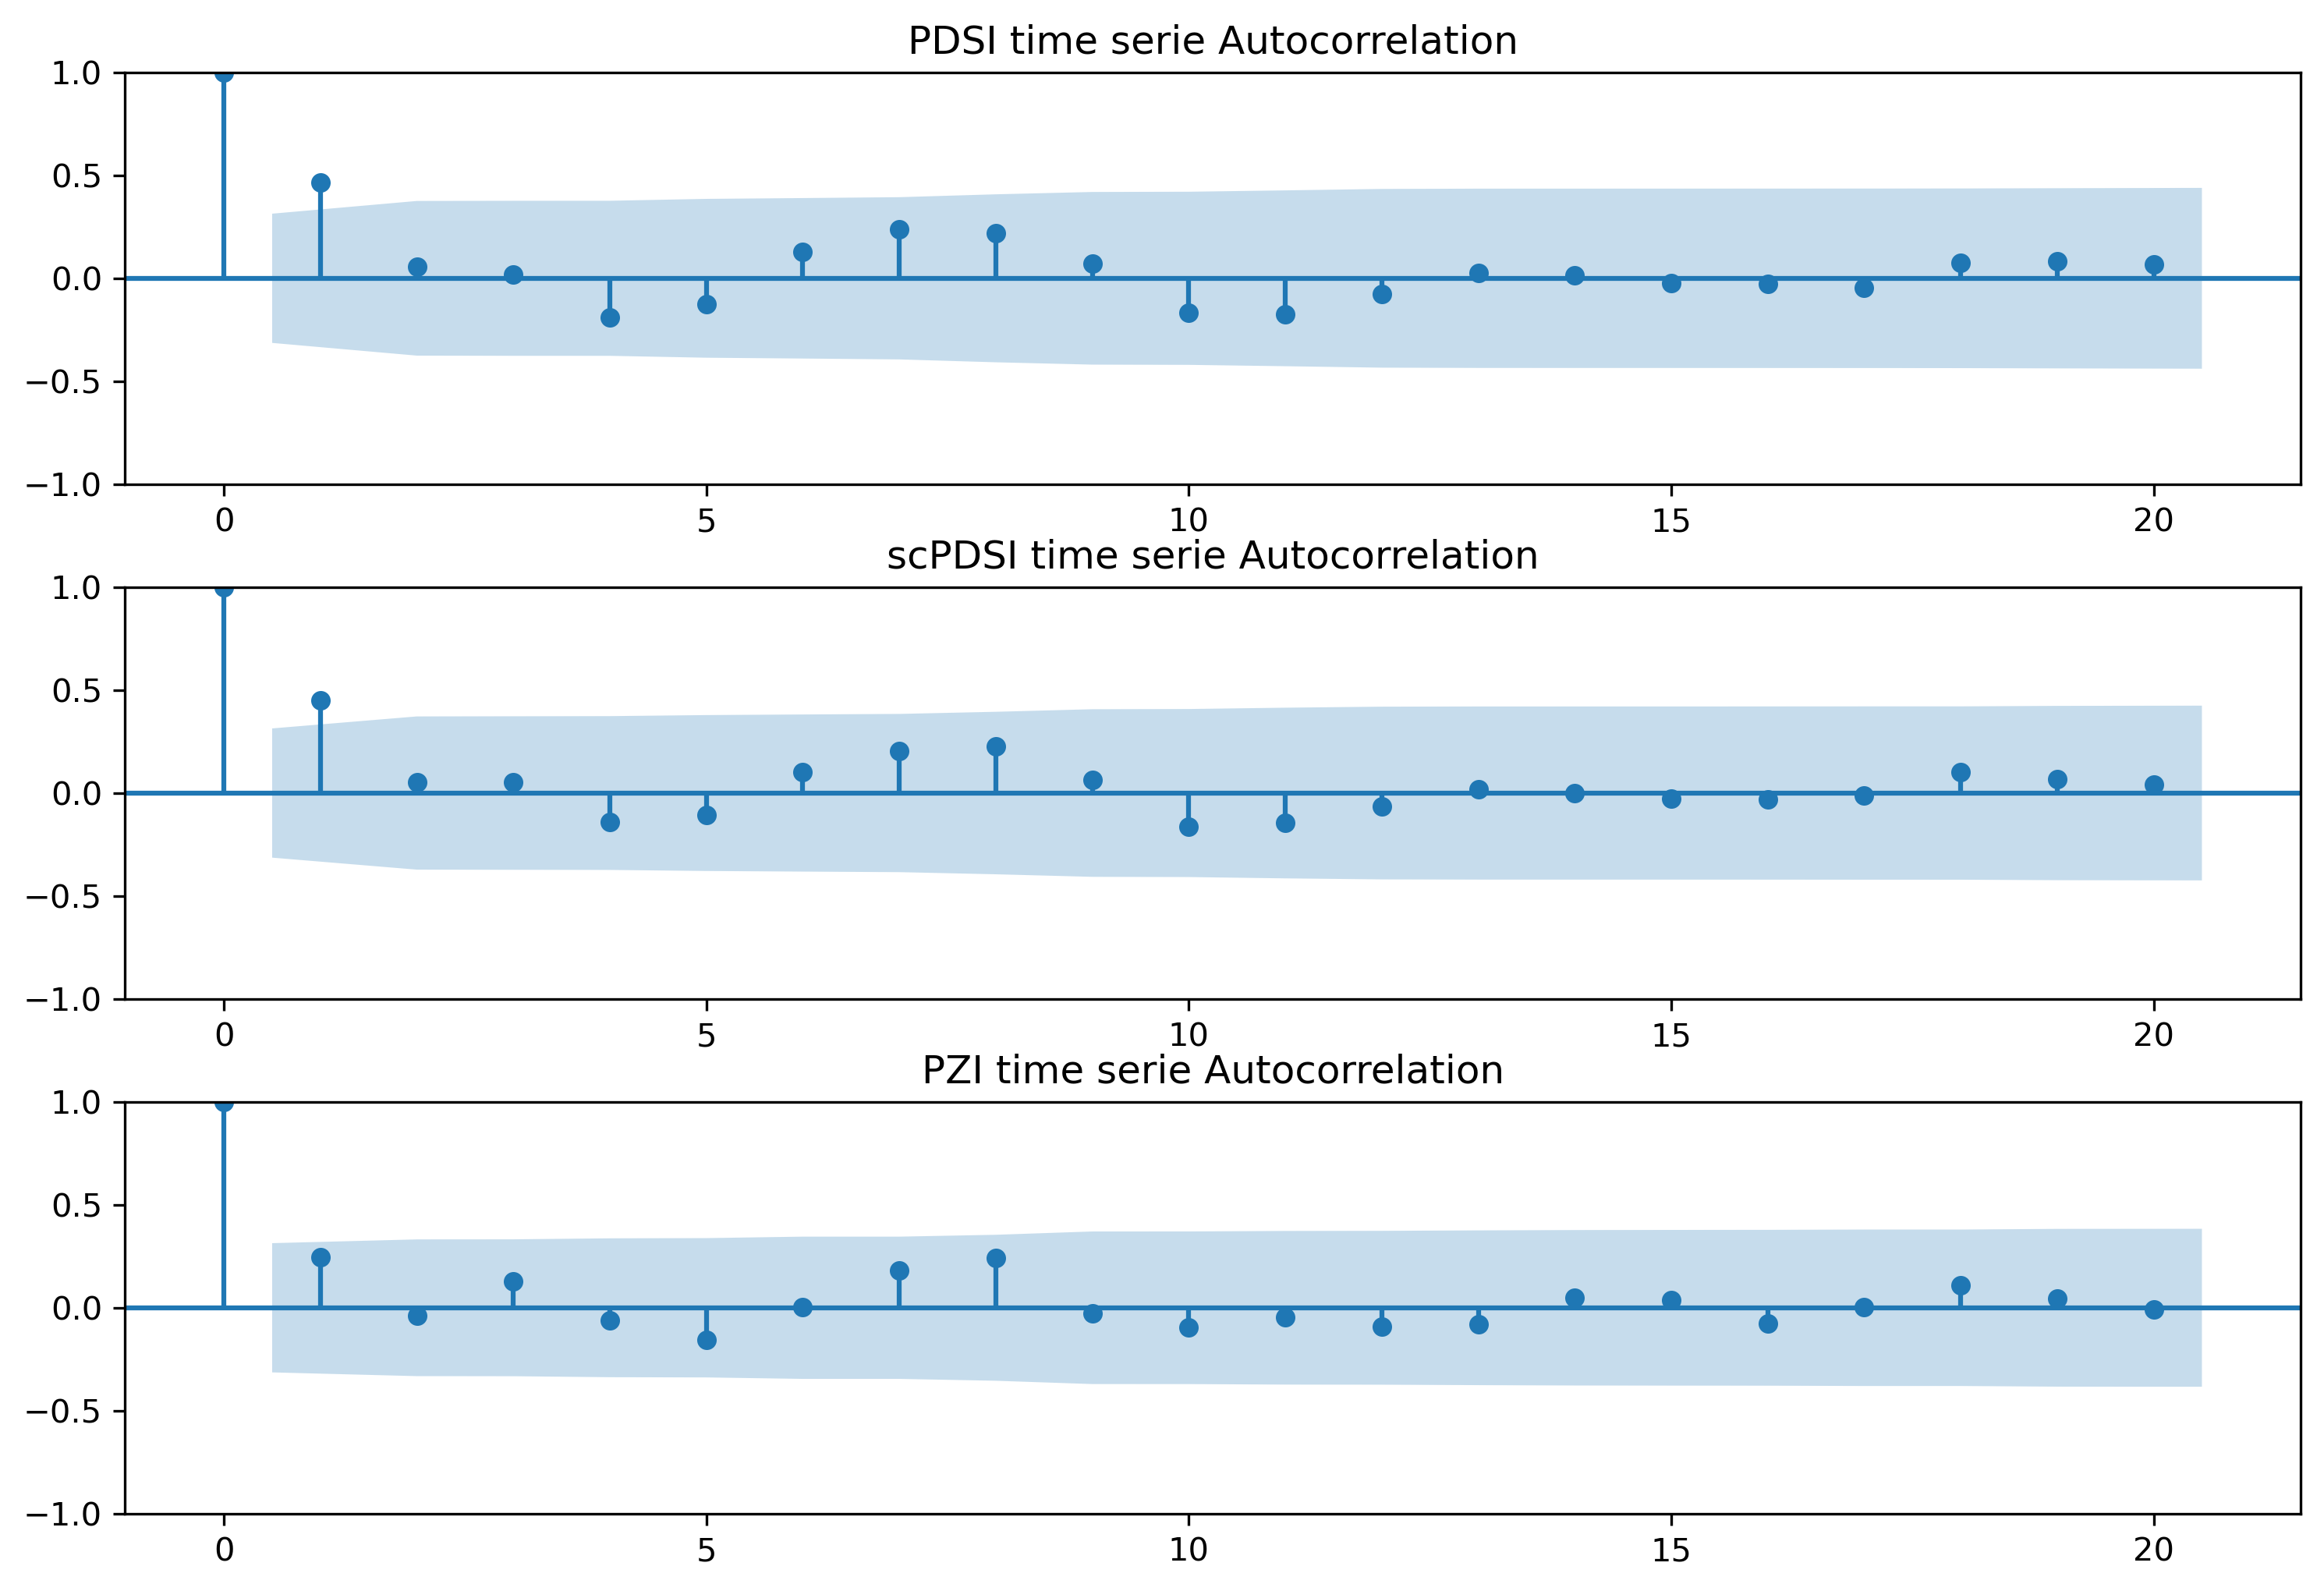

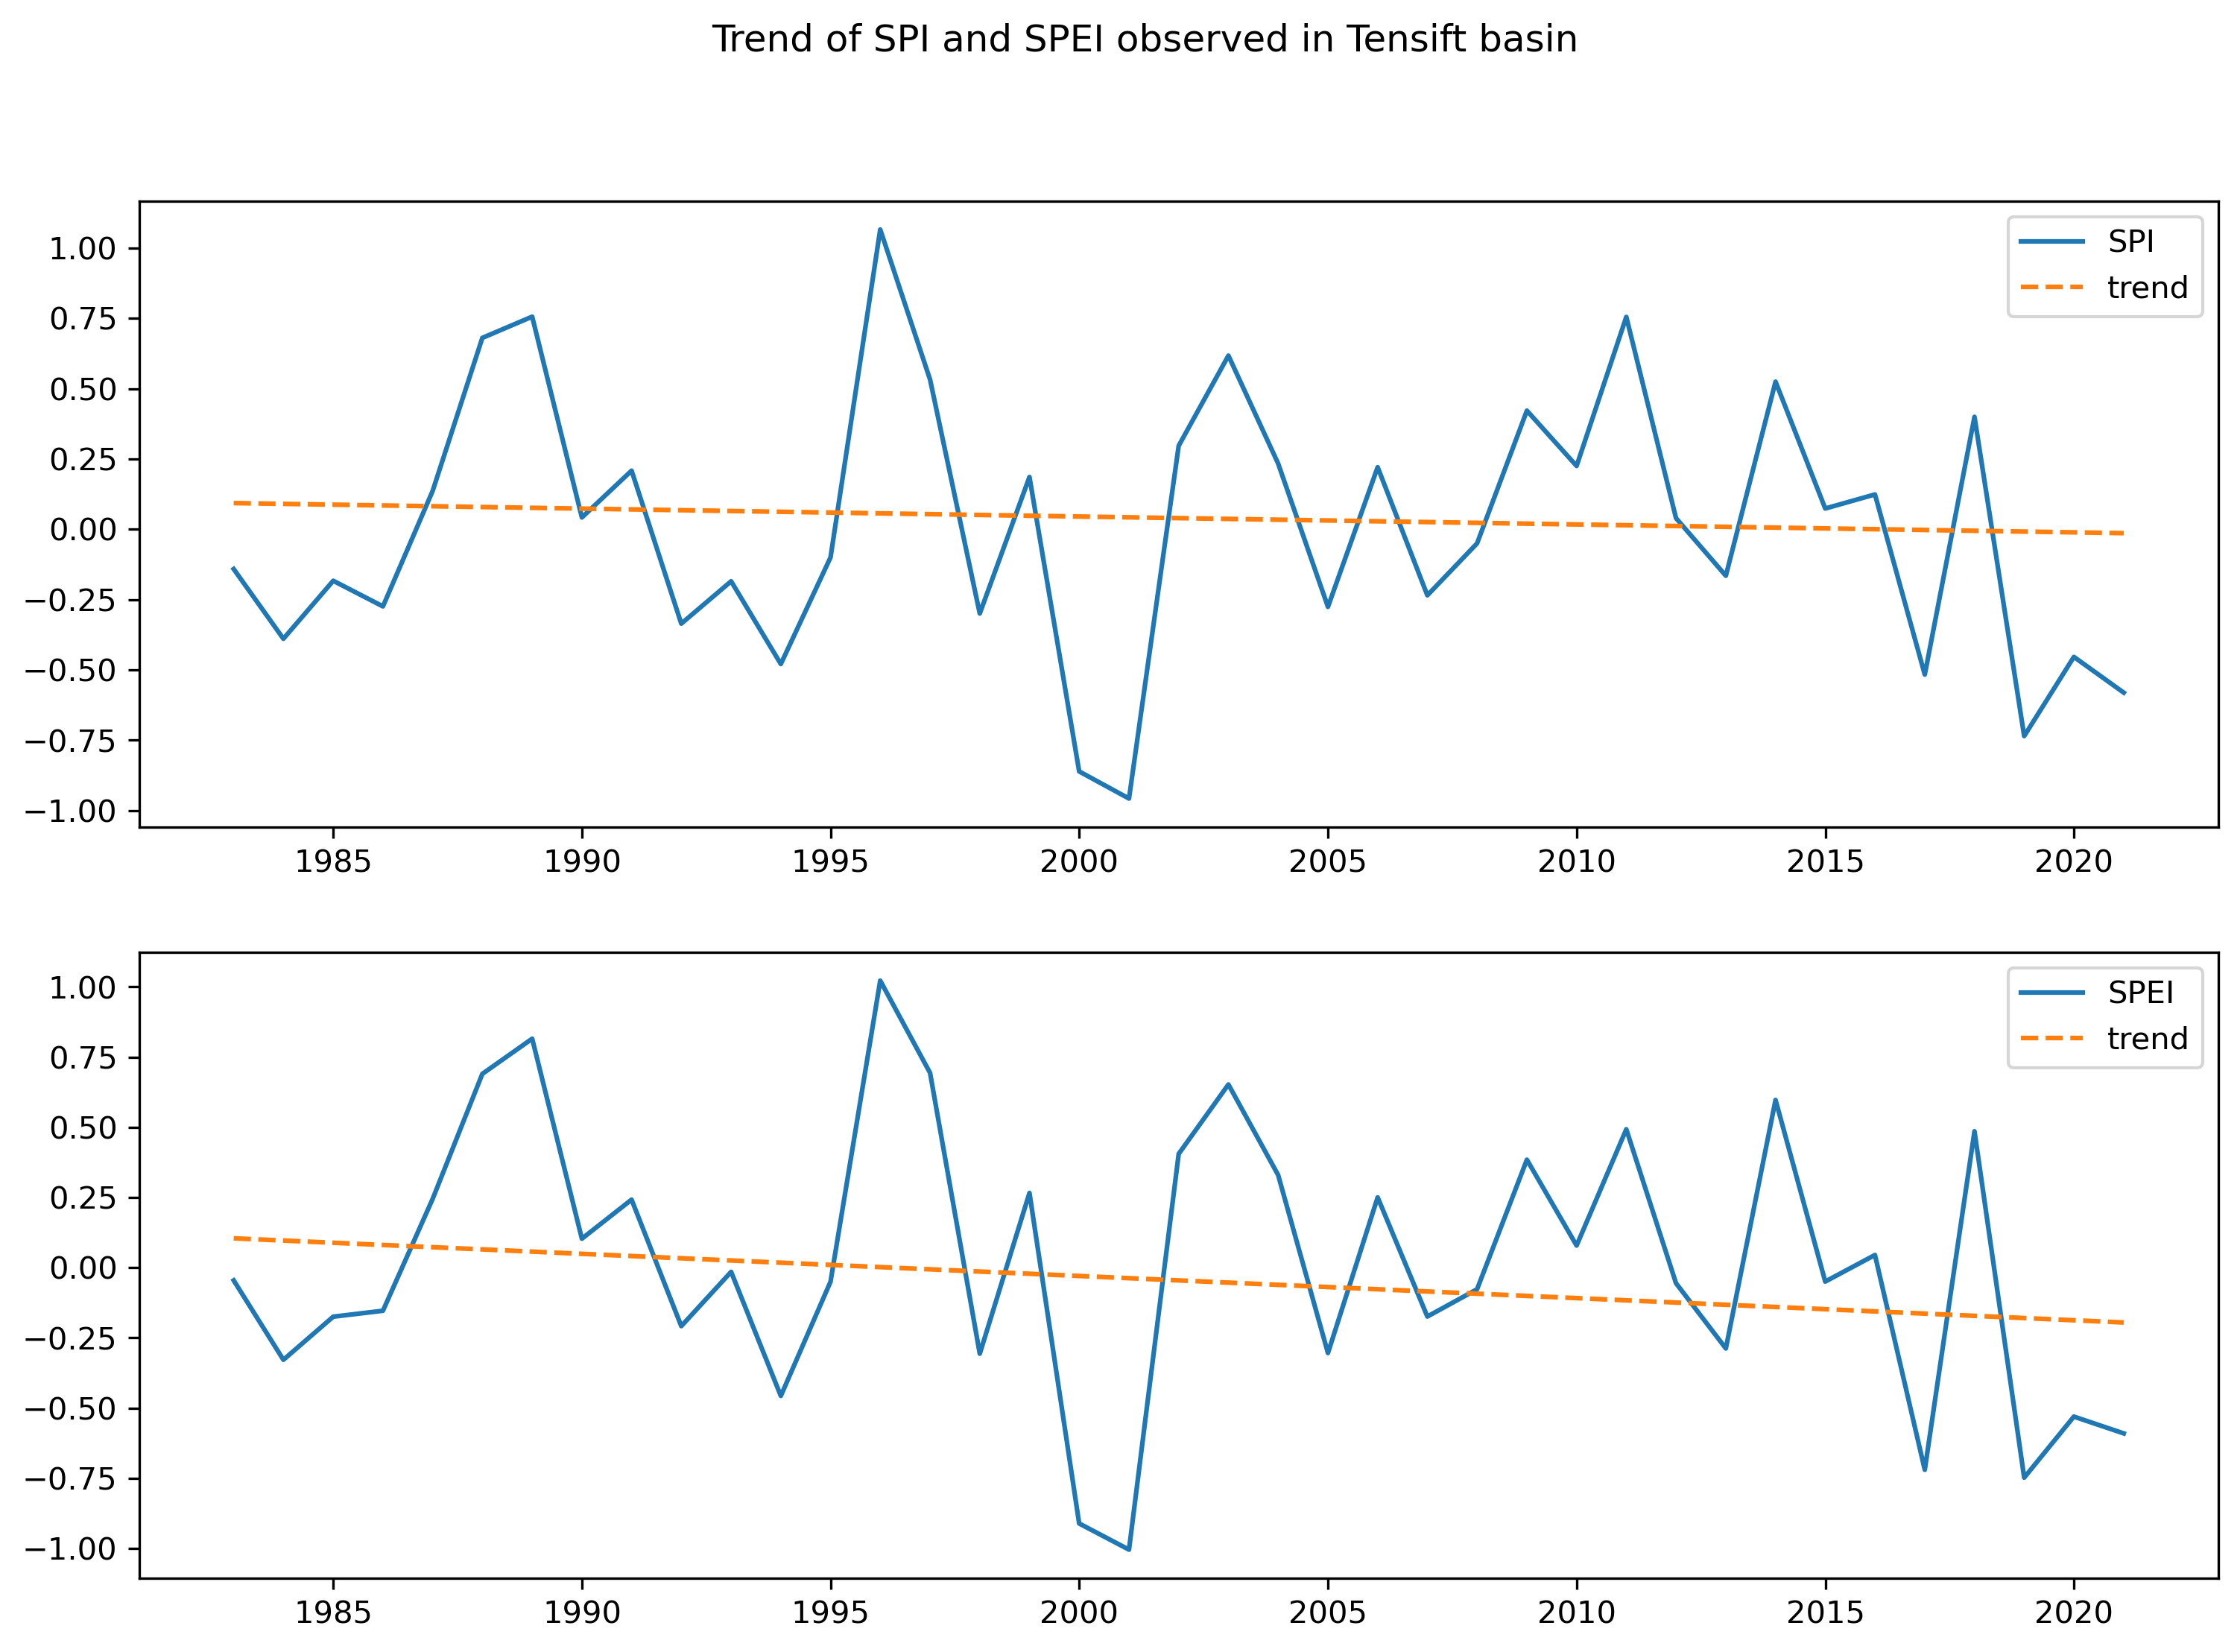

In [112]:
#trend analysis of spi and spei
arai = [np.nansum(DI_tensift['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_tensift['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_tensift['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_tensift['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_tensift['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_tensift['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()

datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Tensift basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

plt.show()

**Sous-Massa Basin with mask on pixels > 1000m**

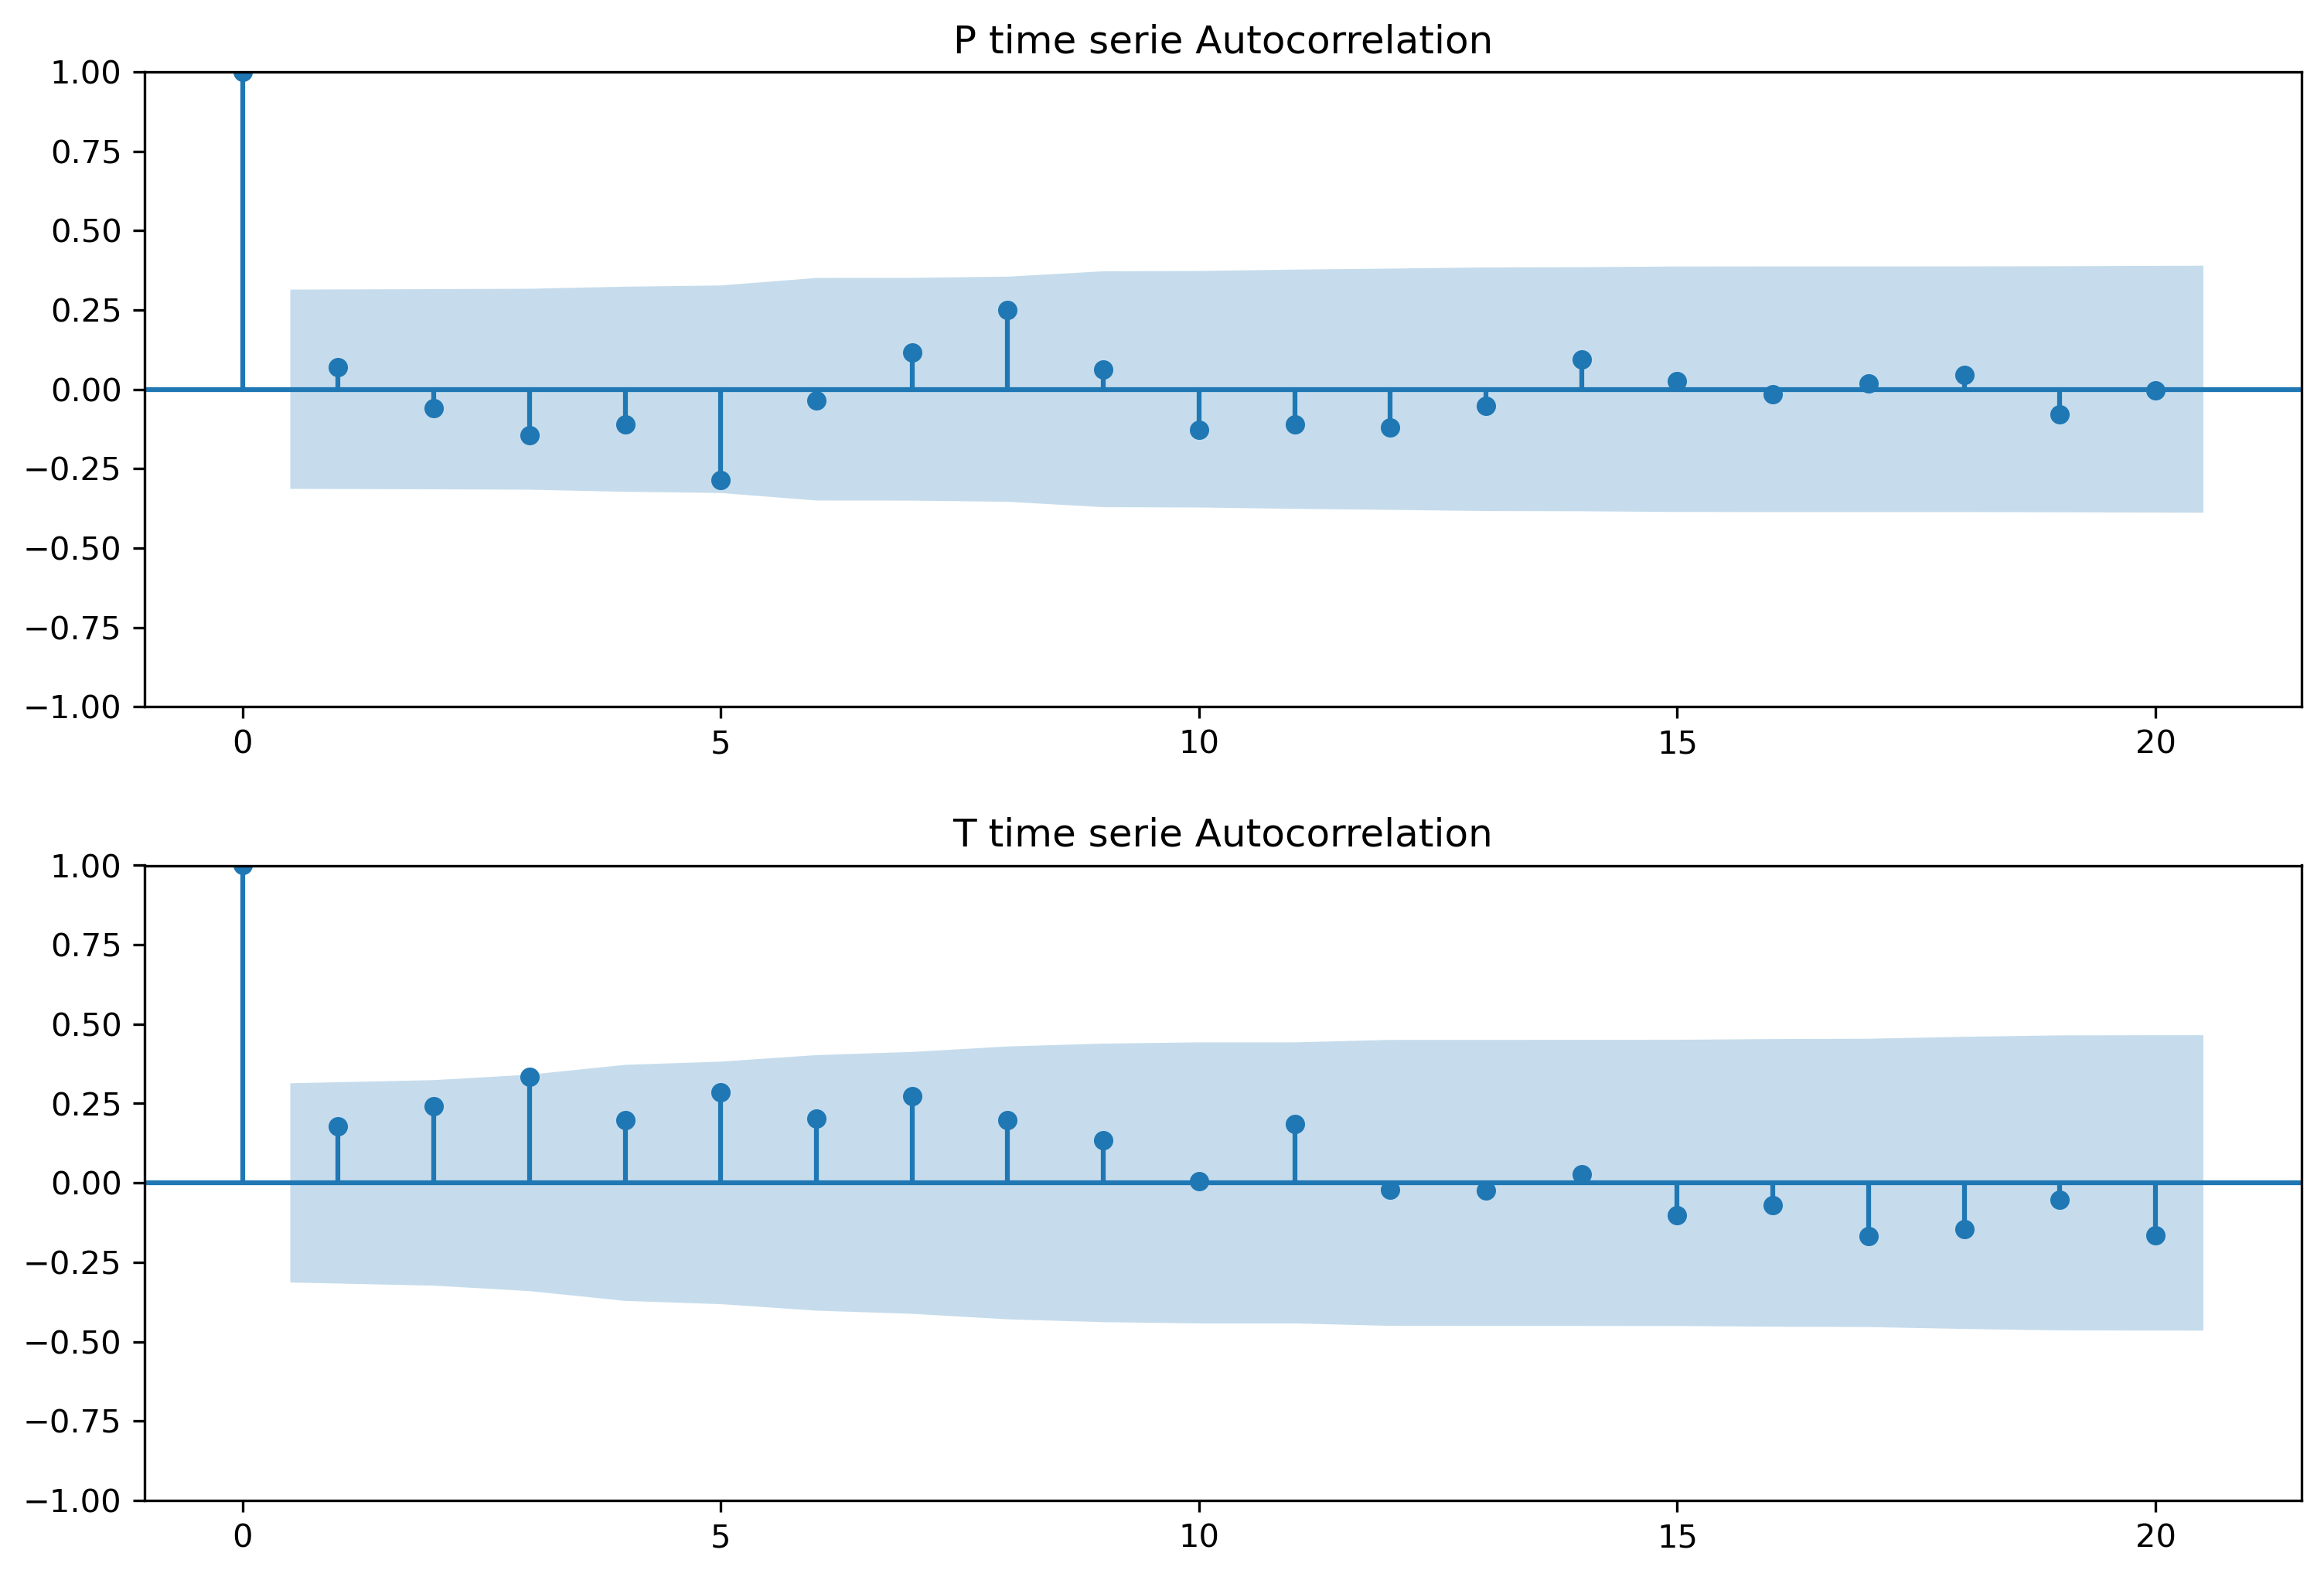

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.8465282828044682, z=-0.1935499605777455, Tau=-0.022941970310391364, s=-17.0, var_s=6833.666666666667, slope=-0.23027213551283965, intercept=191.63552780730134)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=0.0001456226035256858, z=3.7984179763382557, Tau=0.4251012145748988, s=315.0, var_s=6833.666666666667, slope=0.028385407696759124, intercept=19.801279374131944)


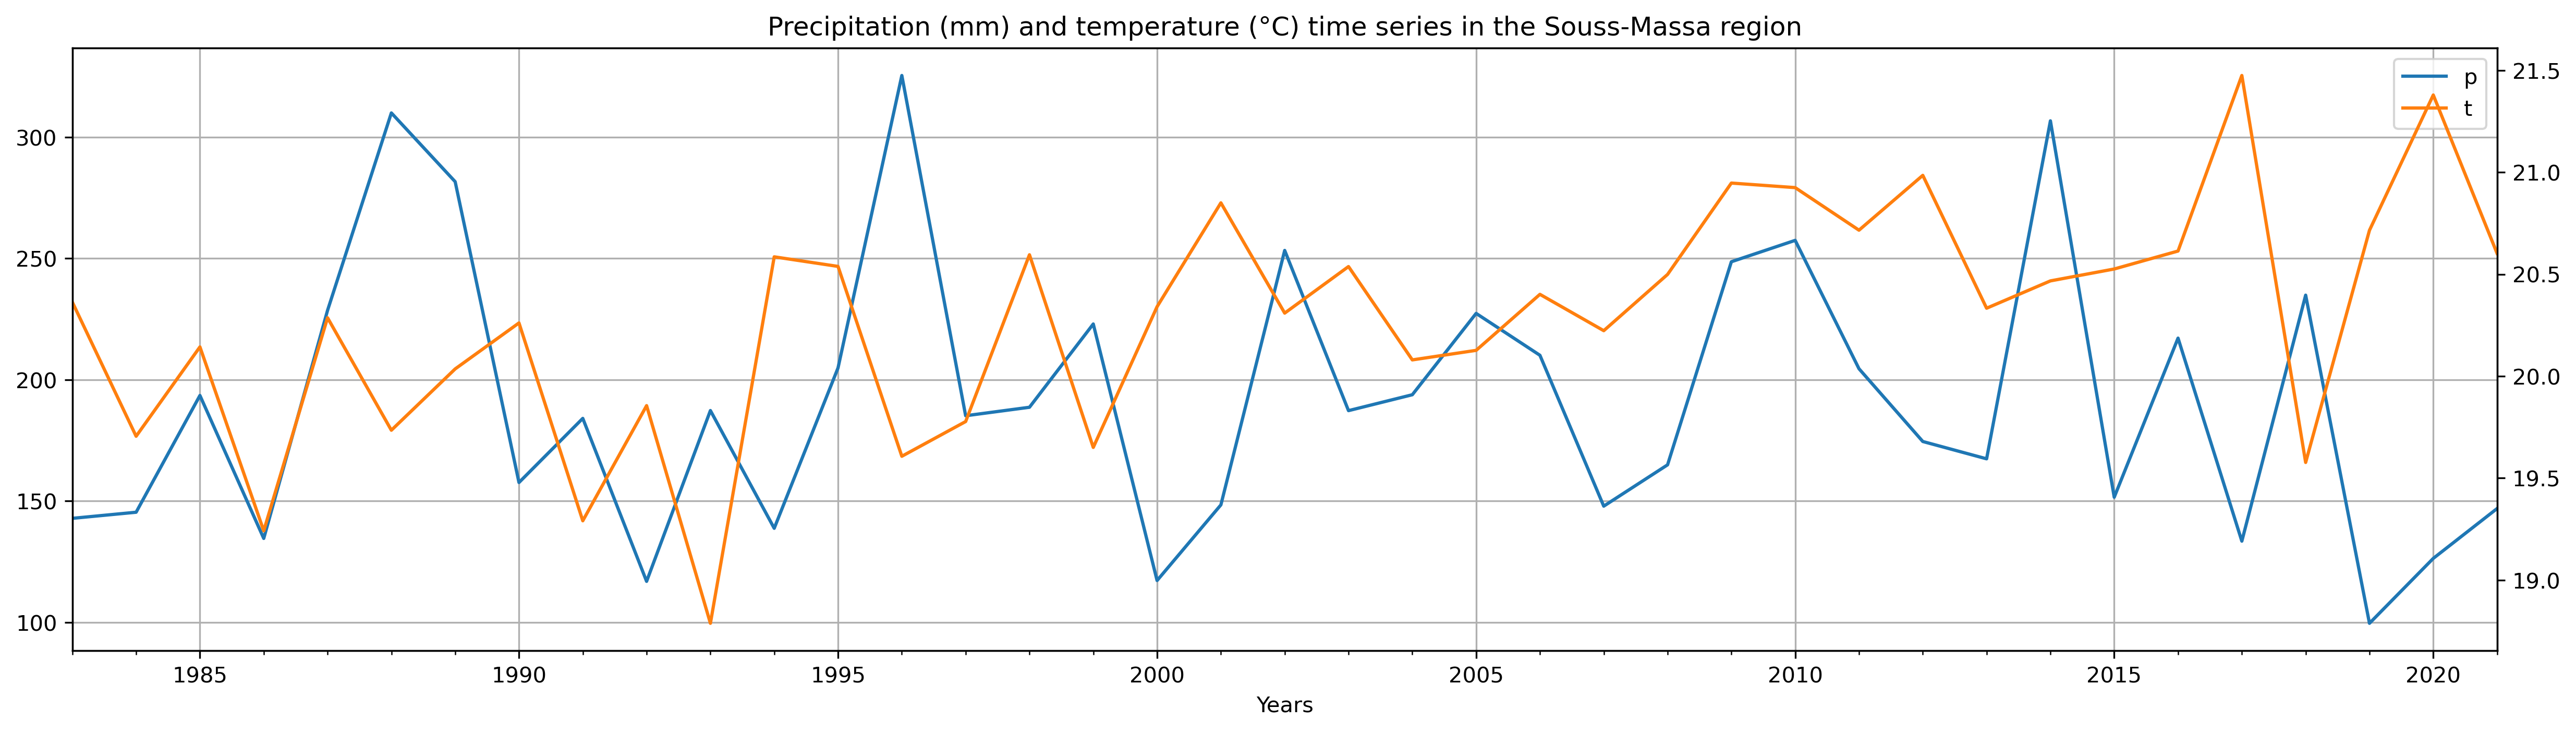

In [113]:
pop = [1906, 1907, 1908,
       1977, 1978, 1979,
       2049, 2050,
       2121]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shpa)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shpa)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(pa, lags=20, ax=axs[0], alpha=0.05, title='P time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ta, lags=20, ax=axs[1], alpha=0.05, title='T time serie Autocorrelation')
plt.show()

avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in the Souss-Massa region')

ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)

In [226]:
pop = [1906, 1907, 1908,
       1977, 1978, 1979,
       2049, 2050,
       2121]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_souss = pd.DataFrame()
DI_souss["Dates"]=p["Dates"]
DI = pd.read_csv('outputchirps/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
#DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_souss["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('outputchirps/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_souss["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('outputchirps/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
#RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_souss["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('outputchirps/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_souss["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('outputchirps/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_souss["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('outputchirps/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_souss["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('outputchirps/SPEI.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
#SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(np.Inf, np.nan)
SPEI = SPEI.replace(-np.Inf, np.nan)
SPEI = SPEI.replace(0, np.nan)
DI_souss["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('outputchirps/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_souss["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('outputchirps/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_souss["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('outputchirps/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_souss["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_souss = DI_souss[2:]
DI_souss

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
2,01-03-83,1.000000,1.000000,0.328960,1.486131,1.484554,-0.540330,-0.604286,-2.112046,-2.112046,-4.096431
3,01-04-83,1.000000,1.000000,0.195999,1.195403,1.194979,-0.153719,-0.221356,-2.284592,-2.284592,-1.170260
4,01-05-83,NaN,1.000000,-0.747724,0.264436,0.264447,-0.195453,-0.183713,-1.980086,-1.794413,0.207579
5,01-06-83,NaN,-1.000000,-1.757332,-0.431886,-0.431911,0.485482,0.724653,-1.861600,-1.678219,-0.256390
6,01-07-83,-1.000000,-2.777778,-2.458609,-0.918297,-0.918333,1.603278,1.682455,-1.694316,-1.481030,-0.073383
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.888889,-3.000000,-2.939232,-0.999778,-0.999776,0.890382,0.759934,-2.354787,-2.283941,-0.048413
464,01-09-21,-2.000000,-3.000000,-2.862152,-0.966070,-0.966091,-0.422181,-0.240080,-2.186709,-2.138561,-0.223397
465,01-10-21,-1.000000,-3.000000,-2.529147,-0.820053,-0.820116,-1.092545,-1.203031,-2.731949,-2.731949,-2.311413
466,01-11-21,NaN,-1.000000,-1.294489,-0.274892,-0.274899,-0.827241,-0.935731,-2.764755,-2.764755,-0.942588


In [227]:
DI_souss.to_csv('outputchirps/DI_souss.csv')

In [116]:
DIc_souss = pd.DataFrame()
DIc_souss['Dates'] = DI_souss['Dates']
#DIc_souss['DI'] = DI_souss['DI'].round(0)

index = DI_souss['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['DI'] = ic

DIc_souss['PNI'] = DI_souss['PNI'].round(0)
DIc_souss['PNI'] = DIc_souss['PNI'].replace(1, np.nan)

index = DI_souss['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['RAI'] = ic

index = DI_souss['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['ZSI'] = ic

index = DI_souss['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['CZI'] = ic

index = DI_souss['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPI'] = ic

index = DI_souss['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPEI'] = ic

index = DI_souss['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PDSI'] = ic

index = DI_souss['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['scPDSI'] = ic

index = DI_souss['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PZI'] = ic
DIc_souss

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,-1
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
2,01-03-83,0.0,NaN,0.0,1.0,1.0,0.0,0.0,-1,-1,-3
3,01-04-83,0.0,NaN,0.0,1.0,1.0,0.0,0.0,-1,-1,0
4,01-05-83,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,0.0,0.0,0.0,0.0,-1,-1,0
464,01-09-21,-3.0,-3.0,-2.0,0.0,0.0,0.0,0.0,-1,-1,0
465,01-10-21,-1.0,-3.0,-2.0,0.0,0.0,-1.0,-1.0,-1,-1,-1
466,01-11-21,NaN,-1.0,-1.0,0.0,0.0,0.0,0.0,-1,-1,0


In [129]:
DI_souss['rand'] = (np.random.rand(len(DI_souss)))/5
DI_souss['CZI'] = DI_souss['CZI'].sub(DI_souss['rand'])
DI_souss['rand'] = (np.random.rand(len(DI_souss)))/5
DI_souss['ZSI'] = DI_souss['ZSI'].sub(DI_souss['rand'])
DI_souss = DI_souss.drop(['rand'], axis=1)

DI_souss

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.0,NaN,NaN,NaN,NaN,NaN,-0.906617,-0.906617,-2.719850
1,01-02-83,NaN,1.0,NaN,NaN,NaN,NaN,NaN,-0.832295,-0.832295,-0.057179
2,01-03-83,1.000000,1.0,0.328960,0.925293,1.261345,-0.540330,-0.604286,-2.112046,-2.112046,-4.096431
3,01-04-83,1.000000,1.0,0.195999,0.290901,0.559609,-0.153719,-0.221356,-2.284592,-2.284592,-1.170260
4,01-05-83,NaN,1.0,-0.747724,-0.390611,-0.195616,-0.195453,-0.183713,-1.980086,-1.794413,0.207579
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.888889,-3.0,-2.939232,-1.700068,-1.585054,0.890382,0.759934,-2.354787,-2.283941,-0.048413
464,01-09-21,-2.000000,-3.0,-2.862152,-1.584860,-1.627387,-0.422181,-0.240080,-2.186709,-2.138561,-0.223397
465,01-10-21,-1.000000,-3.0,-2.529147,-1.267213,-1.591644,-1.092545,-1.203031,-2.731949,-2.731949,-2.311413
466,01-11-21,NaN,-1.0,-1.294489,-1.034956,-0.933721,-0.827241,-0.935731,-2.764755,-2.764755,-0.942588


<AxesSubplot:title={'center':'Souss-Massa Basin (Arid)'}>

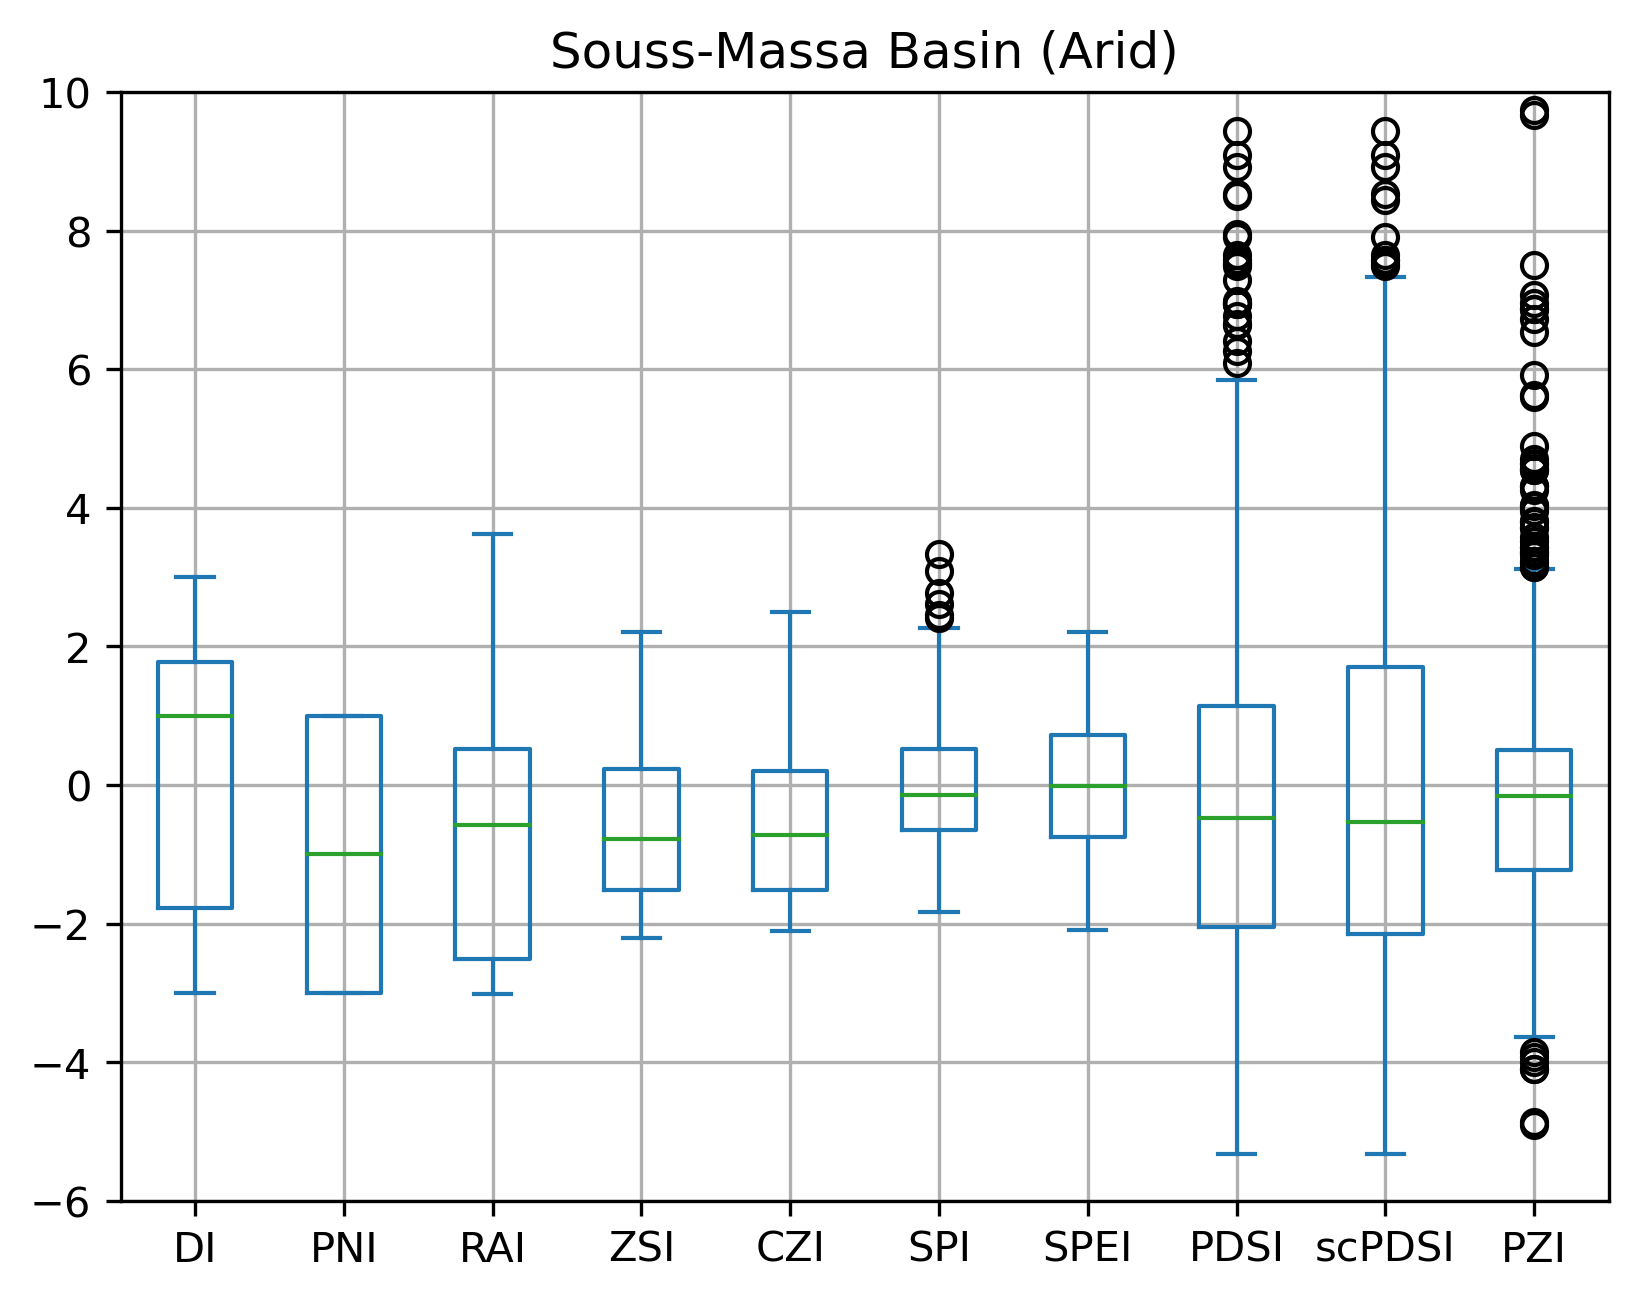

In [131]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
DI_souss.plot(kind='box', title='Souss-Massa Basin (Arid)', grid = True, ylim = (-6, 10))

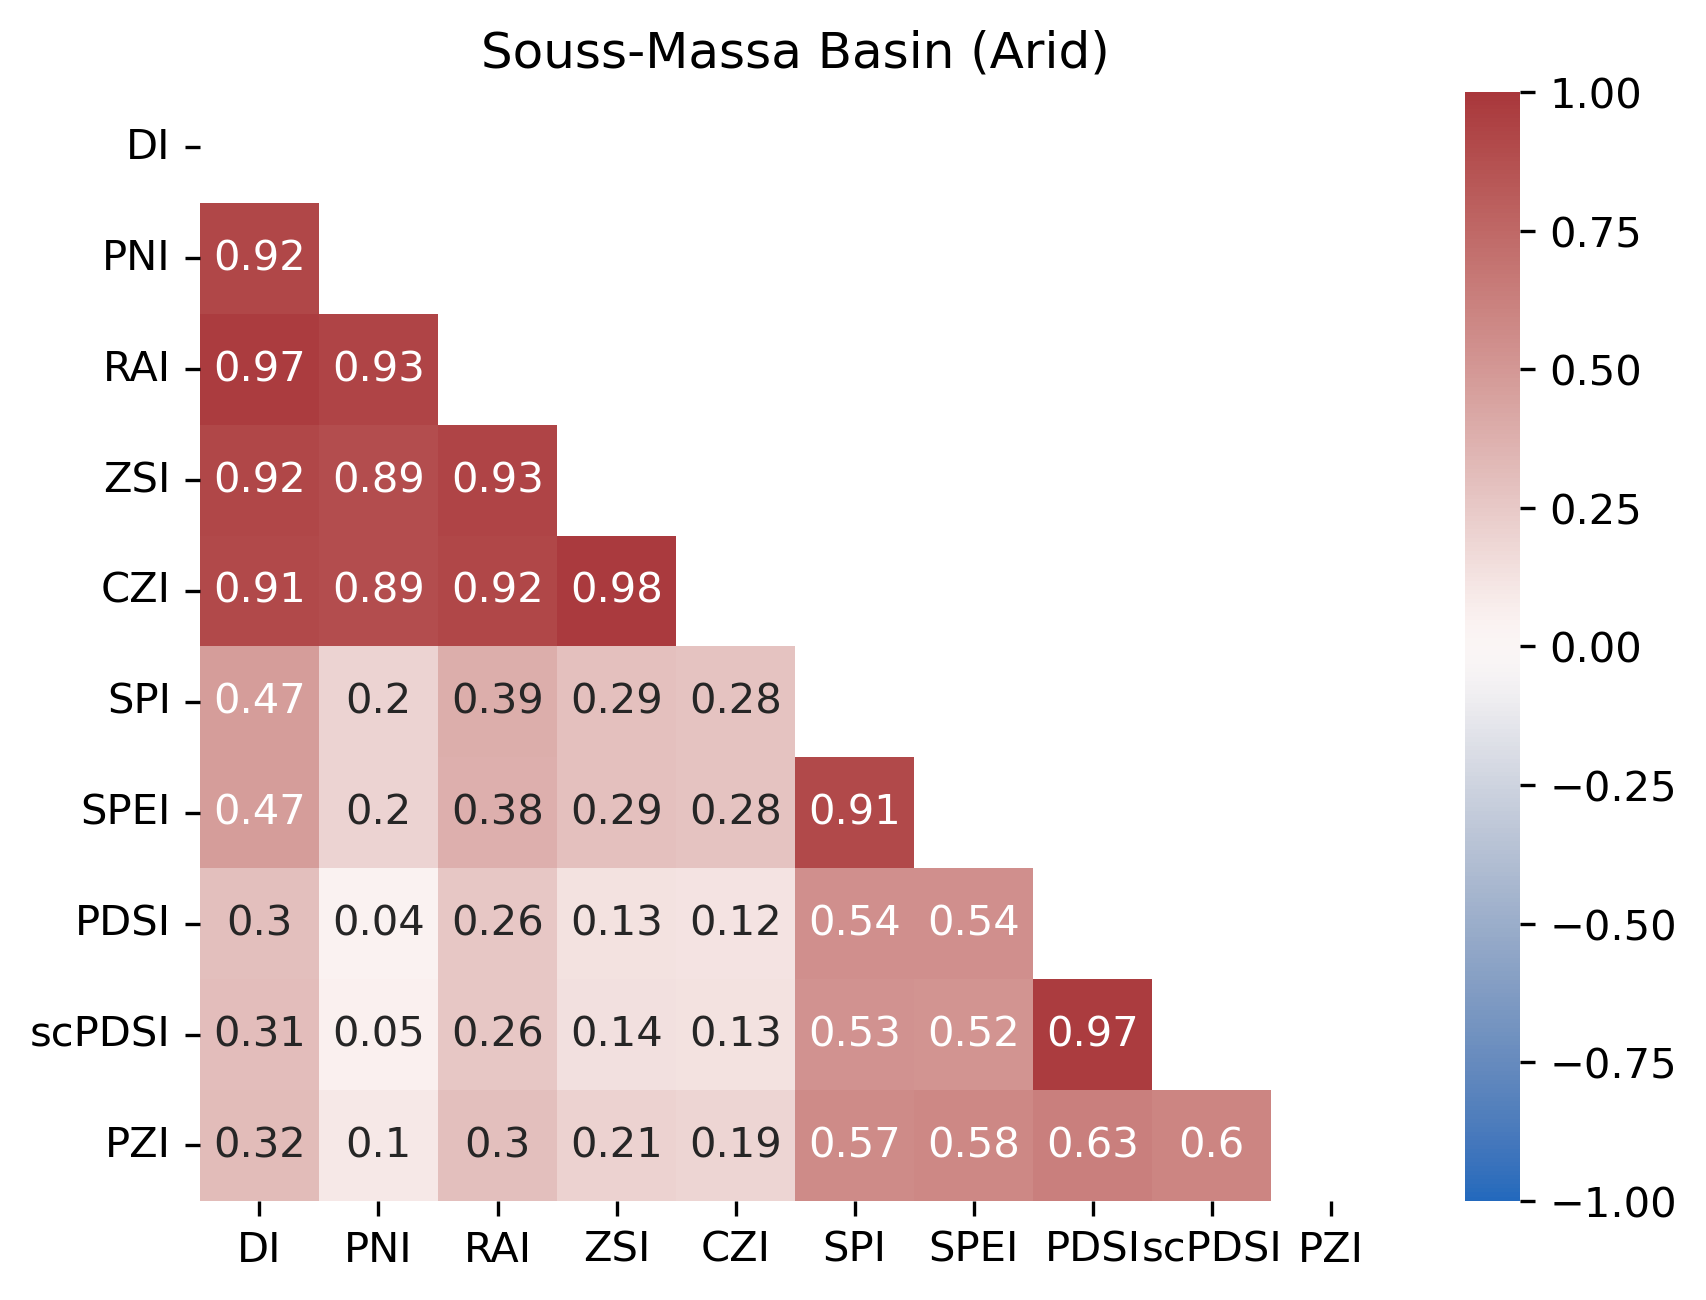

In [130]:
#DI_souss = DI_souss.drop(['Dates'], axis=1)
#DI_souss.replace([np.inf, -np.inf], np.nan, inplace=True)
#DI_souss.dropna()
#pvalue = calculate_pvalues(DI_souss)
matrix = DI_souss.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
#pvalue = pvalue.astype(float).round(3)
#sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Souss-Massa Basin (Arid)")
plt.show()

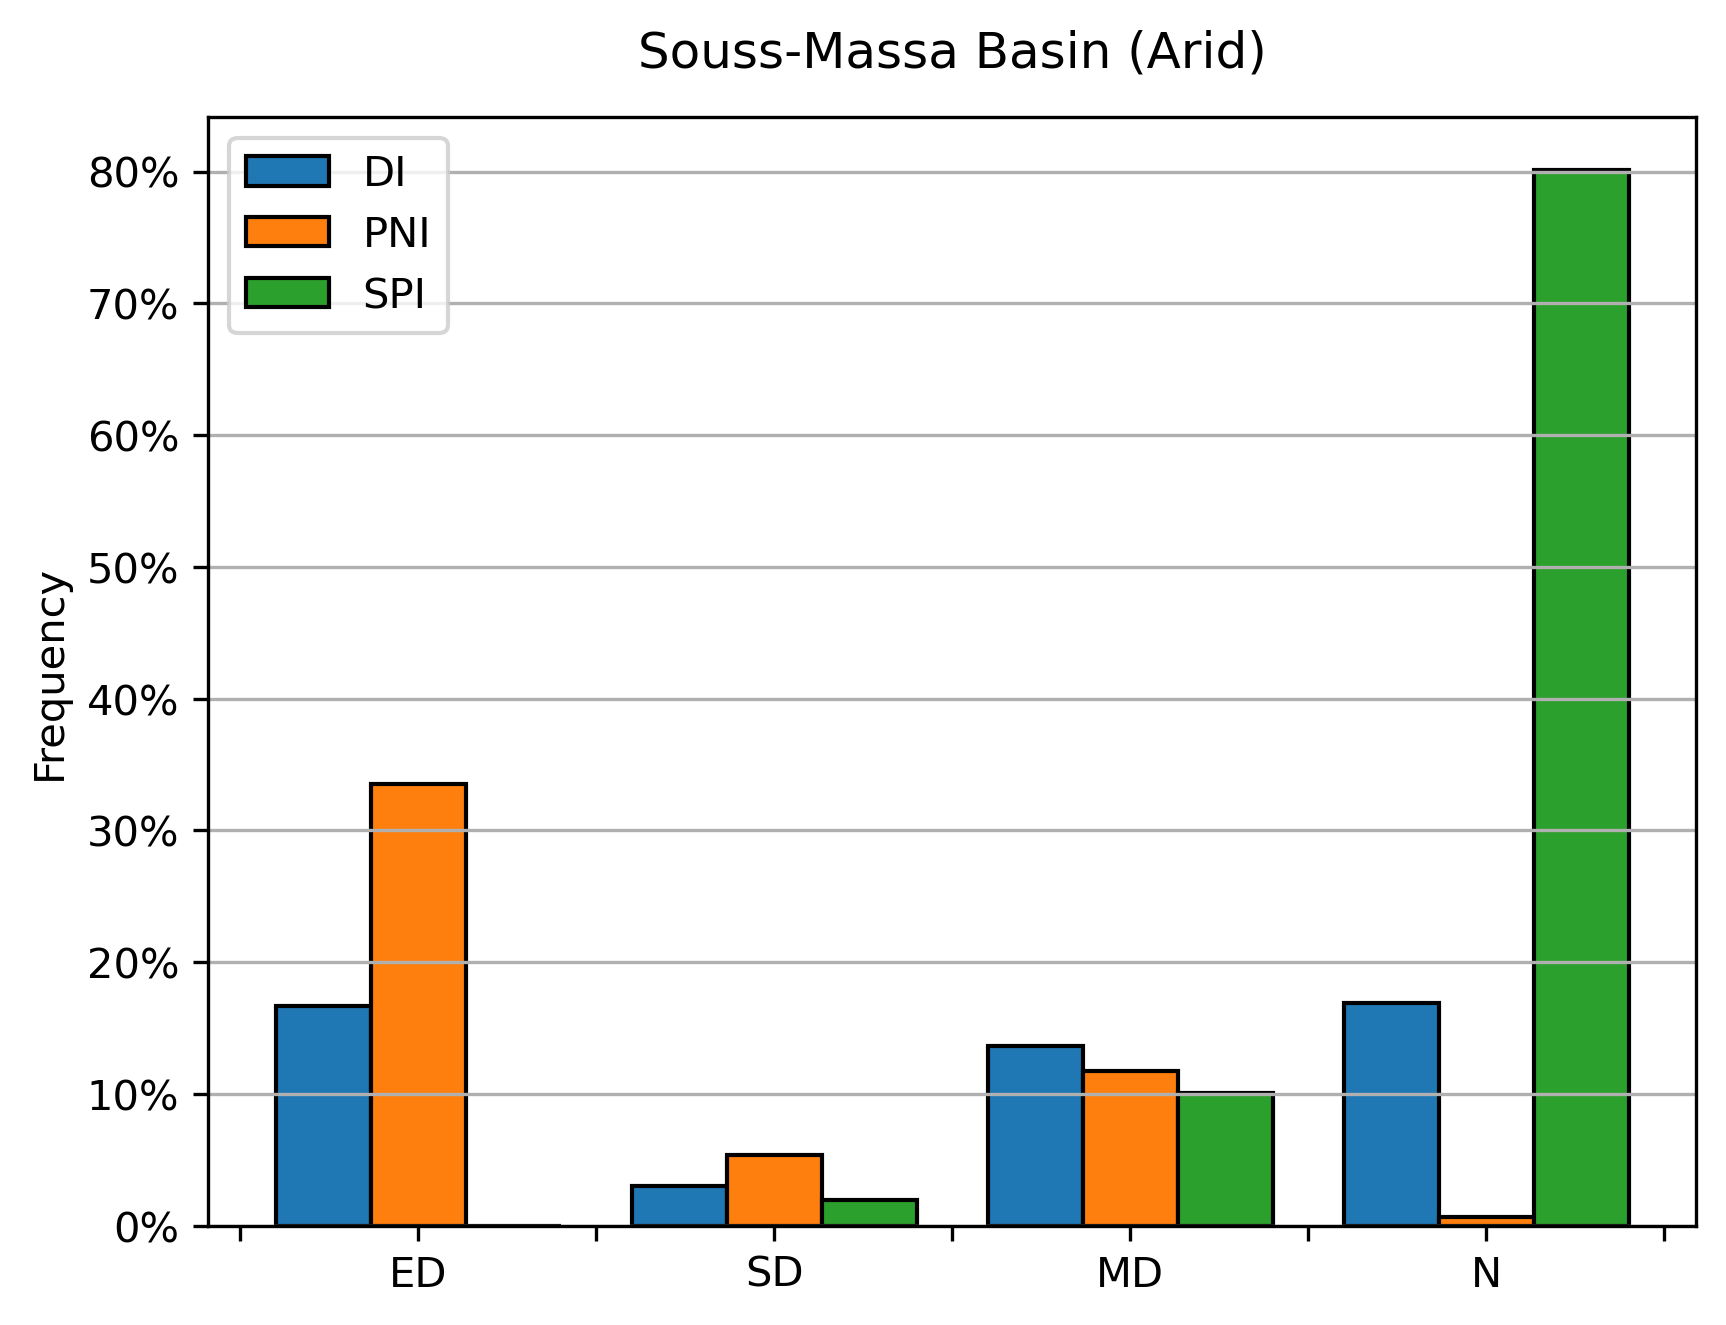

In [134]:
#create relative frequency histogram with percentages on y-axis
data = DIc_souss[['DI', 'PNI', 'SPI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['DI', 'PNI', 'SPI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.grid(axis='y')
ax.set_title('Souss-Massa Basin (Arid)', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [97]:
DI_souss.set_index("Dates", inplace = True)
#DI_souss.index = pd.to_datetime(DI_souss.index, format='%d/%m/%Y')

In [ ]:

data = DI_souss
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Souss-Massa basin')
axs[0].plot(data.index, data['RAI'], label='RAI')
#axs[0].axhline(y=-3, color='r')
axs[0].legend()
axs[1].plot(data.index, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(data.index, data['SPEI'], label='SPEI')
axs[2].legend()

for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_souss
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

In [82]:
DI_souss[394:398]

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
394,01-11-15,1.111111,1.000000,0.320526,0.201191,0.201194,0.372054,0.484609,-0.830882,2.218544,-2.492647
395,01-12-15,1.000000,1.000000,0.183738,0.063602,0.063603,-0.304685,-0.605585,-1.804146,-0.380688,-3.176534
396,01-01-16,-1.222222,-2.888889,-2.367723,-0.811759,-0.811815,-2.011692,-2.247895,-2.541254,-2.277420,-2.768806
397,01-02-16,NaN,-1.000000,-0.989548,-0.106266,-0.106268,-0.712400,-1.138457,-2.459046,-2.378374,-0.538622


<Axes: title={'center': 'Time series of Drought Indices in Souss-Massa basin during 2014-2016 drought spell'}, xlabel='Months', ylabel='value of SPI, SPEI and RAI'>

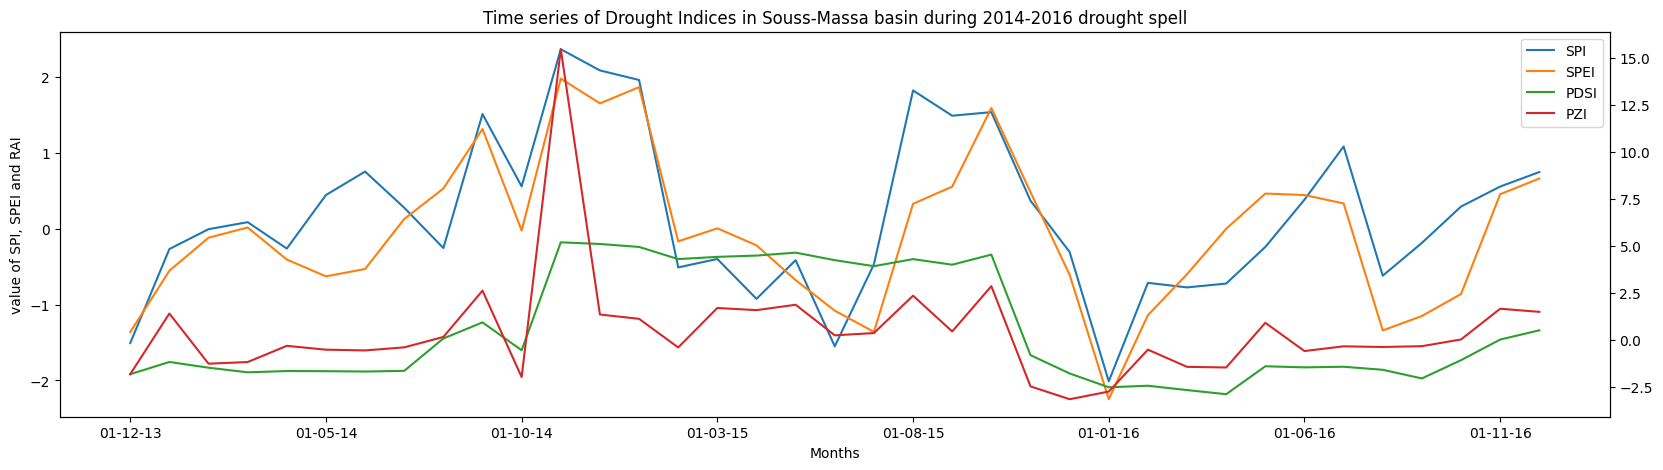

In [109]:
DI_souss[371:408].loc[:,['SPI','SPEI','PDSI','PZI']].plot(secondary_y=['PDSI', 'PZI'], mark_right=False, figsize = (20,5), xlabel='Months', ylabel='value of SPI, SPEI and RAI', title='Time series of Drought Indices in Souss-Massa basin during 2014-2016 drought spell')

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.9229050934914809, z=0.09677498028887276, Tau=0.012145748987854251, s=9.0, var_s=6833.666666666667, slope=0.000677733879624054, intercept=-0.7764194526707096)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.9421393594576422, z=0.07258123521665456, Tau=0.009446693657219974, s=7.0, var_s=6833.666666666667, slope=0.0006807934656672203, intercept=0.04461164978500638)
SPEI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.30956401229803676, z=-1.0161372930331638, Tau=-0.11470985155195682, s=-85.0, var_s=6833.666666666667, slope=-0.009572201082826184, intercept=0.14685611334422932)
scPDSI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.2358223797536274, z=-1.1854935085386913, Tau=-0.13360323886639677, s=-99.0, var_s=6833.666666666667, slope=-0.039427024976286446, intercept=0.45602344558600066)
PZI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.6284746536839203, z=-0.4838749014443638, Tau=-0.0553306342780027, s=-41.0, v

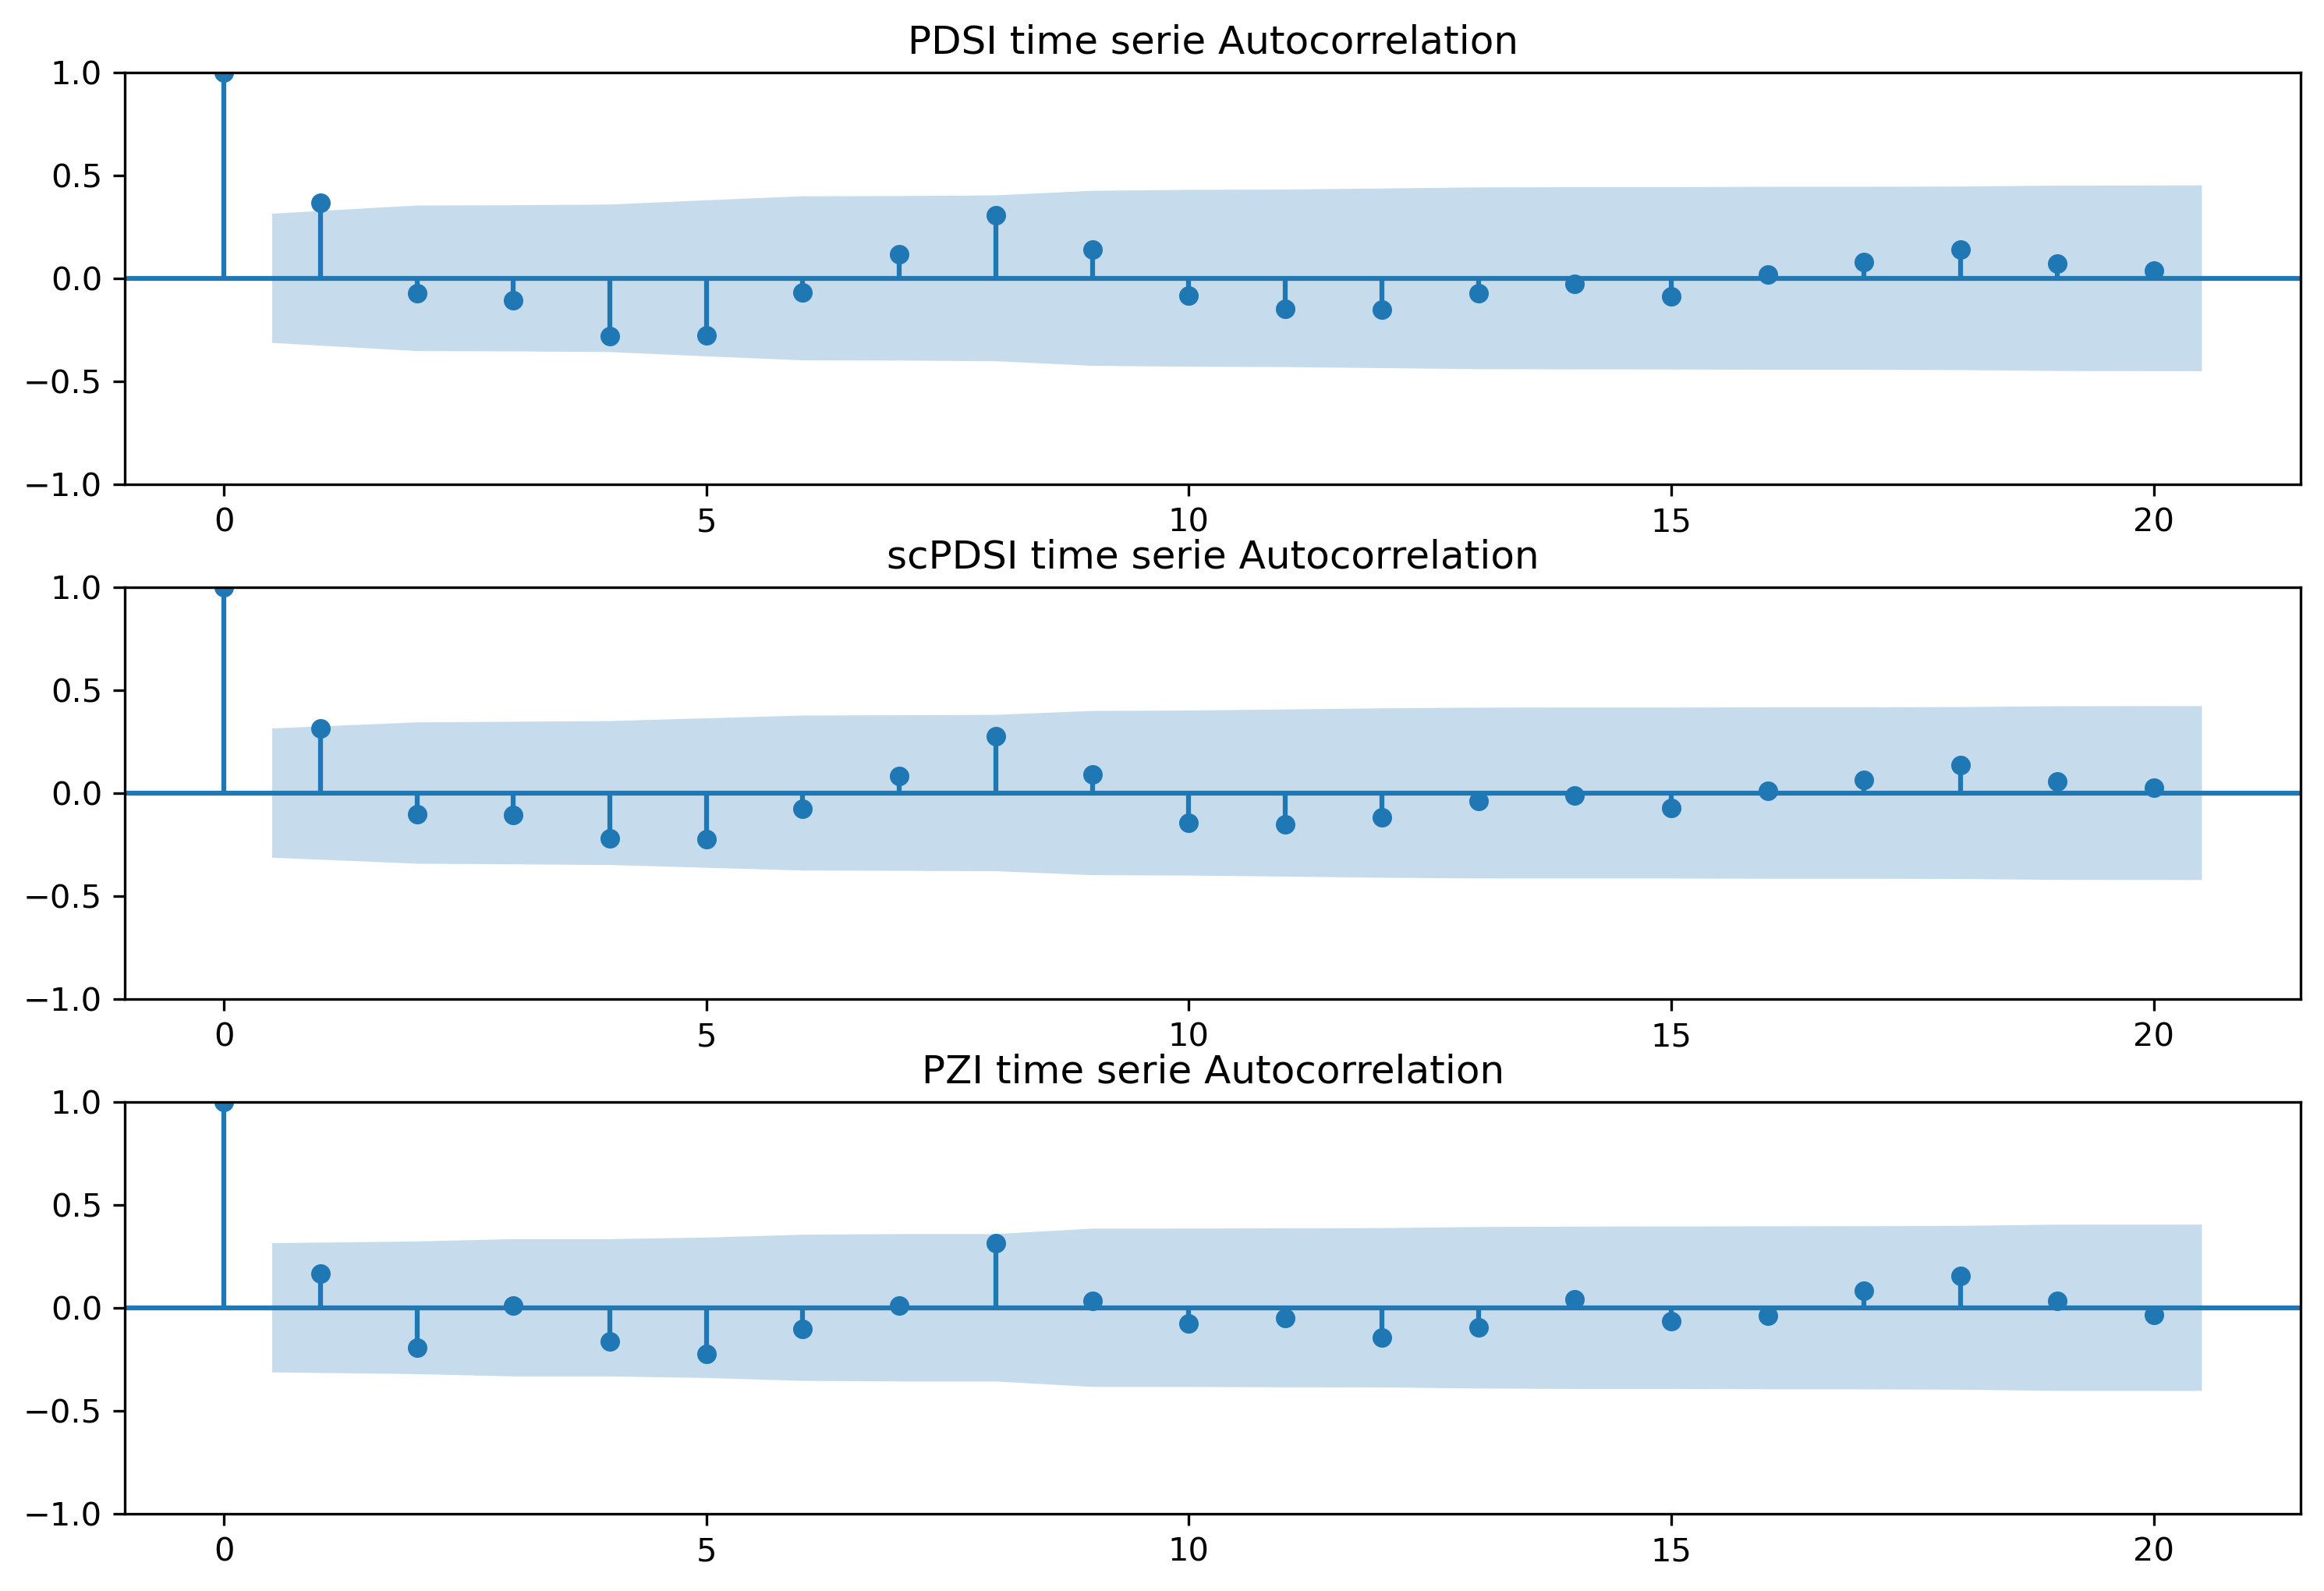

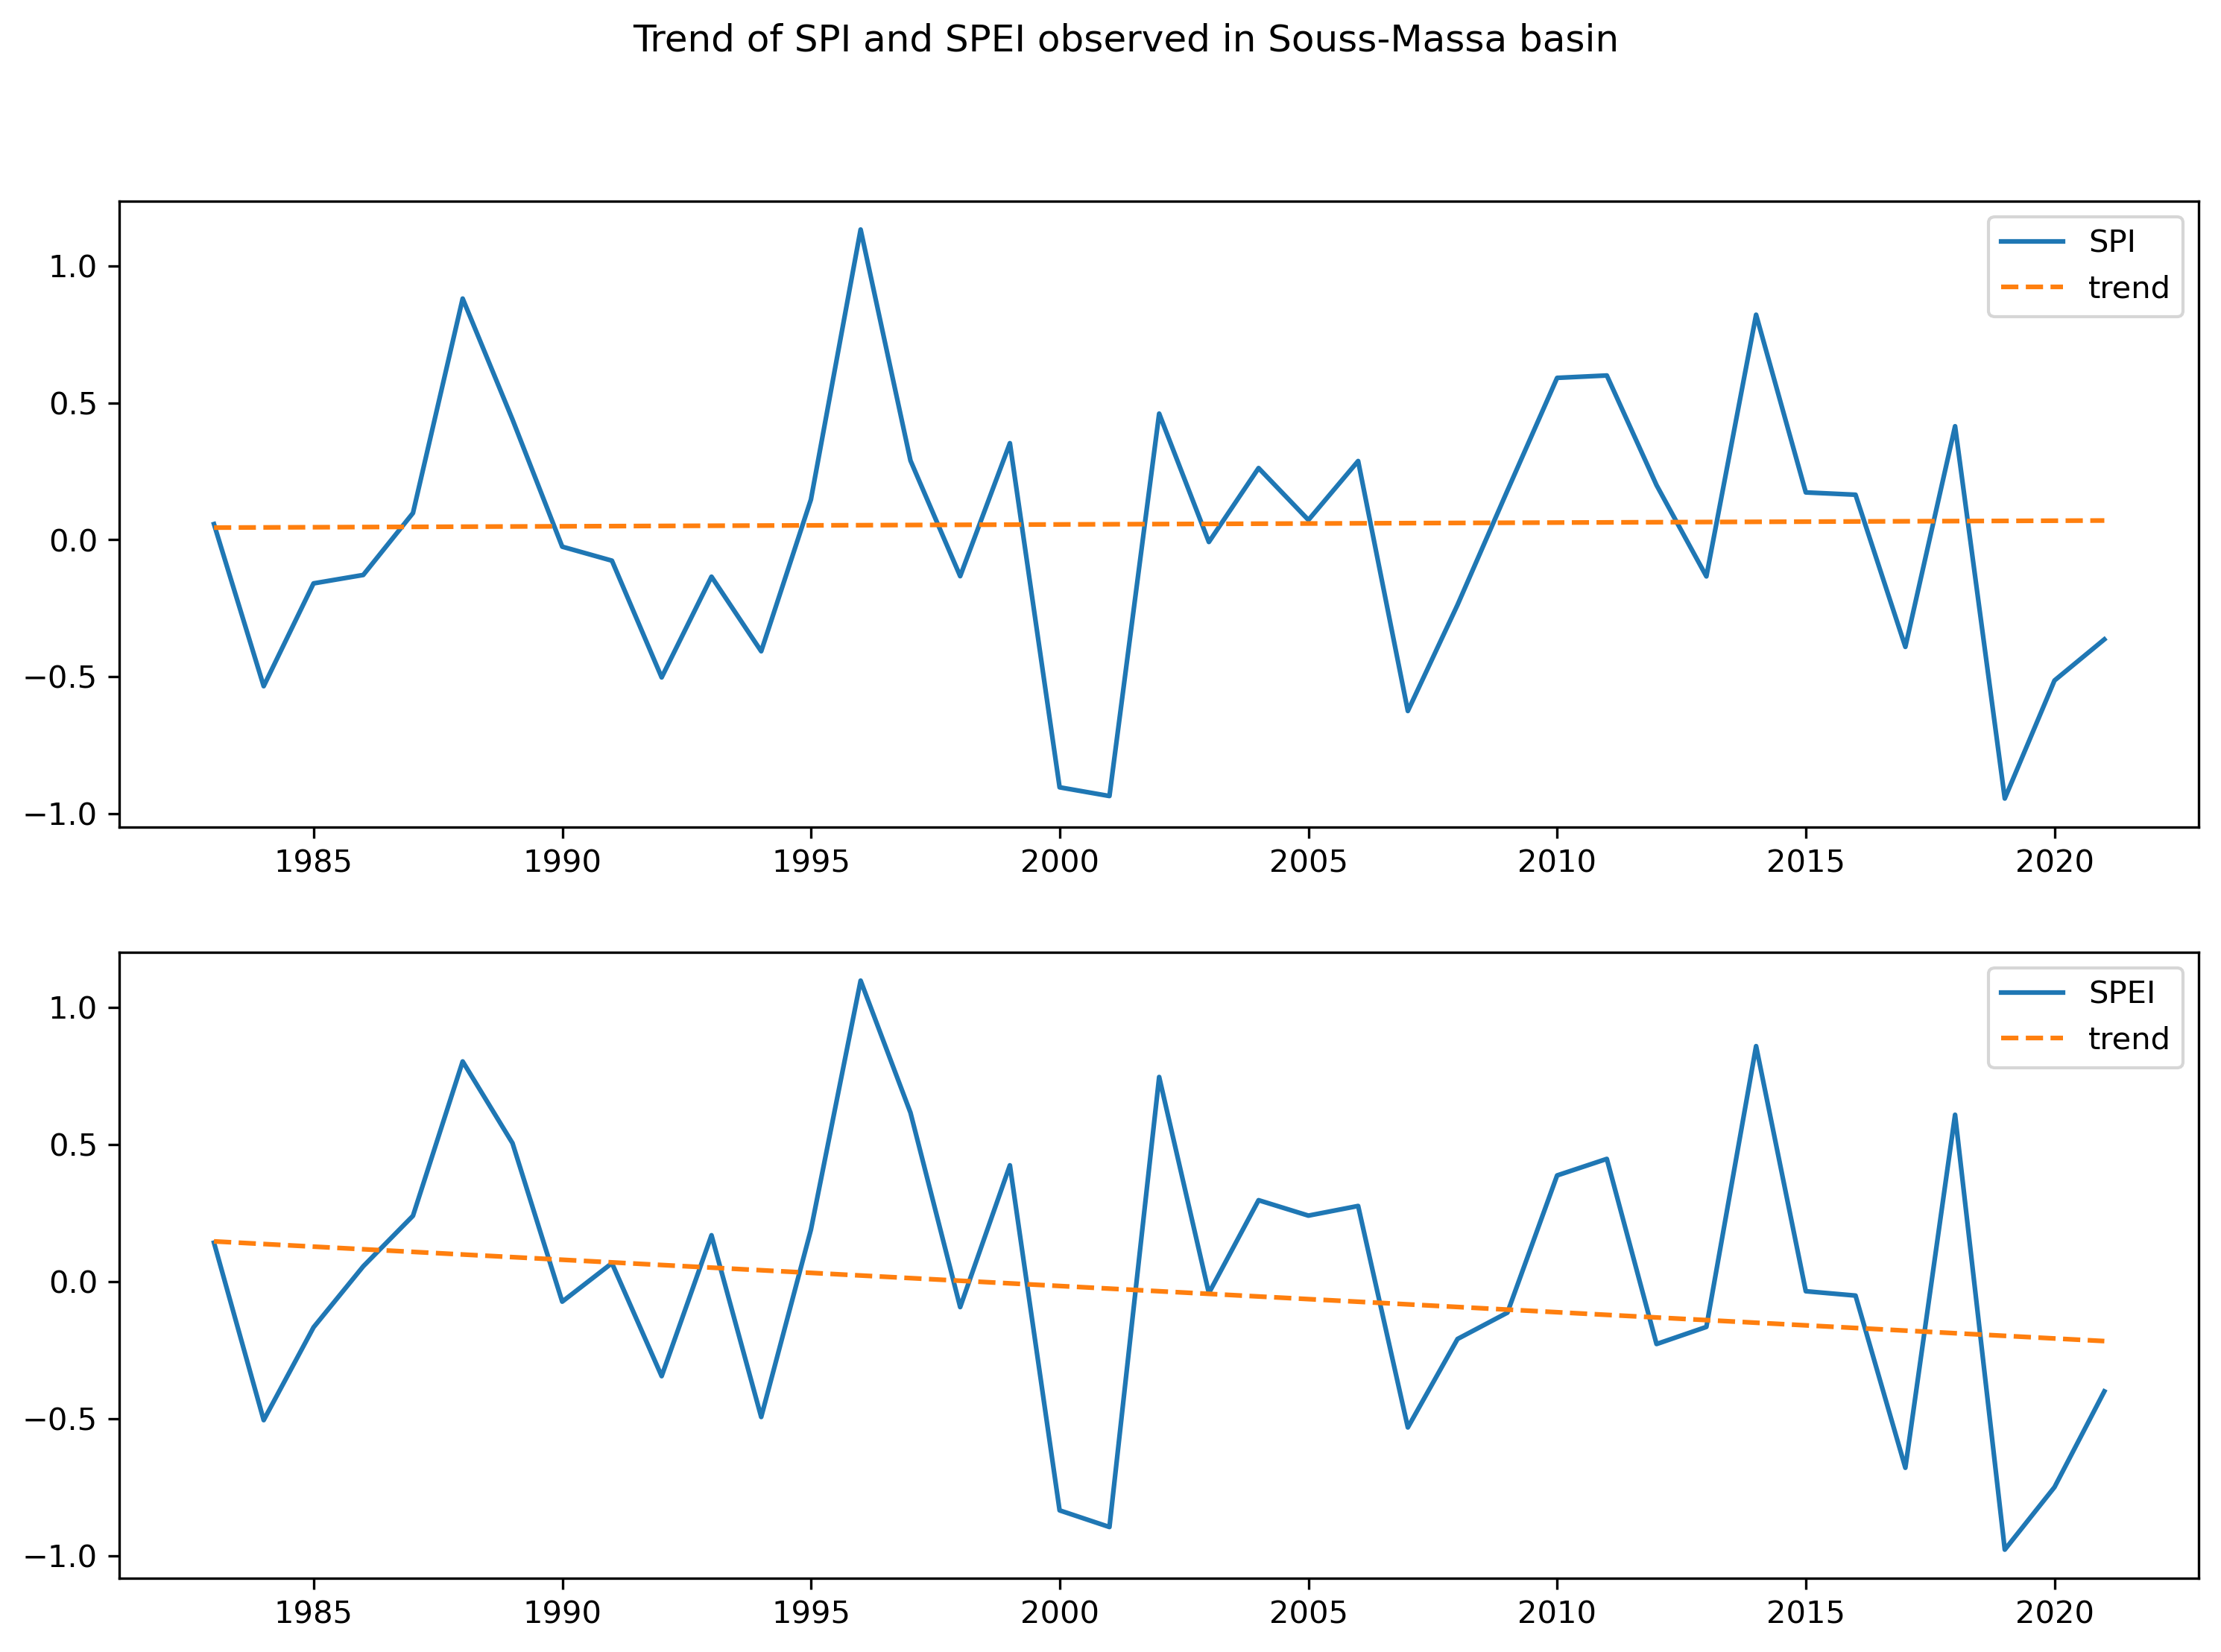

In [135]:
#trend analysis of spi and spei
arai = [np.nansum(DI_souss['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_souss['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_souss['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_souss['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_souss['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_souss['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()


datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Souss-Massa basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

#plt.show()

In [ ]:
DIc_souss = pd.DataFrame()
DIc_souss['Dates'] = DI_souss['Dates']
#DIc_sebou['DI'] = DI_sebou['DI'].round(0)

index = DI_souss['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['DI'] = ic

DIc_souss['PNI'] = DI_souss['PNI'].round(0)

index = DI_souss['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i <= 3 : ic.append(2)
    elif 3 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['RAI'] = ic

index = DI_souss['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['ZSI'] = ic

index = DI_souss['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['CZI'] = ic

index = DI_souss['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPI'] = ic

index = DI_souss['SPEI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPEI'] = ic

index = DI_souss['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PDSI'] = ic

index = DI_souss['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['scPDSI'] = ic

index = DI_souss['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PZI'] = ic
DIc_souss

(67, 72)


<Figure size 1920x1440 with 0 Axes>

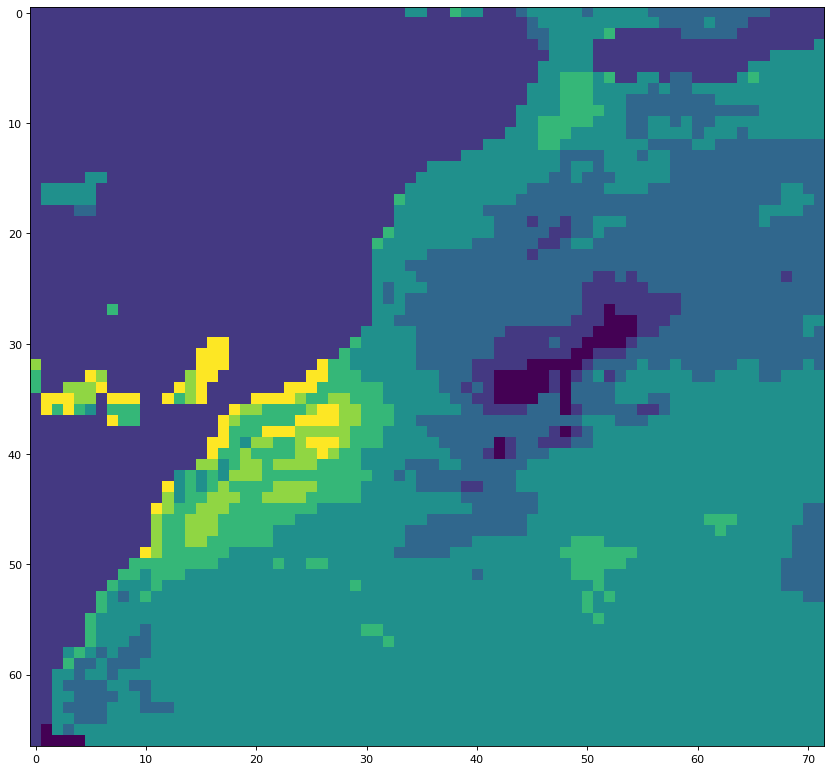

In [212]:
#shp = []
#for i in range(4824):
#    if i in pop : shp.append(1)
#    else: shp.append(0)
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
index = pd.read_csv('outputchirps/PalmerZ.csv', low_memory=False)
index = index.drop(['Unnamed: 0'], axis=1)
#index = index.drop(['Dates'], axis=1)
index = index.values.tolist()

I = np.array(index[397]) #142-6 is Nov 94-Feb 95 #204-7 is Jan-Apr of the year 2000 #394-397 is Nov 2015-Feb 2016
I = np.reshape(I, (-1, 72))
#I = I*shp
#I[I == 0] = -99
I = I.flatten()
ic = []
for i in I:
    if i == -99: 
        ic.append(-5)
        continue
    elif i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
 
NI = np.reshape(np.array(ic), (-1, 72))
print(NI.shape)
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.imshow(NI)

In [213]:
# export
driver = gdal.GetDriverByName("GTiff")
driver.Register()
outds = driver.Create("outputchirps/PZI_397.tif", xsize = NI.shape[1],
                      ysize = NI.shape[0], bands = 1, 
                      eType = gdal.GDT_Float32)

# Specify raster location through geotransform array
# (uperleftx, scalex, skewx, uperlefty, skewy, scaley)
# Scale = size of one pixel in units of raster projection
# this example below assumes 100x100
gt = [-17.875, 0.25, 0, 37.125, 0, -0.25]
outds.SetGeoTransform(gt)

# Get raster projection
epsg = 4326
srs = osr.SpatialReference()
srs.ImportFromEPSG(epsg)
proj = srs.ExportToWkt()
outds.SetProjection(proj)

outband = outds.GetRasterBand(1)
outband.WriteArray(NI)
outband.SetNoDataValue(np.nan)
outband.FlushCache()

# close your datasets and bands!!!
outband = None
outds = None

In [895]:
DI_sebou

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
1983-01-01,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.933192,-0.933192,-2.799576
1983-02-01,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.123539,1.123539,3.370617
1983-03-01,1.100000,1.000000,0.228651,0.848568,0.848554,-0.206007,-0.119493,-0.645141,-0.458213,-1.763763
1983-04-01,1.470588,1.000000,0.543788,1.216664,1.216132,0.274592,0.390407,-0.904982,-0.835710,-0.978870
1983-05-01,-1.000000,-1.000000,-1.292413,-0.164539,-0.164541,-1.056914,-0.571797,-0.956656,-0.895518,-0.434661
...,...,...,...,...,...,...,...,...,...,...
2021-08-01,-3.000000,-3.000000,-2.879971,-1.151832,-1.151625,-0.535858,0.231045,-0.899669,-0.290673,-0.436939
2021-09-01,-3.000000,-3.000000,-2.800253,-1.112160,-1.112024,-0.795722,-0.307710,-1.188361,-0.918078,-0.983365
2021-10-01,-2.444444,-3.000000,-2.597315,-1.015230,-1.015203,-1.772584,-1.187626,-1.971561,-1.939648,-2.716804


In [913]:
tist = DI_sebou[DI_sebou['SPI'].isnull()]
DI_tensift['PZI'].isnull().sum()

In [914]:
tist

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
1983-01-01,NaN,1.0,NaN,NaN,NaN,NaN,NaN,-0.933192,-0.933192,-2.799576
1983-02-01,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.123539,1.123539,3.370617
1990-02-01,NaN,1.0,NaN,NaN,NaN,NaN,-0.550969,4.360787,4.360787,3.188410
1990-03-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.150138,3.659418,3.312716,-0.756626
1990-04-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.486620,4.223176,4.223176,2.822034
1992-02-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.359395,-2.048629,-2.233503,-1.904806
1992-03-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.337547,0.008757,-1.302966,0.848345
1992-04-01,NaN,1.0,NaN,NaN,NaN,NaN,-1.584105,0.727674,0.286403,1.962314


In [909]:
DI_tensift['PZI'].isnull().sum()

0

In [908]:
DI_souss['PZI'].isnull().sum()

0